# Improving RTE's National Electricity Demand Forecasts: 41% Lower MAPE and 26% Narrower Prediction Intervals

## Project Overview

This project investigates **day-ahead hourly electricity demand forecasting in France**, with the objective of improving the forecasts published by the French transmission system operator, RTE.

Accurate electricity demand forecasts are essential for electricity system planning, production scheduling, and maintaining the balance between electricity supply and demand.

Rather than relying exclusively on standalone forecasting models, this study explores a **forecast error-correction approach**: using machine learning to identify and correct systematic errors in existing RTE predictions.

The project compares classical statistical models, gradient-boosted decision trees, and hybrid forecasting approaches under a consistent operational forecasting protocol.

### Forecasting Objective

Every day **D at 11:00 AM (Europe/Paris)**, the objective is to forecast national electricity demand for the following calendar day **D+1**, represented by 24 French local clock-hour slots (00:00–23:00).

Three methodological principles guide the forecasting process:

- **Business time — Europe/Paris:** forecast origins, target days, holidays, and calendar-related features follow French local time.
- **Technical time — UTC:** observations, historical lags, and forecast alignment use UTC timestamps to preserve temporal consistency.
- **Information availability:** historical features must be available strictly before the forecast origin to avoid data leakage.

Daylight saving time transitions are explicitly handled: nonexistent local hours are excluded, while repeated hours follow a consistent convention to preserve the 24-slot forecasting framework.

The methodology also assumes that the corresponding RTE D+1 forecasts are available at the operational forecast origin.

### Experimental Design

The dataset includes historical national electricity demand, RTE day-ahead forecasts, temperature observations, and engineered temporal features.

A chronological split is used to preserve the temporal ordering of observations.

| Dataset | Period | Purpose |
|---|---|---|
| Training | 2019–2024 | Model training and feature engineering |
| Hyperparameter tuning | Train: 2019–2023; evaluate: 2024 | Chronological model optimization |
| Validation | 2025 | Model comparison and selection |
| Conformal calibration | January–June 2025 | Estimation of hour-specific prediction interval margins |
| Conformal evaluation | July–December 2025 | Validation of uncertainty calibration |
| Held-out test | January–June 2026 | Final out-of-sample performance assessment |

The primary evaluation metrics are **MAPE, MAE, and RMSE**, complemented by prediction interval coverage, interval width, residual diagnostics, and forecasting failure rates.

### Key Results — Held-Out Test Set (2026)

The optimized **RTE + LightGBM** model achieves substantial improvements over the original RTE D+1 forecasts across 4,343 evaluated hourly observations.

| Metric | RTE D+1 | RTE + LightGBM | Relative Improvement |
|---|---:|---:|---:|
| MAPE (%) | 2.99 | 1.77 | +40.75% |
| Empirical Coverage (%) | 93.51 | 95.12 | +1.72% |
| Average Prediction Interval Width (MW) | 6,232.96 | 4,624.74 | +25.80% |
| Interval Failure Rate (%) | 6.49 | 4.88 | +24.82% |
| Point Failure Rate (APE > 5%) | 16.33 | 2.21 | +86.46% |

Both models use **hourly conformal prediction intervals targeting 95% marginal coverage**, calibrated on historical forecasting errors.

**Main finding:** the LightGBM correction reduces forecasting MAPE by approximately 41%, while producing 26% narrower prediction intervals with empirical coverage closer to the nominal 95% target. It also substantially reduces the frequency of large forecasting errors.

These results demonstrate improved out-of-sample performance over the evaluated six-month test period, although residual temporal dependencies and broader generalization remain subjects for further investigation.

---

# Notebook Structure

## 0. Data Loading & Quality Assessment

- Data loading, integration, and timestamp normalization
- Temporal integrity and missing-value assessment
- UTC versus Europe/Paris time-zone strategy
- Daylight saving time conventions
- Operational forecast origin and target-window definition

## 1. Exploratory Data Analysis & Temporal Splitting

- Electricity demand distributions and descriptive statistics
- Daily, weekly, and annual seasonality
- Rolling averages and long-term consumption trends
- Temperature sensitivity and extreme-temperature periods
- Temporal autocorrelation and dependence
- Chronological training, validation, and test splits

## 2. Baseline Forecasting & RTE Benchmark

- Naive and seasonal naive forecasting
- RTE D+1 operational benchmark
- Day-ahead walk-forward evaluation
- Forecast accuracy comparison using MAPE, MAE, and RMSE

## 3. Statistical Forecasting Models

- Box–Jenkins methodology and stationarity diagnostics
- ARIMA and SARIMA forecasting
- SARIMAX with heating and cooling degree indicators
- Holt–Winters exponential smoothing
- Statistical prediction intervals and empirical coverage
- Comparative performance assessment and methodological limitations

## 4. Machine Learning — LightGBM

### 4.1 — Feature Engineering

- French calendar scoring and weighted calendar features
- Historical electricity demand lags (48h and 168h)
- Temperature lags and heating/cooling indicators
- RTE day-ahead forecast and historical forecast-error features
- Training-only standardization
- Construction of alternative feature configurations

### 4.2 — Direct LightGBM

- Shared LightGBM training methodology
- Detailed, aggregated, and weighted calendar representations
- Direct hourly demand forecasting
- Day-ahead walk-forward validation
- Model comparison against RTE and seasonal naive benchmarks

### 4.3 — Trend + LightGBM

- Exponentially weighted moving average (EWMA) trend estimation
- Trend-residual forecasting
- Reconstruction of final electricity demand predictions
- Comparison with direct LightGBM configurations

### 4.4 — RTE Forecast Error Correction

- Learning the residual between observed electricity demand and RTE forecasts
- Raw, standardized, and calendar-enhanced RTE feature configurations
- Reconstruction of corrected day-ahead forecasts
- Comparison across all LightGBM architectures

### 4.5 — Hyperparameter Tuning

- Randomized hyperparameter search
- Chronological tuning on 2019–2023 / 2024
- Optimization based on reconstructed demand MAPE
- Refit of selected configurations on 2019–2024
- Walk-forward validation of optimized models on 2025

### 4.5 bis — Hourly Conformal Prediction

- Model-specific prediction interval calibration
- Hourly absolute residual quantiles
- Calibration on January–June 2025
- Evaluation on July–December 2025
- Coverage and average interval width assessment

### 4.6 — Global Forecasting Model Comparison

- Comparison of statistical, direct, trend-based, and RTE-corrected models
- Evaluation on identical valid validation timestamps
- Selection of the optimized RTE + LightGBM model

## 5. Final Evaluation — RTE vs. Optimized LightGBM

### 5.1 — Prediction Intervals & Forecast Visualization

- Generation of LightGBM forecasts on the held-out 2026 test set
- Hourly conformal prediction intervals calibrated independently for RTE and LightGBM
- Weekly visualization of actual demand, model forecasts, and their prediction intervals
- Comparison of point forecasting accuracy: MAPE, MAE, and RMSE
- Comparison of average prediction interval widths

### 5.2 — Residual Diagnostics

- Residual evolution and distribution of forecasting errors
- Autocorrelation function (ACF) comparison
- Ljung–Box tests at lags 24, 48, and 168
- Investigation of remaining temporal dependence in corrected RTE forecasts
- Potential residual modeling improvements using ARMA-type approaches

### 5.3 — Forecast Failure & Reliability Analysis

- Identification of observations outside the 95% prediction intervals
- Detection of large errors using an APE threshold of 5%
- Comparative visualization of RTE and LightGBM forecasting failures
- Normalized error analysis relative to the 5% tolerance threshold
- Failure-rate assessment over the complete 2026 test period

### 5.4 — Final Statistical Comparison

- Consolidated evaluation of RTE and LightGBM
- Forecast accuracy, empirical coverage, and prediction interval width
- Interval and point failure rates
- Absolute and relative improvements against the RTE benchmark

### 5.5 — Final Conclusions

- Summary of accuracy and reliability improvements
- Evidence of out-of-sample performance on unseen 2026 data
- Remaining residual autocorrelation and statistical limitations
- Operational implications and potential model improvements

## 6. Deep Learning — Multiresolution Transformer

- Multiresolution Transformer architecture
- Historical sequence construction and future calendar inputs
- Day-ahead forecasting with 24 target clock-hour slots
- Multi-resolution temporal attention
- Model training and chronological validation
- Performance comparison with statistical models and LightGBM

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

---
# **0. Data Loading & Quality Checks**


In [3]:
df = pd.read_csv("france_electricity_hourly.csv")

print("Shape:", df.shape)
display(df.head())
display(df.info())

Shape: (65710, 4)


,datetime_utc,load_mw,rte_forecast_d1_mw,temperature_c
0,2019-01-01 00:00:00+0000,60826.0,60838.0,5.85
1,2019-01-01 01:00:00+0000,59786.0,59500.0,6.35
2,2019-01-01 02:00:00+0000,56622.0,56012.0,5.91
3,2019-01-01 03:00:00+0000,53920.0,53300.0,5.70
4,2019-01-01 04:00:00+0000,52972.0,52188.0,5.72


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65710 entries, 0 to 65709
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   datetime_utc        65710 non-null  object 
 1   load_mw             65703 non-null  float64
 2   rte_forecast_d1_mw  65703 non-null  float64
 3   temperature_c       65710 non-null  float64
dtypes: float64(3), object(1)
memory usage: 2.0+ MB


None

---
### **0.1 — Temporal Integrity & Missing Values**

We convert timestamps to UTC and check temporal consistency.

Results:

65,710 hourly observations (2019–June 2026).

No duplicated or missing timestamps.

7 missing values in both load_mw and rte_forecast_d1_mw, occurring during October daylight saving transitions.

Time zone strategy:

UTC: regular hourly spacing for time-series models and lags.

Europe/Paris: calendar features, forecasting deadline (before 12:00), and target hours (D+1).

In [4]:
# Convert datetime and set temporal index
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"], utc=True)

df = df.set_index("datetime_utc").sort_index()
# Temporal audit
print("Start:", df.index.min())
print("End:", df.index.max())
print("Duplicated timestamps:", df.index.duplicated().sum())

expected_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h",
    tz="UTC"
)

print("Expected hours:", len(expected_index))
print("Actual rows:", len(df))
print("Missing timestamps:", len(expected_index.difference(df.index)))

# Missing values
print("\nMissing values per column:")
print(df.isna().sum())

# Rows containing missing values
display(df[df.isna().any(axis=1)])

Start: 2019-01-01 00:00:00+00:00
End: 2026-06-30 21:00:00+00:00
Duplicated timestamps: 0
Expected hours: 65710
Actual rows: 65710
Missing timestamps: 0

Missing values per column:
load_mw               7
rte_forecast_d1_mw    7
temperature_c         0
dtype: int64


,load_mw,rte_forecast_d1_mw,temperature_c
datetime_utc,,,
2019-10-27 00:00:00+00:00,NaN,NaN,15.13
2020-10-25 00:00:00+00:00,NaN,NaN,13.64
2021-10-31 00:00:00+00:00,NaN,NaN,11.86
2022-10-30 00:00:00+00:00,NaN,NaN,14.97
2023-10-29 00:00:00+00:00,NaN,NaN,14.41
2024-10-27 00:00:00+00:00,NaN,NaN,12.97
2025-10-26 00:00:00+00:00,NaN,NaN,8.86


In [5]:
idx = df.index.get_loc("2022-10-30 00:00:00+00:00	")

display(df.iloc[idx-2:idx+3])

,load_mw,rte_forecast_d1_mw,temperature_c
datetime_utc,,,
2022-10-29 22:00:00+00:00,39868.0,37338.0,15.46
2022-10-29 23:00:00+00:00,36837.0,34175.0,14.85
2022-10-30 00:00:00+00:00,NaN,NaN,14.97
2022-10-30 01:00:00+00:00,36126.0,31100.0,14.72
2022-10-30 02:00:00+00:00,31669.0,30612.0,13.97


### **0.2 — Time Zone Strategy: UTC vs. Europe/Paris**

Electricity consumption is strongly influenced by human activity patterns, which follow **local civil time** rather than UTC.

However, daylight saving time (DST) introduces irregularities in the French local clock: one hour disappears in March, while another occurs twice in October.

To illustrate this distinction, we compare the normalized hourly electricity demand profiles for **winter (January–February)** and **summer (June–July)** on weekdays in 2024, using both UTC and French local time.


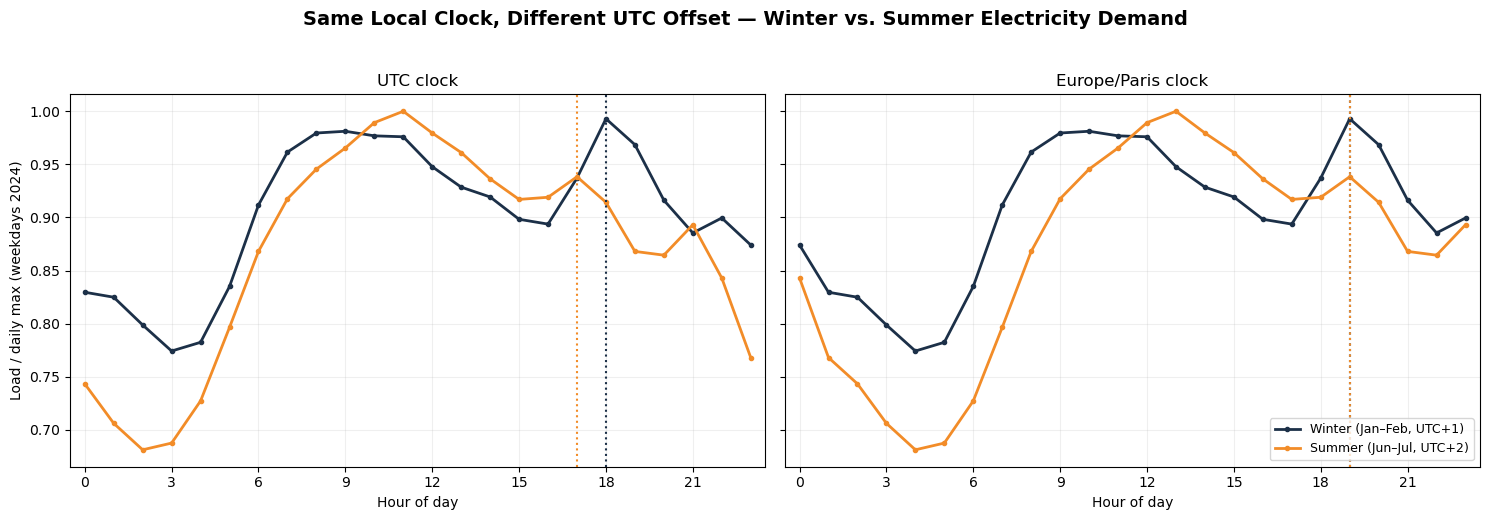

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare French calendar features
tz_data = df[["load_mw"]].copy()
tz_data["datetime_fr"] = tz_data.index.tz_convert("Europe/Paris")
tz_data["date_fr"] = tz_data["datetime_fr"].dt.date
tz_data["hour_utc"] = tz_data.index.hour
tz_data["hour_fr"] = tz_data["datetime_fr"].dt.hour
tz_data["month_fr"] = tz_data["datetime_fr"].dt.month
tz_data["year_fr"] = tz_data["datetime_fr"].dt.year
tz_data["weekday_fr"] = tz_data["datetime_fr"].dt.dayofweek

# Select 2024 weekdays and normalize by daily maximum
tz_data = tz_data[(tz_data["year_fr"] == 2024) & (tz_data["weekday_fr"] < 5)].dropna(subset=["load_mw"]).copy()
tz_data["normalized_load"] = tz_data["load_mw"] / tz_data.groupby("date_fr")["load_mw"].transform("max")

winter = tz_data[tz_data["month_fr"].isin([1, 2])]
summer = tz_data[tz_data["month_fr"].isin([6, 7])]

# Compute hourly mean profiles
def hourly_profile(data, hour_col):
    return data.groupby(hour_col)["normalized_load"].mean().reindex(range(24))

profiles = {
    clock: {
        "Winter": hourly_profile(winter, hour_col),
        "Summer": hourly_profile(summer, hour_col)
    }
    for clock, hour_col in [("UTC", "hour_utc"), ("Europe/Paris", "hour_fr")]
}

# Plot UTC and French local-time profiles
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
colors = {"Winter": "#1C3048", "Summer": "#F28C28"}

for ax, (clock, profile) in zip(axes, profiles.items()):
    for season, values in profile.items():
        ax.plot(values.index, values, color=colors[season], marker="o", markersize=3,
                linewidth=2, label=f"{season} ({'Jan–Feb, UTC+1' if season == 'Winter' else 'Jun–Jul, UTC+2'})")
    ax.set(title=f"{clock} clock", xlabel="Hour of day", xlim=(-0.5, 23.5))
    ax.set_xticks(range(0, 24, 3))
    ax.grid(alpha=0.2)

# Reference lines: 19:00 French local time
for ax, hour, color in [(axes[0], 18, colors["Winter"]), (axes[0], 17, colors["Summer"]),
                        (axes[1], 19, colors["Winter"]), (axes[1], 19, colors["Summer"])]:
    ax.axvline(hour, color=color, linestyle=":", linewidth=1.5)

axes[0].set_ylabel("Load / daily max (weekdays 2024)")
axes[1].legend(loc="lower right", fontsize=9)
fig.suptitle("Same Local Clock, Different UTC Offset — Winter vs. Summer Electricity Demand",
             fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Why use two time zones?**

The two plots represent the same electricity demand observations under different clock conventions.

- **UTC clock:** a given French local hour corresponds to different UTC hours depending on the season. For example, 19:00 in France corresponds to 18:00 UTC in winter and 17:00 UTC in summer.
- **Europe/Paris clock:** local activity patterns can be compared at consistent civil hours, making this representation more meaningful for calendar-based features.

Seasonal load profiles also differ because of temperature, daylight duration, and economic activity. Time zone conversion does not eliminate these effects; it only ensures that corresponding local hours are correctly aligned.

**Methodological decision:** all observations remain indexed in UTC to ensure unique timestamps and consistent elapsed-time lags (48h, 168h), while calendar-related features are derived from `Europe/Paris`.

This combined approach preserves both **temporal integrity** and **business relevance**, including during daylight saving time transitions.


### **0.3 — Missing Value Treatment & Descriptive Statistics**

We apply time-based linear interpolation to the 7 missing observations to preserve a continuous hourly series.

Save original observations in df_raw.

Interpolate load_mw and rte_forecast_d1_mw.

Exclude originally missing observations from final evaluation.

Inspect descriptive statistics for potential anomalies.

No future information is allowed when generating day-ahead forecasts.

In [7]:
# Preserve original data
df_raw = df.copy()

# Interpolate missing values
cols = ["load_mw", "rte_forecast_d1_mw"]
df[cols] = df[cols].interpolate(method="time")

# French local time for calendar and forecasting logic
df["datetime_fr"] = df.index.tz_convert("Europe/Paris")

# Verify interpolation and inspect descriptive statistics
print(df[cols].isna().sum())
display(df[["load_mw", "rte_forecast_d1_mw", "temperature_c"]].describe())

load_mw               0
rte_forecast_d1_mw    0
dtype: int64


,load_mw,rte_forecast_d1_mw,temperature_c
count,65710.000000,65710.000000,65710.000000
mean,51497.351514,50830.222143,13.071639
std,11018.880178,11048.384887,7.022981
min,29364.000000,27712.000000,-5.090000
25%,43320.000000,42588.000000,7.920000
50%,49767.000000,48962.000000,12.500000
75%,58746.000000,58062.000000,17.980000
max,90210.000000,89975.000000,38.520000


In [8]:
idx = df.index.get_loc("2019-10-27 00:00:00+00:00")

display(df.iloc[idx-1:idx+2])

,load_mw,rte_forecast_d1_mw,temperature_c,datetime_fr
datetime_utc,,,,
2019-10-26 23:00:00+00:00,42172.0,40425.0,15.13,2019-10-27 01:00:00+02:00
2019-10-27 00:00:00+00:00,40558.5,38562.5,15.13,2019-10-27 02:00:00+02:00
2019-10-27 01:00:00+00:00,38945.0,36700.0,14.26,2019-10-27 02:00:00+01:00


--- 
# **1. EDA & Temporal Splitting**


### **1.0 Temporal Splitting**

In [9]:
local = df["datetime_fr"]

train = df.loc[local < pd.Timestamp("2025-01-01", tz="Europe/Paris")].copy()

val = df.loc[
    (local >= pd.Timestamp("2025-01-01", tz="Europe/Paris")) &
    (local < pd.Timestamp("2026-01-01", tz="Europe/Paris"))
].copy()

test = df.loc[
    local >= pd.Timestamp("2026-01-01", tz="Europe/Paris")
].copy()

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Train: (52607, 4)
Validation: (8760, 4)
Test: (4343, 4)


### **1.1 — Exploratory Data Analysis**

We explore the hourly electricity consumption to identify long-term trends, seasonal patterns, and potential anomalies before modeling.

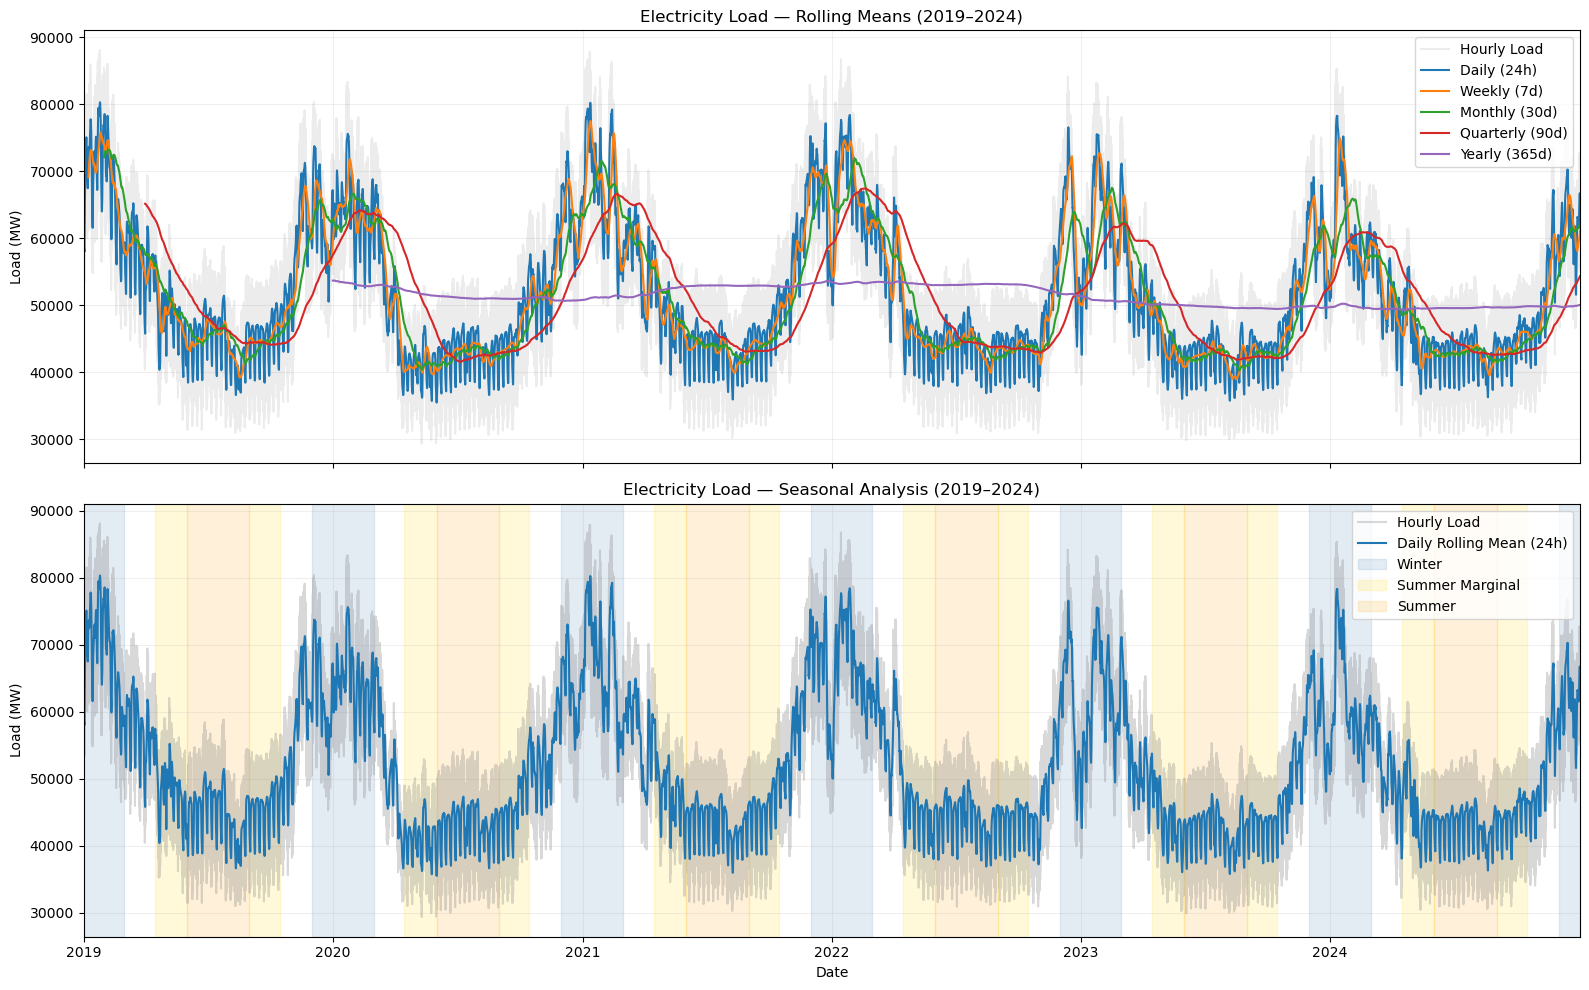

In [10]:
y = train["load_mw"]

windows = {
    "Daily (24h)": 24,
    "Weekly (7d)": 24 * 7,
    "Monthly (30d)": 24 * 30,
    "Quarterly (90d)": 24 * 90,
    "Yearly (365d)": 24 * 365
}

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# GRAPH 1 — Rolling means
ax = axes[0]

ax.plot(y.index, y, alpha=0.15, color="gray", label="Hourly Load")

for label, window in windows.items():
    ax.plot(
        y.index,
        y.rolling(window).mean(),
        label=label,
        linewidth=1.5
    )

ax.set_title("Electricity Load — Rolling Means (2019–2024)")
ax.set_ylabel("Load (MW)")
ax.legend()
ax.grid(alpha=0.2)


# GRAPH 2 — Seasonal analysis
ax = axes[1]

ax.plot(y.index, y, alpha=0.3, color="gray", label="Hourly Load")

ax.plot(
    y.index,
    y.rolling(24).mean(),
    linewidth=1.5,
    label="Daily Rolling Mean (24h)"
)

start_year = train["datetime_fr"].dt.year.min()
end_year = train["datetime_fr"].dt.year.max()

added_labels = set()

for year in range(start_year, end_year + 2):

    seasons = [
        ("Winter", f"{year-1}-12-01", f"{year}-03-01", "steelblue"),
        ("Summer Marginal", f"{year}-04-15", f"{year}-06-01", "gold"),
        ("Summer", f"{year}-06-01", f"{year}-09-01", "orange"),
        ("Summer Marginal", f"{year}-09-01", f"{year}-10-15", "gold"),
    ]

    for season, start, end, color in seasons:

        # Convert French local dates to UTC
        start = pd.Timestamp(start, tz="Europe/Paris").tz_convert("UTC")
        end = pd.Timestamp(end, tz="Europe/Paris").tz_convert("UTC")

        # Avoid duplicate labels
        label = season if season not in added_labels else None

        ax.axvspan(
            start,
            end,
            color=color,
            alpha=0.15,
            label=label
        )

        added_labels.add(season)

ax.set_xlim(y.index.min(), y.index.max())
ax.set_title("Electricity Load — Seasonal Analysis (2019–2024)")
ax.set_xlabel("Date")
ax.set_ylabel("Load (MW)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Comments :** 


-Significant short-term variability: hourly fluctuations are progressively smoothed by larger rolling windows, revealing the underlying seasonal structure.

- Relatively stable long-term level: the yearly rolling mean shows no strong sustained trend, despite some interannual variations.

- Strong annual seasonality: electricity demand peaks during winter, likely driven by heating needs, while summer exhibits significantly lower consumption.
- Refined seasonal interpretation: France's temperate climate suggests that the traditional winter/summer classification may be too simplistic. During late spring and early autumn, temperatures are often mild enough to limit residential heating demand. These Summer Marginal periods appear to share relatively low consumption levels with summer.

This motivates investigating more refined seasonal indicators rather than relying exclusively on calendar seasons.

### **Weekly Analysis**

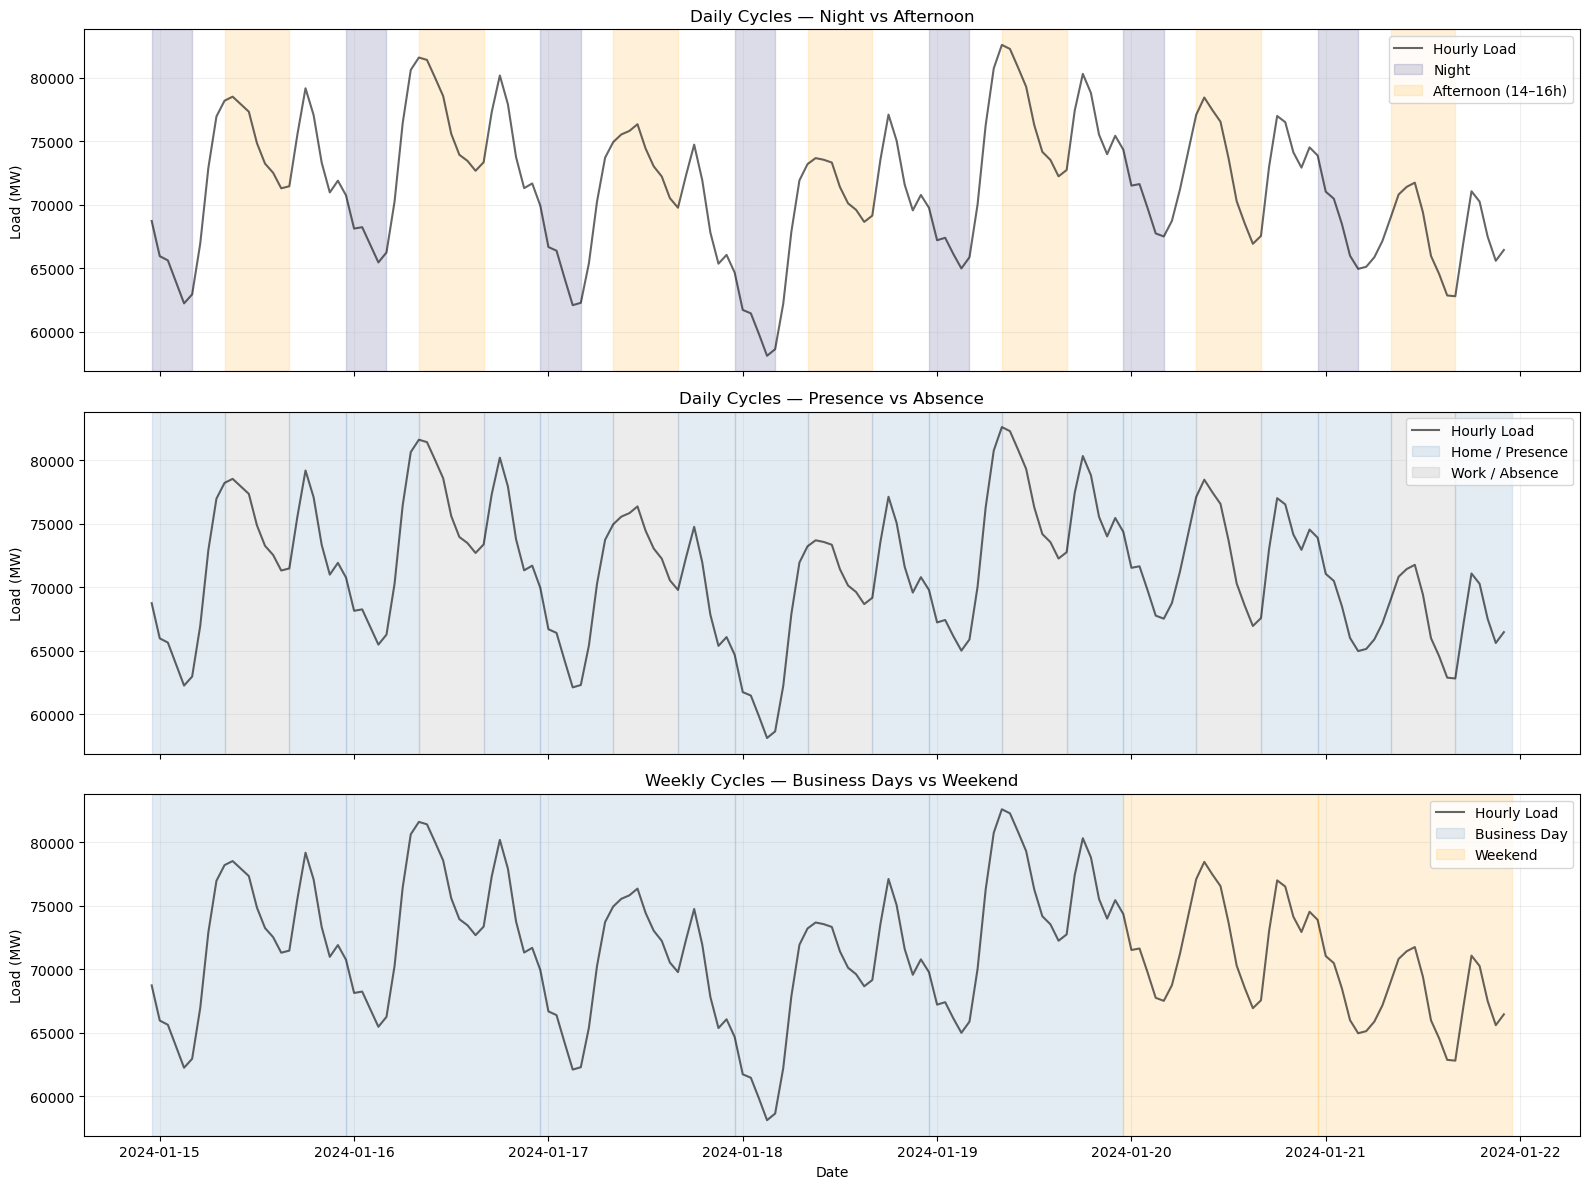

In [11]:
# One week from training data (French local dates)
local = train["datetime_fr"]
week = train.loc[
    (local >= pd.Timestamp("2024-01-15", tz="Europe/Paris")) &
    (local < pd.Timestamp("2024-01-22", tz="Europe/Paris")),
    "load_mw"
]

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

for ax in axes:
    ax.plot(week.index, week, color="black", alpha=0.6, label="Hourly Load")
    ax.set_ylabel("Load (MW)")
    ax.grid(alpha=0.2)

# French local time periods
days = pd.date_range("2024-01-15", periods=7, freq="D", tz="Europe/Paris")

def shade(ax, day, start, end, color, label):
    ax.axvspan(
        (day + pd.Timedelta(hours=start)).tz_convert("UTC"),
        (day + pd.Timedelta(hours=end)).tz_convert("UTC"),
        color=color, alpha=0.15, label=label
    )

for i, day in enumerate(days):

    # Plot 1 — Night and afternoon
    shade(axes[0], day, 0, 5, "midnightblue", "Night" if i == 0 else None)
    shade(axes[0], day, 9, 17, "orange", "Afternoon (14–16h)" if i == 0 else None)

    # Plot 2 — Presence and absence
    shade(axes[1], day, 0, 9, "steelblue", "Home / Presence" if i == 0 else None)
    shade(axes[1], day, 9, 17, "gray", "Work / Absence" if i == 0 else None)
    shade(axes[1], day, 17, 24, "steelblue", None)

    # Plot 3 — Business days vs weekend
    if day.dayofweek < 5:
        shade(axes[2], day, 0, 24, "steelblue",
              "Business Day" if i == 0 else None)
    else:
        shade(axes[2], day, 0, 24, "orange",
              "Weekend" if i == 5 else None)

titles = [
    "Daily Cycles — Night vs Afternoon",
    "Daily Cycles — Presence vs Absence",
    "Weekly Cycles — Business Days vs Weekend"
]

for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

### **Comments**

- **Intraday seasonality:** zooming into a representative week reveals recurring consumption fluctuations, with nighttime troughs and morning/evening peaks. This motivates us to explore peak and off-peak hours, which can be found in the rate plans offered by our electricity providers

- **Presence vs. Activity:** Periods when households are presumed to be absent during business hours partially coincide with a decline in consumption. However, household presence alone does not allow for a clear distinction between peaks and troughs, particularly from evening to morning, when periods of activity and inactivity overlap. Activity-related indicators may therefore prove more relevant than simple presence indicators.

- **Weekdays vs. Weekends:** Based on our assumption regarding occupancy rates, weekends might suggest higher electricity consumption. Surprisingly, the graph shows an overall decline in national demand during weekends, prompting us to explore this widespread decline in the weekday/weekend breakdown. 


### **Quarterly Analysis — Hourly, Daily & Weekly**

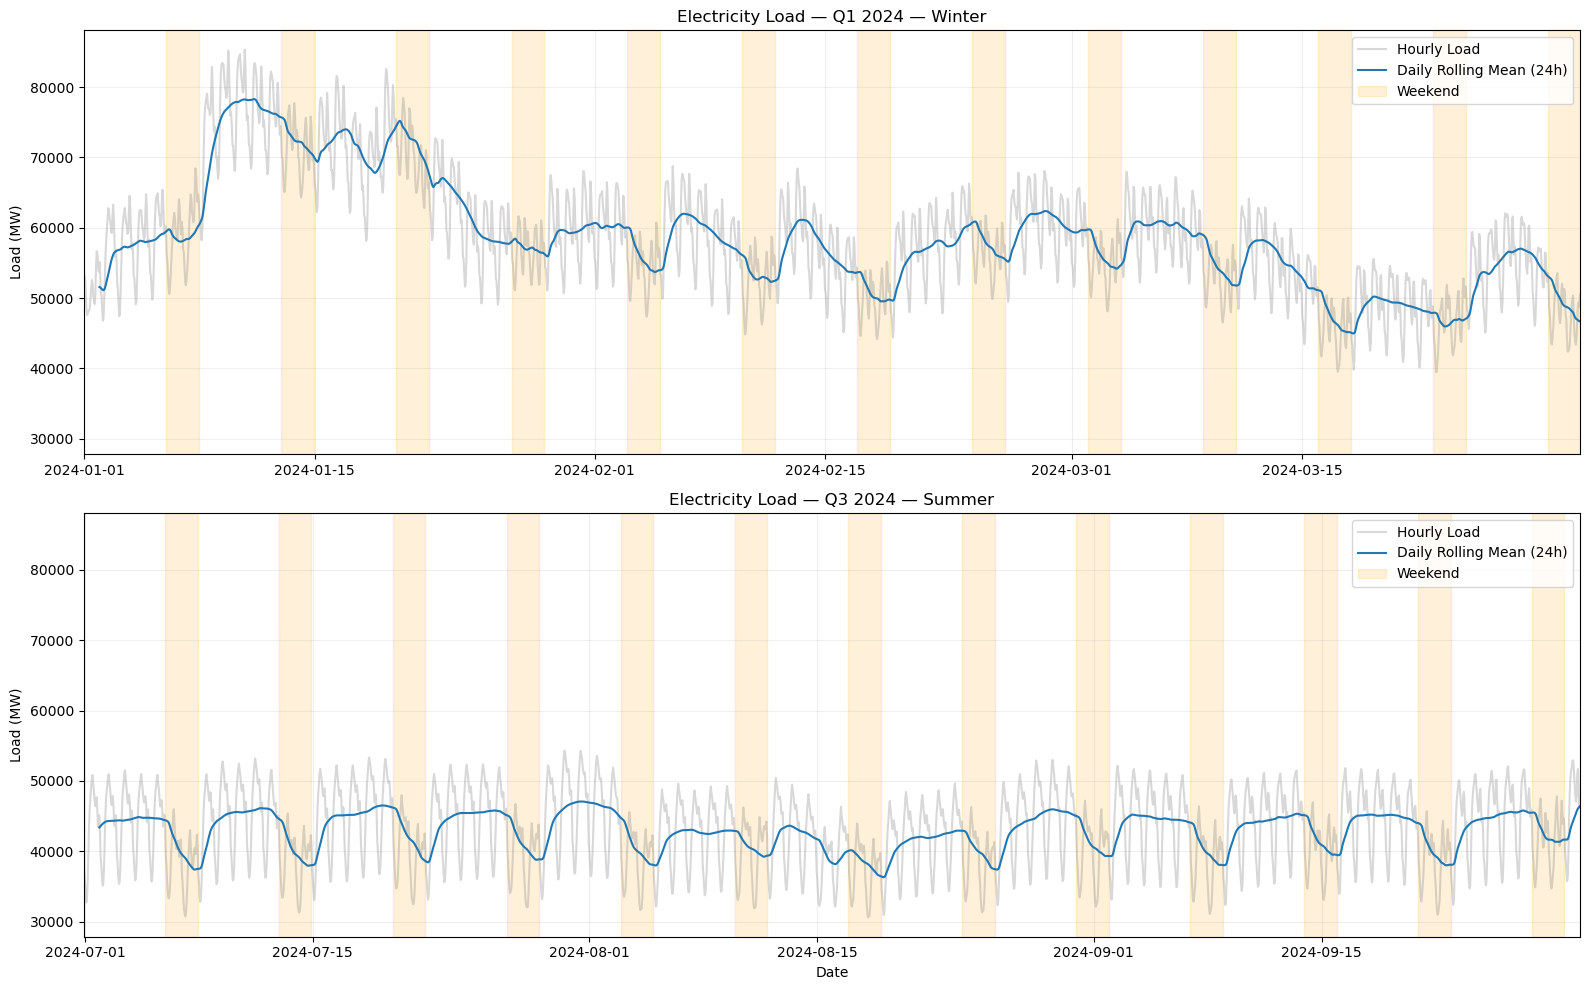

In [12]:
quarters = {
    "Q1 2024 — Winter": ("2024-01-01", "2024-04-01"),
    "Q3 2024 — Summer": ("2024-07-01", "2024-10-01")
}

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharey=True)

for ax, (label, (start, end)) in zip(axes, quarters.items()):

    # Select quarter using French local time
    local = train["datetime_fr"]

    quarter = train.loc[
        (local >= pd.Timestamp(start, tz="Europe/Paris")) &
        (local < pd.Timestamp(end, tz="Europe/Paris")),
        "load_mw"
    ]

    # Hourly load
    ax.plot(quarter.index, quarter, alpha=0.3,
            color="gray", label="Hourly Load")

    # Rolling means
    ax.plot(quarter.index, quarter.rolling(24).mean(),
            linewidth=1.5, label="Daily Rolling Mean (24h)")

    # Highlight weekends (French local time)
    local_days = pd.date_range(
        start, end, freq="D",
        tz="Europe/Paris", inclusive="left"
    )

    first_weekend = True

    for day in local_days:
        if day.dayofweek == 5:
            weekend_start = day.tz_convert("UTC")
            weekend_end = (day + pd.DateOffset(days=2)).tz_convert("UTC")

            ax.axvspan(
                weekend_start, weekend_end,
                color="orange", alpha=0.15,
                label="Weekend" if first_weekend else None
            )
            first_weekend = False

    ax.set_title(f"Electricity Load — {label}")
    ax.set_ylabel("Load (MW)")
    ax.set_xlim(quarter.index.min(), quarter.index.max())
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

### **Comments** 

- As can be seen in the two graphs, which show a weekday/weekend breakdown for Q1 and Q3, which are winter and summer quarters, respectively it is clear that the decline in consumption is widespread on weekends and that this is not an isolated case from our previous analysis, regardless of annual seasonality. 

- Therefore, national consumption clearly depends on two fundamental factors:

    **1) Economic activity:** The widespread decline is due to the sharp reduction in industrial and economic activity on weekends.

    **2) Individual household activity:** The volume of consumption accounted for by households in France is also a central factor in consumption, particularly when it comes to fine-grained patterns (intraday fluctuations). 

### **Consequently, within an annual cycle, which factor appears to have the greatest impact: a potential widespread decline in economic activity or widespread unemployment ?**

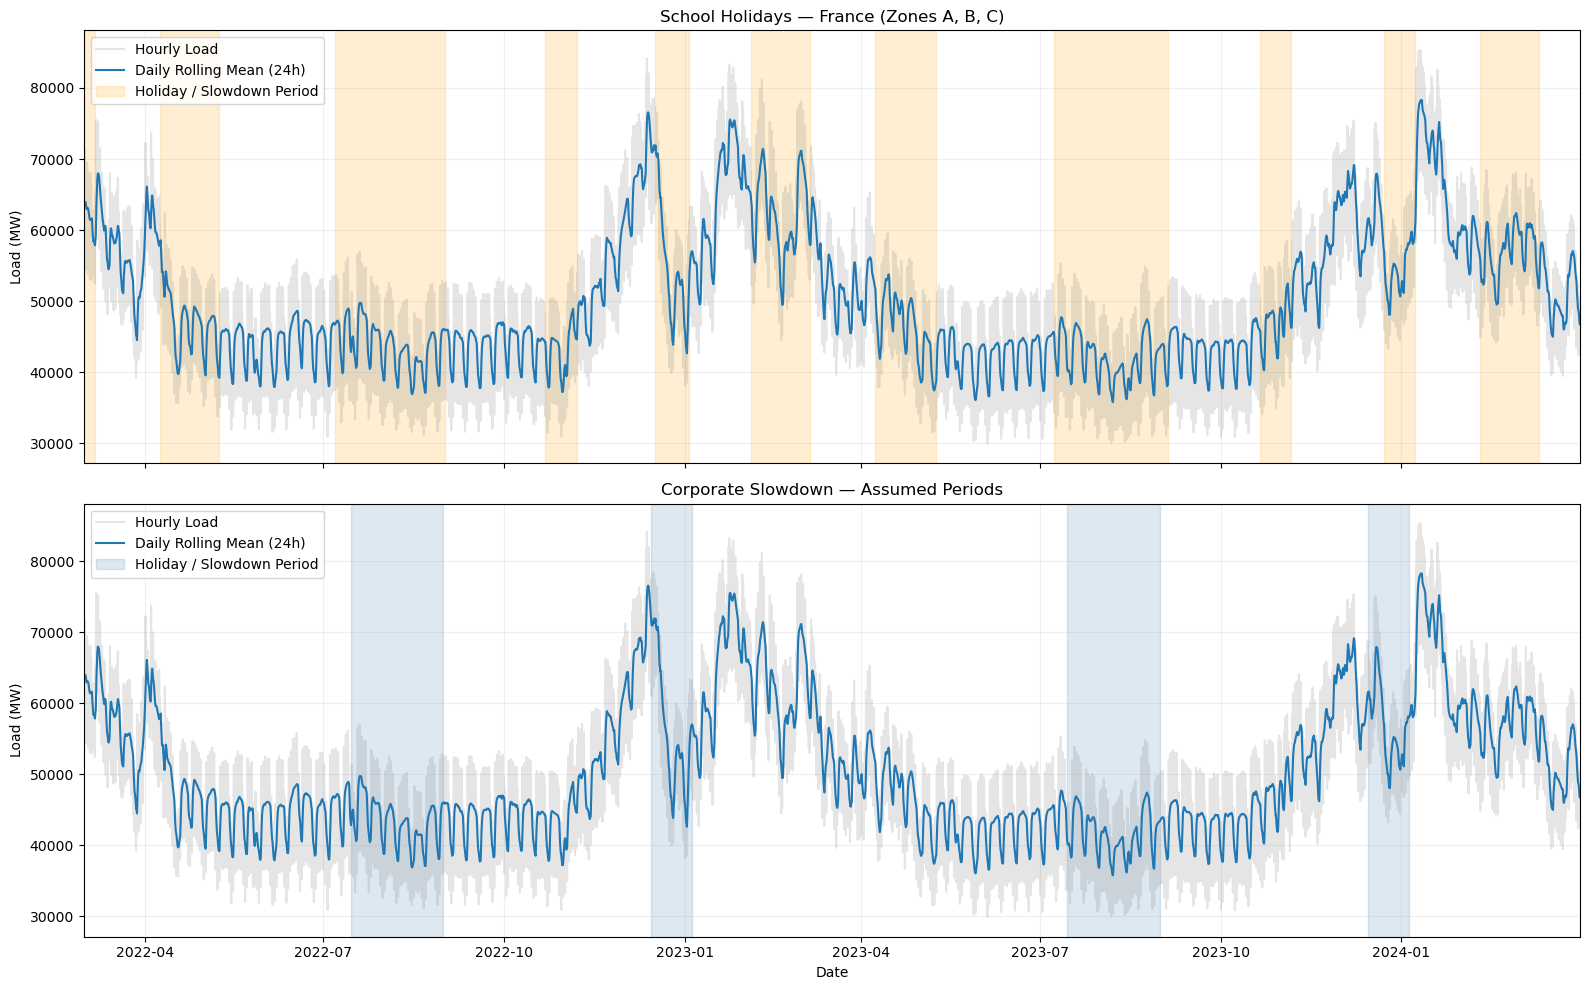

In [13]:
# Period: March 2022 to March 2024
start_date = "2022-03-01"
end_date = "2024-04-01"

start = pd.Timestamp(start_date, tz="Europe/Paris").tz_convert("UTC")
end = pd.Timestamp(end_date, tz="Europe/Paris").tz_convert("UTC")

y = train.loc[(train.index >= start) & (train.index < end), "load_mw"]

# School holidays: at least one zone (A, B, C)
school_holidays = [
    ("2022-03-01", "2022-03-07"),
    ("2022-04-09", "2022-05-09"),
    ("2022-07-07", "2022-09-01"),
    ("2022-10-22", "2022-11-07"),
    ("2022-12-17", "2023-01-03"),
    ("2023-02-04", "2023-03-06"),
    ("2023-04-08", "2023-05-09"),
    ("2023-07-08", "2023-09-04"),
    ("2023-10-21", "2023-11-06"),
    ("2023-12-23", "2024-01-08"),
    ("2024-02-10", "2024-03-11")
]

# Assumed corporate slowdown periods
corporate_holidays = [
    ("2022-07-15", "2022-08-31"),
    ("2022-12-15", "2023-01-05"),
    ("2023-07-15", "2023-08-31"),
    ("2023-12-15", "2024-01-05")
]

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True, sharey=True)

studies = [
    ("School Holidays — France (Zones A, B, C)", school_holidays, "orange"),
    ("Corporate Slowdown — Assumed Periods", corporate_holidays, "steelblue")
]

for ax, (title, periods, color) in zip(axes, studies):

    # Hourly consumption
    ax.plot(y.index, y, color="gray", alpha=0.2, label="Hourly Load")

    # Daily rolling mean
    ax.plot(
        y.index,
        y.rolling(24).mean(),
        linewidth=1.5,
        label="Daily Rolling Mean (24h)"
    )

    # Highlight periods using French local dates
    for i, (date_start, date_end) in enumerate(periods):

        t0 = pd.Timestamp(date_start, tz="Europe/Paris").tz_convert("UTC")
        t1 = pd.Timestamp(date_end, tz="Europe/Paris").tz_convert("UTC")

        ax.axvspan(
            t0, t1,
            color=color,
            alpha=0.18,
            label="Holiday / Slowdown Period" if i == 0 else None
        )

    ax.set_title(title)
    ax.set_ylabel("Load (MW)")
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")
axes[-1].set_xlim(start, end)

plt.tight_layout()
plt.show()

### **Comment :**
- The business holiday chart seems to provide a much more accurate picture of the nationwide decline in consumption that naturally occurs around the winter holidays, which does not allow for a continued slowdown in activity as seen during the summer, a period that also typically sees a trough in July.

Hot threshold: 23.93 °C
Cold threshold: 4.05 °C


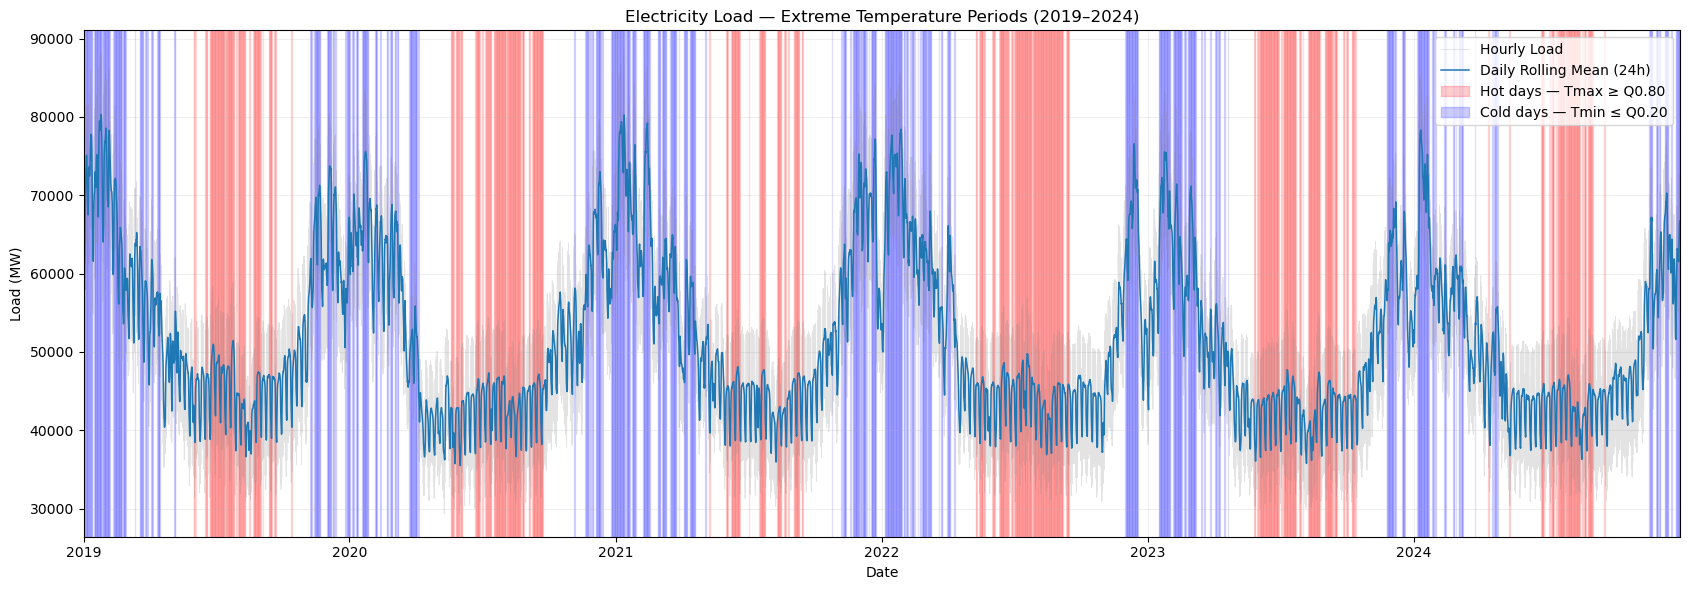

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Adjustable temperature quantiles
HOT_QUANTILE = 0.80
COLD_QUANTILE = 0.20

# Training data — 2019–2024
y = train["load_mw"].sort_index()
temperature = train["temperature_c"].sort_index()

# French local calendar dates
temp_fr = temperature.index.tz_convert("Europe/Paris")

daily_temp = pd.DataFrame({
    "temperature": temperature.to_numpy(),
    "date_fr": temp_fr.date
})

# Daily maximum and minimum temperatures
daily_stats = daily_temp.groupby("date_fr")["temperature"].agg(
    ["max", "min"]
)

# Thresholds computed over the training period
hot_threshold = daily_stats["max"].quantile(HOT_QUANTILE)
cold_threshold = daily_stats["min"].quantile(COLD_QUANTILE)

print(f"Hot threshold: {hot_threshold:.2f} °C")
print(f"Cold threshold: {cold_threshold:.2f} °C")

fig, ax = plt.subplots(figsize=(17, 6))

# Electricity consumption
ax.plot(
    y.index,
    y,
    color="gray",
    alpha=0.22,
    linewidth=0.6,
    label="Hourly Load"
)

ax.plot(
    y.index,
    y.rolling(24).mean(),
    color="tab:blue",
    linewidth=1.1,
    label="Daily Rolling Mean (24h)"
)

# Highlight extreme-temperature days
for date, row in daily_stats.iterrows():

    is_hot = row["max"] >= hot_threshold
    is_cold = row["min"] <= cold_threshold

    if not (is_hot or is_cold):
        continue

    # Boundaries in French local time, converted to UTC
    start_fr = pd.Timestamp(date).tz_localize("Europe/Paris")
    end_fr = start_fr + pd.DateOffset(days=1)

    start_utc = start_fr.tz_convert("UTC")
    end_utc = end_fr.tz_convert("UTC")

    if is_hot:
        ax.axvspan(
            start_utc, end_utc,
            color="red", alpha=0.13
        )

    if is_cold:
        ax.axvspan(
            start_utc, end_utc,
            color="blue", alpha=0.13
        )

# Legend
handles, labels = ax.get_legend_handles_labels()

handles += [
    Patch(color="red", alpha=0.20),
    Patch(color="blue", alpha=0.20)
]

labels += [
    f"Hot days — Tmax ≥ Q{HOT_QUANTILE:.2f}",
    f"Cold days — Tmin ≤ Q{COLD_QUANTILE:.2f}"
]

ax.legend(handles, labels, loc="upper right")

ax.set_xlim(y.index.min(), y.index.max())
ax.set_title("Electricity Load — Extreme Temperature Periods (2019–2024)")
ax.set_xlabel("Date")
ax.set_ylabel("Load (MW)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### **Comment :**
- As for the temperature data, it is a bit too sparse compared to the calendar analysis; we could integrate it using a cooling and heating factor approach to incorporate exogenous data into the temperature series. 

--- 
# **2. Baseline Models & RTE Benchmark**

### **2.1 — Forecasting Protocol**

All models follow the same operational forecasting procedure:

- **Forecast origin:** day D at 11:00 (Europe/Paris).
- **Target:** hourly electricity demand from 00:00 to 23:00 on D+1 (French local time).
- **Historical inputs:** observations available strictly before the forecast origin.
- **Time indexing:** UTC for hourly lags, French local time for target definition.
- **Output:** 24 hourly predictions per day.

**Daylight saving transitions:**
- 23-hour day: discard the prediction for the nonexistent 02:00.
- 25-hour day: assign NaN to the first 02:00 occurrence and keep the prediction for the second.

The same rules apply to every model and benchmark.

In [15]:
def get_forecast_window(target_day):

    # French local day D+1
    day = pd.Timestamp(target_day, tz="Europe/Paris")
    next_day = day + pd.DateOffset(days=1)

    # Forecast origin: day D at 11:00 local time
    origin = (day - pd.DateOffset(days=1)).replace(hour=11)

    # Real target timestamps in UTC
    target_hours = pd.date_range(
        start=day,
        end=next_day,
        freq="h",
        inclusive="left"
    ).tz_convert("UTC")

    return origin.tz_convert("UTC"), target_hours

**Test for origin and targeting**

In [16]:
for day in ["2025-01-15", "2025-03-30", "2025-06-26", "2025-10-26", "2025-11-26"]:
    origin, targets = get_forecast_window(day)

    print(
        day,
        "| Origin:", origin,
        "| Target hours:", len(targets)
    )

2025-01-15 | Origin: 2025-01-14 10:00:00+00:00 | Target hours: 24
2025-03-30 | Origin: 2025-03-29 10:00:00+00:00 | Target hours: 23
2025-06-26 | Origin: 2025-06-25 09:00:00+00:00 | Target hours: 24
2025-10-26 | Origin: 2025-10-25 09:00:00+00:00 | Target hours: 25
2025-11-26 | Origin: 2025-11-25 10:00:00+00:00 | Target hours: 24


### **2.2 — Daylight Saving Time Alignment**

Every model produces 24 predictions indexed by French clock hours (0–23).

We align these predictions with real UTC timestamps:

- Normal days: direct alignment.
- Spring transition: missing local hour excluded.
- Autumn transition: first repeated 02:00 assigned NaN.

DST transitions are known in advance, so this adjustment introduces no data leakage.

In [17]:
def align_24h_forecast(predictions, target_hours):

    predictions = np.asarray(predictions)

    if len(predictions) != 24:
        raise ValueError("Expected exactly 24 predictions")

    # French clock hours corresponding to real UTC timestamps
    local_hours = target_hours.tz_convert("Europe/Paris").hour

    # Map each clock hour to its prediction
    aligned = pd.Series(
        predictions[local_hours],
        index=target_hours,
        dtype=float
    )

    # Ignore first occurrence of repeated hours
    duplicate_mask = pd.Index(local_hours).duplicated(keep="last")
    aligned.iloc[np.flatnonzero(duplicate_mask)] = np.nan

    return aligned

for day in ["2025-01-15", "2025-03-30", "2025-10-26"]:

    _, targets = get_forecast_window(day)

    pred = align_24h_forecast(np.arange(24), targets)

    print(
        day,
        "| Predictions:", pred.notna().sum(),
        "| NaN:", pred.isna().sum()
    )

2025-01-15 | Predictions: 24 | NaN: 0
2025-03-30 | Predictions: 23 | NaN: 0
2025-10-26 | Predictions: 24 | NaN: 1


### **2.3 — Naive Forecasts & RTE Benchmark**

We establish three reference forecasts:

- **Naive (48h):** consumption observed 48 hours before the target timestamp.
- **Seasonal Naive (168h):** consumption observed 7 days before the target timestamp.
- **RTE D+1:** official day-ahead demand forecast.

Both naive methods use fixed UTC lags, respecting the 11:00 forecast cutoff.

Predictions are generated day by day using the same forecasting protocol. We initially evaluate them on the **2025 validation period**, keeping 2026 untouched.

In [18]:
baseline_days = []

# All French target dates in the validation set
target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

for day in target_days:

    origin, targets = get_forecast_window(day)

    # One prediction per French clock hour (0–23)
    naive_48 = np.full(24, np.nan)
    naive_168 = np.full(24, np.nan)
    naive_720 = np.full(24, np.nan)
    naive_2160 = np.full(24, np.nan)
    rte_24 = np.full(24, np.nan)

    local_hours = targets.tz_convert("Europe/Paris").hour

    # Keep the second occurrence of repeated clock hours
    duplicates = pd.Index(local_hours).duplicated(keep="last")

    for t, hour, duplicate in zip(targets, local_hours, duplicates):

        if duplicate:
            continue

        # Fixed UTC lags
        t48 = t - pd.Timedelta(hours=48)
        t168 = t - pd.Timedelta(hours=168)
        t720 = t - pd.Timedelta(hours=720)
        t2160 = t - pd.Timedelta(hours=2160)

        # Verify forecast-time availability
        assert all(
            lag < origin
            for lag in [t48, t168, t720, t2160]
        )

        naive_48[hour] = df.loc[t48, "load_mw"]
        naive_168[hour] = df.loc[t168, "load_mw"]
        naive_720[hour] = df.loc[t720, "load_mw"]
        naive_2160[hour] = df.loc[t2160, "load_mw"]
        rte_24[hour] = df.loc[t, "rte_forecast_d1_mw"]

    # Align all forecasts with actual timestamps
    daily = pd.DataFrame({
        "actual": df.loc[targets, "load_mw"],
        "naive_48h": align_24h_forecast(naive_48, targets),
        "seasonal_naive_168h": align_24h_forecast(naive_168, targets),
        "monthly_naive_720h": align_24h_forecast(naive_720, targets),
        "quarterly_naive_2160h": align_24h_forecast(naive_2160, targets),
        "rte_d1": align_24h_forecast(rte_24, targets)
    })

    baseline_days.append(daily)

# Reconstruct the complete validation series
baseline_val = pd.concat(baseline_days).sort_index()

display(baseline_val.head())

,actual,naive_48h,seasonal_naive_168h,monthly_naive_720h,quarterly_naive_2160h,rte_d1
2024-12-31 23:00:00+00:00,64637.0,62862.0,56026.0,54322.0,42246.0,62988.0
2025-01-01 00:00:00+00:00,62362.0,59816.0,53536.0,51048.0,41066.0,61375.0
2025-01-01 01:00:00+00:00,61780.0,58802.0,52597.0,49953.0,39241.0,60062.0
2025-01-01 02:00:00+00:00,59824.0,56989.0,50093.0,48176.0,37714.0,56775.0
2025-01-01 03:00:00+00:00,57606.0,55544.0,47504.0,46752.0,38186.0,54550.0


### **2.4 — Evaluation Metrics & Missing Values**

**MAPE (%) is our primary metric** for model selection and hyperparameter tuning.

Since French national electricity demand is strictly positive and far from zero, MAPE provides an interpretable measure of relative forecasting error without denominator instability.

We also report MAE and RMSE for operational interpretation.

**Evaluation rules:**
- Exclude originally missing observations using `df_raw`.
- Exclude the first repeated 02:00 during autumn DST transitions.
- Never evaluate against interpolated ground truth.
- Use identical target timestamps for all models.

The 2026 test set remains reserved for final evaluation.

In [19]:
# Original observations only
valid_actual = df_raw.loc[baseline_val.index, "load_mw"].notna()
valid_rte = df_raw.loc[baseline_val.index, "rte_forecast_d1_mw"].notna()

# Exclude missing original observations
evaluation_mask = valid_actual & valid_rte

baseline_eval = baseline_val.loc[evaluation_mask].copy()

# Exclude DST-related NaNs before evaluation
baseline_eval = baseline_eval.dropna()

# Check missing predictions
print(baseline_eval.isna().sum())

# Missing model predictions must be investigated, not silently dropped
assert baseline_eval.notna().all().all()
assert (baseline_eval["actual"] > 0).all()

print("Evaluated hours:", len(baseline_eval))

actual                   0
naive_48h                0
seasonal_naive_168h      0
monthly_naive_720h       0
quarterly_naive_2160h    0
rte_d1                   0
dtype: int64
Evaluated hours: 8759


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecast(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "MAPE (%)": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        "MAE (MW)": mean_absolute_error(y_true, y_pred),
        "RMSE (MW)": np.sqrt(mean_squared_error(y_true, y_pred))
    }

models = [
    "naive_48h",
    "seasonal_naive_168h",
    "monthly_naive_720h",
    "quarterly_naive_2160h",
    "rte_d1"
]
results = {}


for model in models:
    results[model] = evaluate_forecast(
        baseline_eval["actual"],
        baseline_eval[model]
    )

baseline_results = pd.DataFrame(results).T

display(baseline_results.sort_values("MAPE (%)").round(2))

,MAPE (%),MAE (MW),RMSE (MW)
rte_d1,2.82,1396.65,1725.79
seasonal_naive_168h,6.43,3460.56,5145.81
naive_48h,8.04,3993.71,5219.24
monthly_naive_720h,12.70,6436.92,8306.45
quarterly_naive_2160h,22.20,11233.58,14317.34


#### We will use the “seasonal_naive_168h” model as the baseline

---
# **3. Statistical Models**
### **3.1 Box-Jenkins (1)— Plot & Seasonal Decomposition**
Following the Box-Jenkins methodology, we first examine the structural components of electricity demand using STL (Seasonal-Trend decomposition using LOESS).

We decompose the hourly training series into trend, daily seasonality (24h), and residuals.

The objective is to determine whether the daily seasonal component captures the main fluctuations or whether additional temporal patterns remain unexplained.

**STL Decomposition (24h)**

We apply STL to the hourly electricity demand from 2022 to 2024, using a daily seasonal period of 168 hours.

We try to observe how these components evolve over multiple years


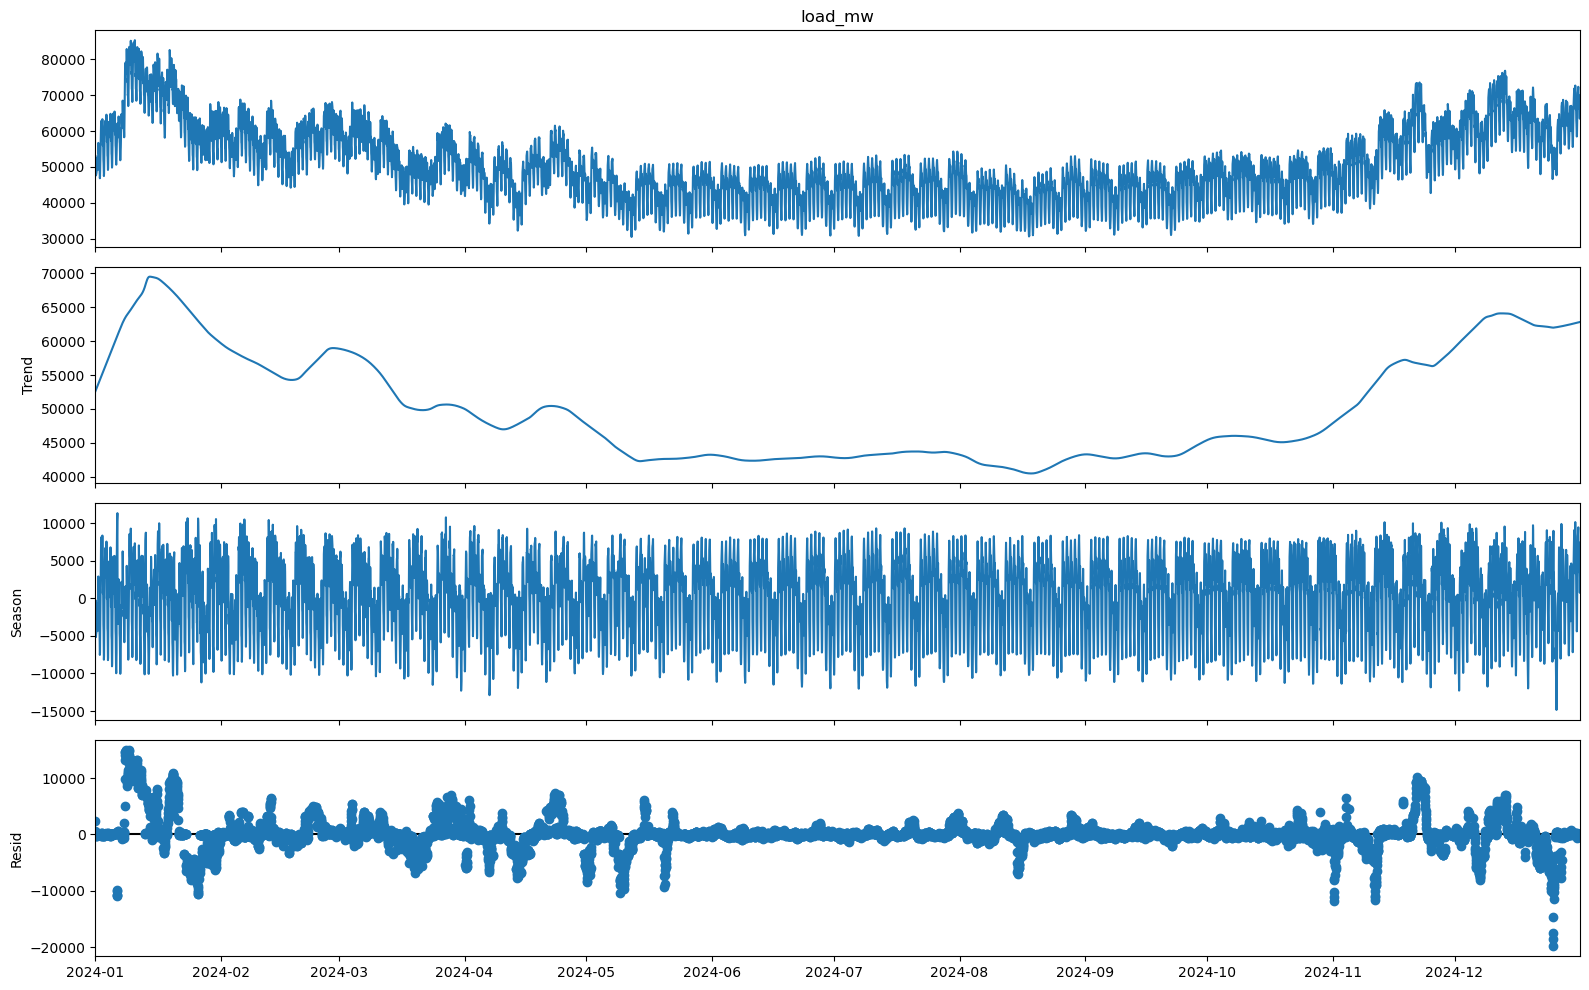

In [21]:
from statsmodels.tsa.seasonal import STL, MSTL

# Select 2022–2024 from training data
y_stl = train.loc["2024-01-01":"2024-12-31", "load_mw"]

# STL decomposition — daily seasonality
stl = STL(y_stl, period=168, robust=True).fit()

# Plot components
fig = stl.plot()
fig.set_size_inches(16, 10)
plt.tight_layout()
plt.show()

**MSTL Decomposition (24h, 168h)**

Daily seasonality (24h): recurring intraday patterns.

Weekly seasonality (168h): recurring weekly consumption patterns.

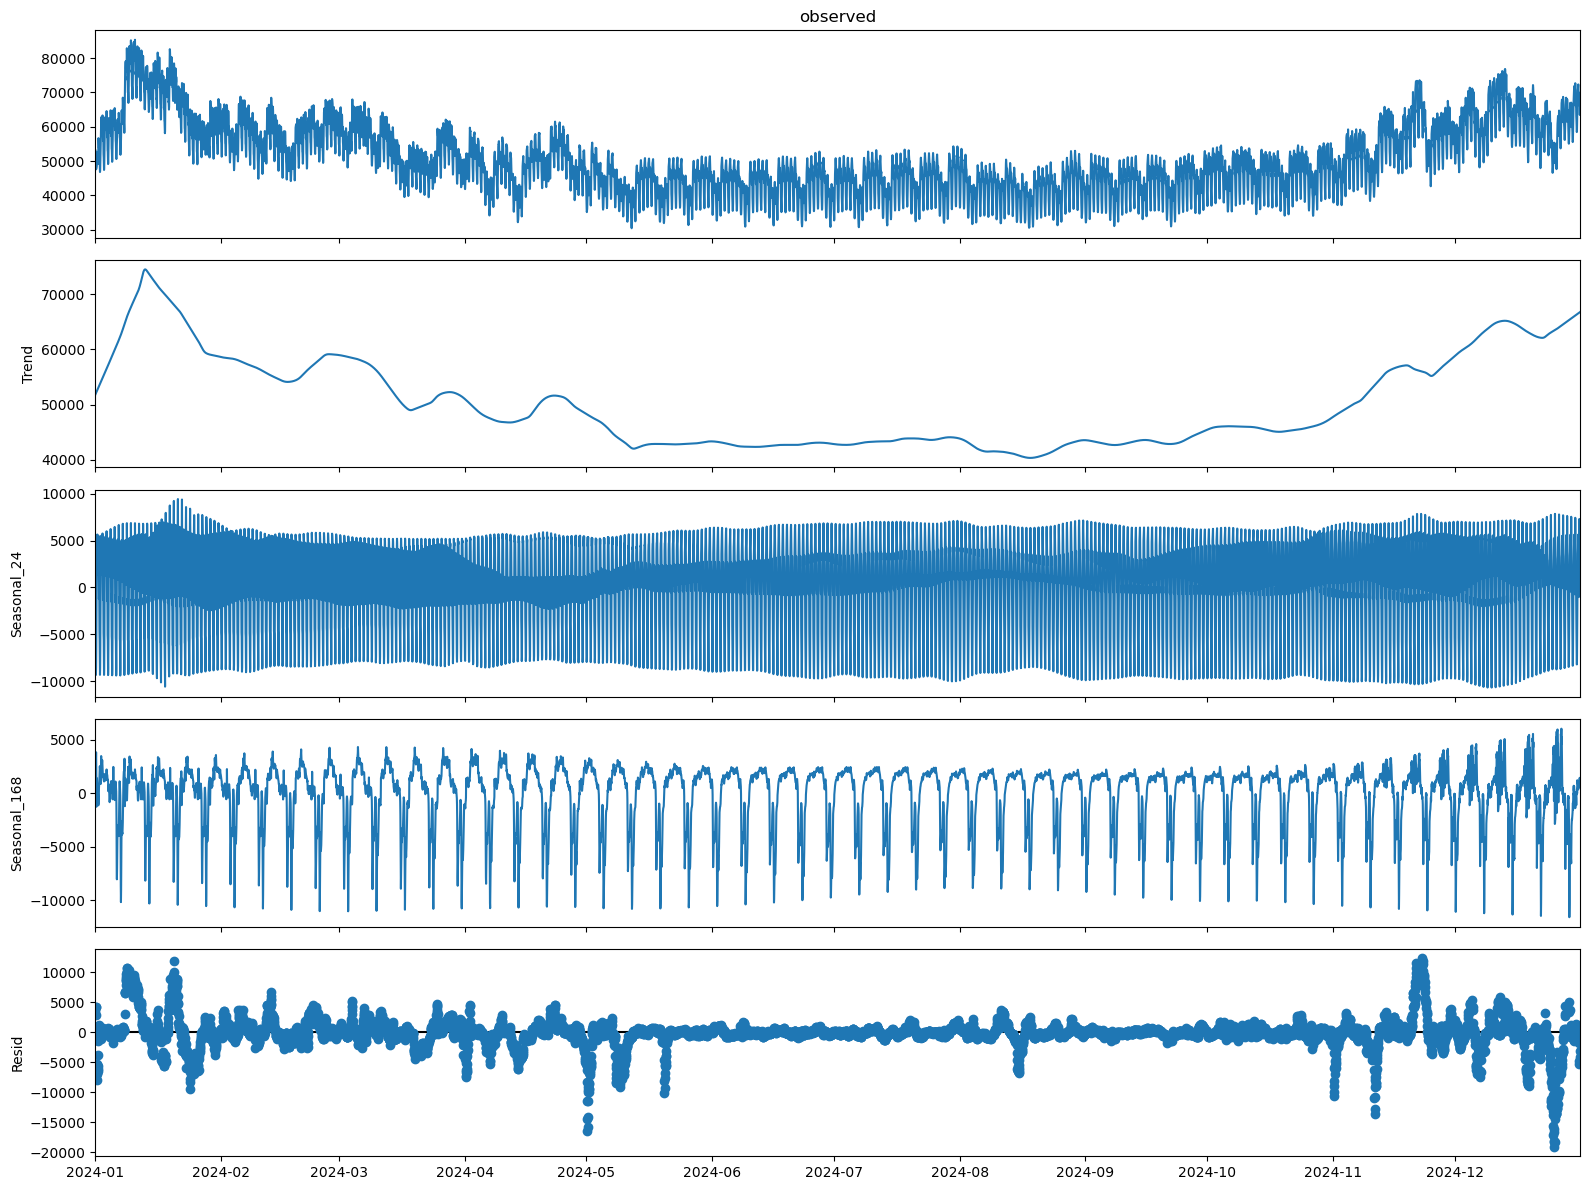

In [22]:
# Select 2024
y_mstl = train.loc["2024-01-01":"2024-12-31", "load_mw"]

# Multiple seasonal decomposition
mstl = MSTL(
    y_mstl,
    periods=(24, 168),
    stl_kwargs={"robust": True}
).fit()

# Plot components
fig = mstl.plot()
fig.set_size_inches(16, 12)
plt.tight_layout()
plt.show()

**Seasonal Comparison**
We compare the daily and weekly seasonal components extracted by MSTL across four representative months of 2024:

- Winter: January
- Spring: April
- Summer: July
- Autumn: October

The objective is to investigate whether the amplitude and variability of daily and weekly consumption patterns change across seasons.

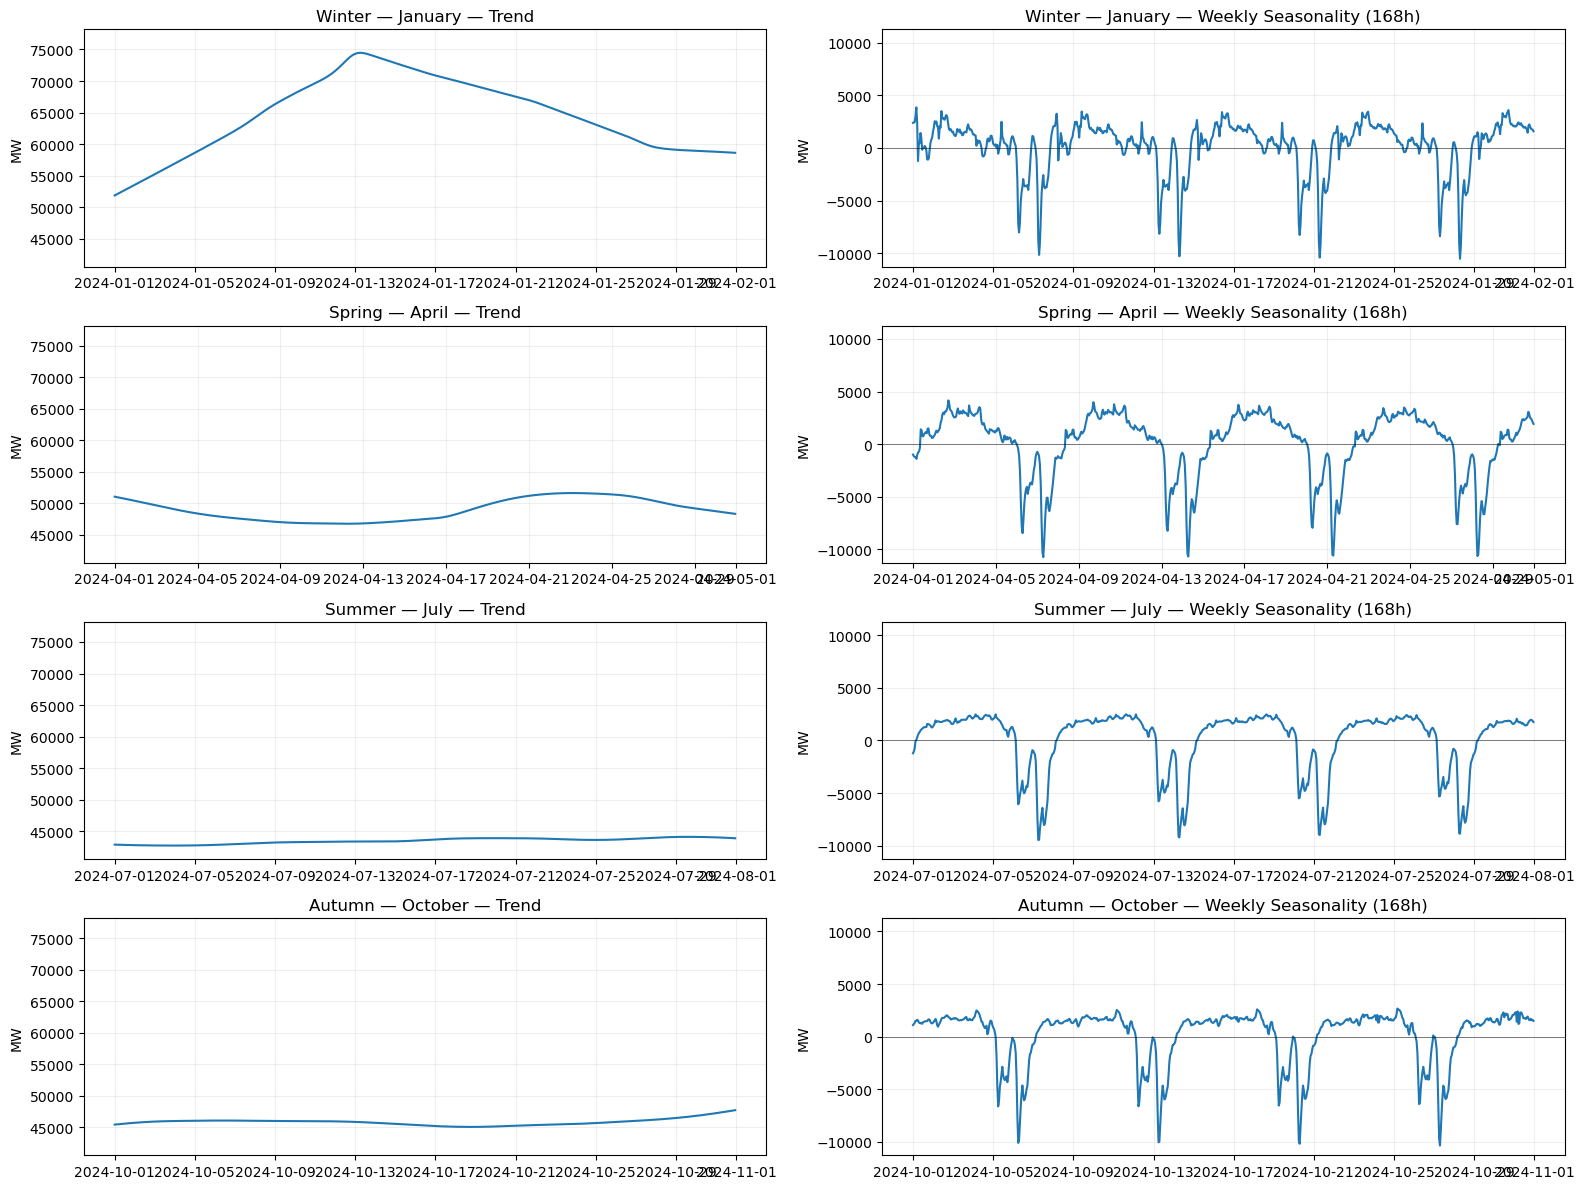

In [23]:
months = {
    "Winter — January": "2024-01",
    "Spring — April": "2024-04",
    "Summer — July": "2024-07",
    "Autumn — October": "2024-10"
}

fig, axes = plt.subplots(4, 2, figsize=(16, 12))

for i, (season, month) in enumerate(months.items()):

    # Trend
    trend = mstl.trend.loc[month]
    axes[i, 0].plot(trend.index, trend.values)
    axes[i, 0].set_title(f"{season} — Trend")
    axes[i, 0].set_ylabel("MW")
    axes[i, 0].grid(alpha=0.2)

    # Weekly seasonality
    weekly = mstl.seasonal["seasonal_168"].loc[month]
    axes[i, 1].plot(weekly.index, weekly.values)
    axes[i, 1].set_title(f"{season} — Weekly Seasonality (168h)")
    axes[i, 1].set_ylabel("MW")
    axes[i, 1].grid(alpha=0.2)

# Common Y-axis for each column
trend_min = min(mstl.trend.loc[m].min() for m in months.values())
trend_max = max(mstl.trend.loc[m].max() for m in months.values())

weekly_max = max(
    mstl.seasonal["seasonal_168"].loc[m].abs().max()
    for m in months.values()
)

for i in range(4):
    axes[i, 0].set_ylim(trend_min * 0.95, trend_max * 1.05)
    axes[i, 1].set_ylim(-weekly_max * 1.05, weekly_max * 1.05)
    axes[i, 1].axhline(0, color="black", linewidth=0.7, alpha=0.5)

plt.tight_layout()
plt.show()

**Quantifying Seasonal Amplitude**

In [24]:
seasonal_stats = []

for season, month in months.items():

    daily = mstl.seasonal["seasonal_24"].loc[month]
    weekly = mstl.seasonal["seasonal_168"].loc[month]

    seasonal_stats.append({
        "Season": season,
        "Daily Std (MW)": daily.std(),
        "Weekly Std (MW)": weekly.std(),
        "Daily Range (MW)": daily.max() - daily.min(),
        "Weekly Range (MW)": weekly.max() - weekly.min()
    })

seasonal_stats = pd.DataFrame(seasonal_stats).set_index("Season")

display(seasonal_stats.round(2))

,Daily Std (MW),Weekly Std (MW),Daily Range (MW),Weekly Range (MW)
Season,,,,
Winter — January,4794.40,2510.56,20033.73,14382.64
Spring — April,4056.27,3086.40,14453.59,14888.09
Summer — July,5170.29,2860.38,17144.77,11928.93
Autumn — October,4946.92,2602.47,16519.01,13013.36


### **3.2 Box-Jenkins (3) - Transform**

we need to assess whether the electricity demand series is stationary.


A stationary time series has statistical properties, such as its mean, variance and autocovariance structure, that do not change over time.
We apply two complementary statistical tests:
- Augmented Dickey-Fuller (ADF) Test :

    H₀: The series has a unit root (non-stationary).

    H₁: The series has no unit root (stationary under the test assumptions).

    Desired result: p-value < 0.05, allowing us to reject H₀.

In [25]:
from statsmodels.tsa.stattools import adfuller, kpss

# Select 2024 training observations
y = train.loc["2024-01-01":"2024-12-31", "load_mw"].dropna()

# ADF test
adf_result = adfuller(y, autolag="AIC")

print("Augmented Dickey-Fuller Test")
print(f"Statistic: {adf_result[0]:.4f}")
print(f"p-value:   {adf_result[1]:.4f}")


Augmented Dickey-Fuller Test
Statistic: -4.0962
p-value:   0.0010


- Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test

    H₀: The series is stationary around a constant level (regression="c").

    H₁: The series is not level-stationary.

    Desired result: p-value > 0.05, meaning we do not reject H₀.

Combining both tests provides complementary evidence about stationarity. However, neither test alone guarantees that the series is stationary, particularly in the presence of complex seasonal patterns.

In [26]:

# KPSS test
kpss_result = kpss(y, regression="c", nlags="auto")

print("\nKPSS Test")
print(f"Statistic: {kpss_result[0]:.4f}")
print(f"p-value:   {kpss_result[1]:.4f}")


KPSS Test
Statistic: 3.5129
p-value:   0.0100


/var/folders/j2/6n92hgzn6vv7rgs4fm_nk10w0000gn/T/ipykernel_17707/3966449262.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(y, regression="c", nlags="auto")


**Differencing**

Malheuresuement le test KPSS ne confirme pas du tout une série stationnaire 

In [27]:

y = train.loc["2024-01-01":"2024-12-31", "load_mw"].dropna()

transformations = {
    "Original": y,
    "Diff(1)": y.diff(),
    "Diff(1) + Diff(1)": y.diff().diff(),
    "Diff(24)": y.diff(24),
    "Diff(168)": y.diff(168),
    "Diff(1) + Diff(24)": y.diff().diff(24),
    "Diff(1) + Diff(168)": y.diff().diff(168)
}

results = []

for name, series in transformations.items():

    series = series.dropna()

    adf = adfuller(series, autolag="AIC")
    kp = kpss(series, regression="c", nlags="auto")

    results.append({
        "Transformation": name,
        "ADF Statistic": adf[0],
        "ADF p-value": adf[1],
        "KPSS Statistic": kp[0],
        "KPSS p-value": kp[1],
        "ADF Reject H0": adf[1] < 0.05,
        "KPSS Reject H0": kp[1] < 0.05,
        "Stationarity Supported": (adf[1] < 0.05) and (kp[1] > 0.05)
    })

stationarity_results = pd.DataFrame(results).set_index("Transformation")

display(stationarity_results.round(4))

/var/folders/j2/6n92hgzn6vv7rgs4fm_nk10w0000gn/T/ipykernel_17707/4112654464.py:20: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kp = kpss(series, regression="c", nlags="auto")
/var/folders/j2/6n92hgzn6vv7rgs4fm_nk10w0000gn/T/ipykernel_17707/4112654464.py:20: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kp = kpss(series, regression="c", nlags="auto")
/var/folders/j2/6n92hgzn6vv7rgs4fm_nk10w0000gn/T/ipykernel_17707/4112654464.py:20: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kp = kpss(series, regression="c", nlags="auto")
/var/folders/j2/6n92hgzn6vv7rgs4fm_nk10w0000gn/T/ipykernel_17707/4112654464.py:20: InterpolationWarn

,ADF Statistic,ADF p-value,KPSS Statistic,KPSS p-value,ADF Reject H0,KPSS Reject H0,Stationarity Supported
Transformation,,,,,,,
Original,-4.0962,0.001,3.5129,0.0100,True,True,False
Diff(1),-15.4218,0.000,0.0346,0.1000,True,False,True
Diff(1) + Diff(1),-28.1401,0.000,0.1113,0.1000,True,False,True
Diff(24),-16.1335,0.000,0.0493,0.1000,True,False,True
Diff(168),-6.5838,0.000,0.4869,0.0446,True,True,False
Diff(1) + Diff(24),-18.8213,0.000,0.0025,0.1000,True,False,True
Diff(1) + Diff(168),-15.7016,0.000,0.0284,0.1000,True,False,True


The original series shows conflicting stationarity test results: ADF rejects the unit-root hypothesis, while KPSS rejects level stationarity.

Most differencing transformations provide evidence consistent with stationarity, except for the weekly seasonal difference (168h) applied alone.

Since both first-order differencing and daily seasonal differencing (24h) satisfy the two tests independently, additional differencing may be unnecessary.

We will examine the ACF and PACF of these candidate transformed series to assess their remaining temporal dependence and guide the selection of SARIMA orders while avoiding over-differencing.

### **3.3 Box-Jenkins (2) — Identify: ACF & PACF**

Following the stationarity tests, we focus on two candidate transformations:

- First-order differencing: (d=1,\ D=0).
- Daily seasonal differencing: (d=0,\ D=1,\ s=24).

We examine the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) of each transformed series to identify potential non-seasonal AR/MA orders ((p,q)) and seasonal AR/MA orders ((P,Q)).

In [28]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import numpy as np
import time
import warnings

# Training data
y_fit = train.loc["2024-01-01":"2024-12-31", "load_mw"].asfreq("h")

# Persistent results
aic_results = []
best_models = {}
best_aic = {}

**Diff(1)**

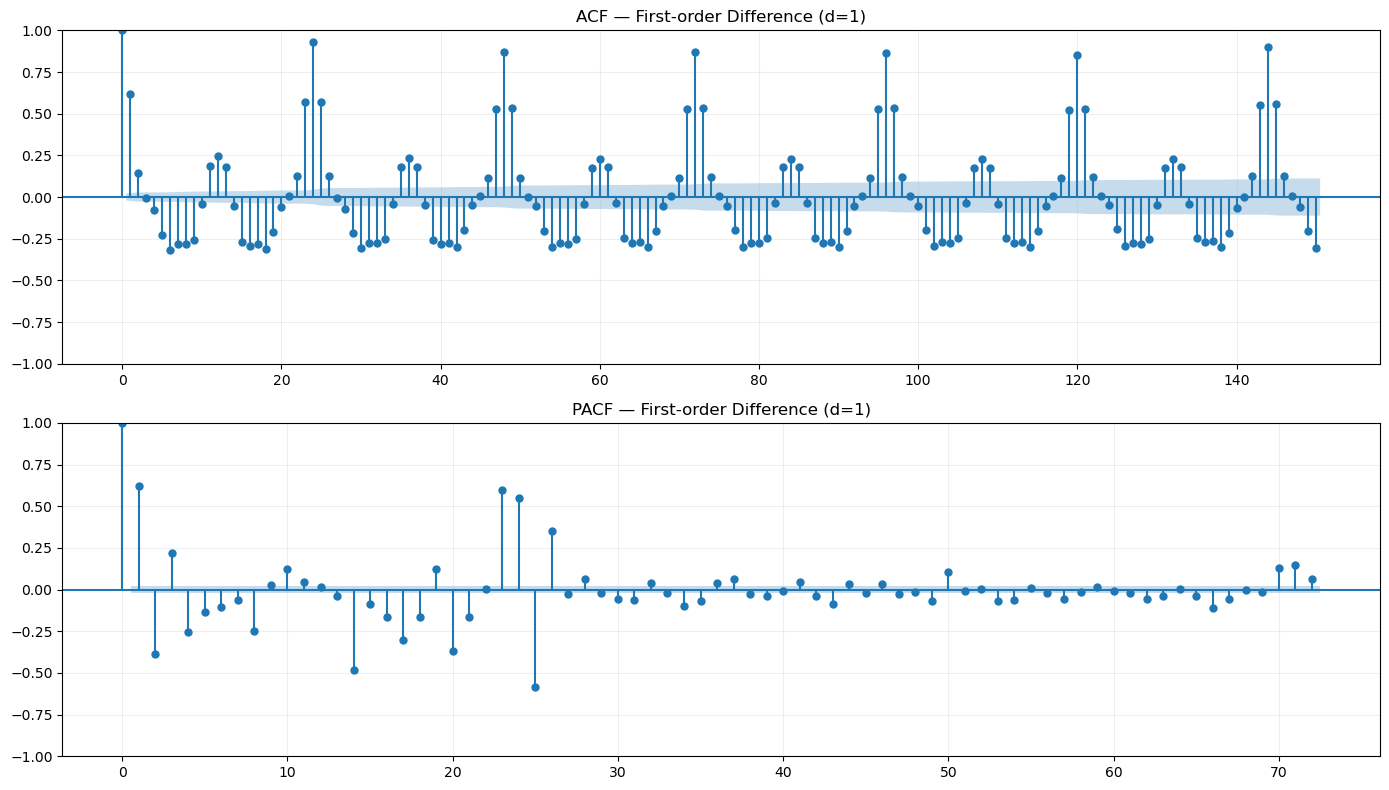

In [29]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# First-order differencing
y_diff1 = y.diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(y_diff1, lags=150, ax=axes[0])
axes[0].set_title("ACF — First-order Difference (d=1)")
axes[0].grid(alpha=0.2)

plot_pacf(y_diff1, lags=72, ax=axes[1], method="ywm")
axes[1].set_title("PACF — First-order Difference (d=1)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [27]:

candidates = {
"Diff(1)": [
        ((2, 1, 1), (1, 0, 1, 24)),# 11 s ? 
        ((2, 1, 2), (1, 0, 1, 24)),#10s
        ((3, 1, 1), (1, 0, 2, 24)),# 143s 
        ((3, 1, 2), (1, 0, 2, 24)),# 138s 
        ((3, 1, 2), (2, 0, 2, 24)),#160s
        ((2, 1, 1), (2, 0, 2, 24)) #130s
    ]
}

total_models = sum(len(configs) for configs in candidates.values())
current_model = 0

for family, configurations in candidates.items():

    print(f"\n========== {family} ==========", flush=True)

    best_aic.setdefault(family, np.inf)

    for order, seasonal_order in configurations:

        current_model += 1

        # Skip previously tested models
        already_tested = any(
            row["Family"] == family
            and row["Order"] == order
            and row["Seasonal Order"] == seasonal_order
            for row in aic_results
        )

        if already_tested:
            print(f"[{current_model}/{total_models}] SKIPPED (already tested)")
            continue

        start = time.perf_counter()

        print(
            f"\n[{current_model}/{total_models}] START "
            f"SARIMA{order}x{seasonal_order}",
            flush=True
        )

        try:
            model = SARIMAX(
                y_fit,
                order=order,
                seasonal_order=seasonal_order,
                trend="n",
                simple_differencing=False
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = model.fit(disp=5, maxiter=10)

            converged = result.mle_retvals.get("converged", False)
            elapsed = time.perf_counter() - start

            # Append result instead of resetting
            aic_results.append({
                "Family": family,
                "Order": order,
                "Seasonal Order": seasonal_order,
                "Log-Likelihood": result.llf,
                "k": result.df_model,
                "AIC": result.aic,
                "Converged": converged,
                "Time (s)": elapsed
            })

            print(
                f"[{current_model}/{total_models}] DONE | "
                f"AIC={result.aic:.2f} | "
                f"Converged={converged} | "
                f"Time={elapsed:.1f}s",
                flush=True
            )

            # Update best model for this family
            if converged and np.isfinite(result.aic):
                if result.aic < best_aic[family]:
                    best_aic[family] = result.aic
                    best_models[family] = result

        except Exception as e:
            print(
                f"[{current_model}/{total_models}] FAILED | "
                f"{type(e).__name__}: {e}",
                flush=True
            )


========== Diff(1) ==========

[1/6] START SARIMA(2, 1, 1)x(1, 0, 1, 24)
[1/6] DONE | AIC=145438.84 | Converged=False | Time=8.4s

[2/6] START SARIMA(2, 1, 2)x(1, 0, 1, 24)
[2/6] DONE | AIC=145127.61 | Converged=False | Time=9.3s

[3/6] START SARIMA(3, 1, 1)x(1, 0, 2, 24)


KeyboardInterrupt: 

**Outcome Diff(1)** :

- p : [0,1,2,3,4]
- q : [0,1,2,3]
- P : [0,1,2]
- Q : [1,2,3]
- s : 24

diff_(1)= {((2, 1, 1), (1, 0, 1, 24))
            ((2, 1, 2), (1, 0, 1, 24))
            ((3, 1, 1), (1, 0, 2, 24))
            ((3, 1, 2), (1, 0, 2, 24))
            ((3, 1, 2), (2, 0, 2, 24))
            ((2, 1, 1), (2, 0, 2, 24))}

**Diff(24)**

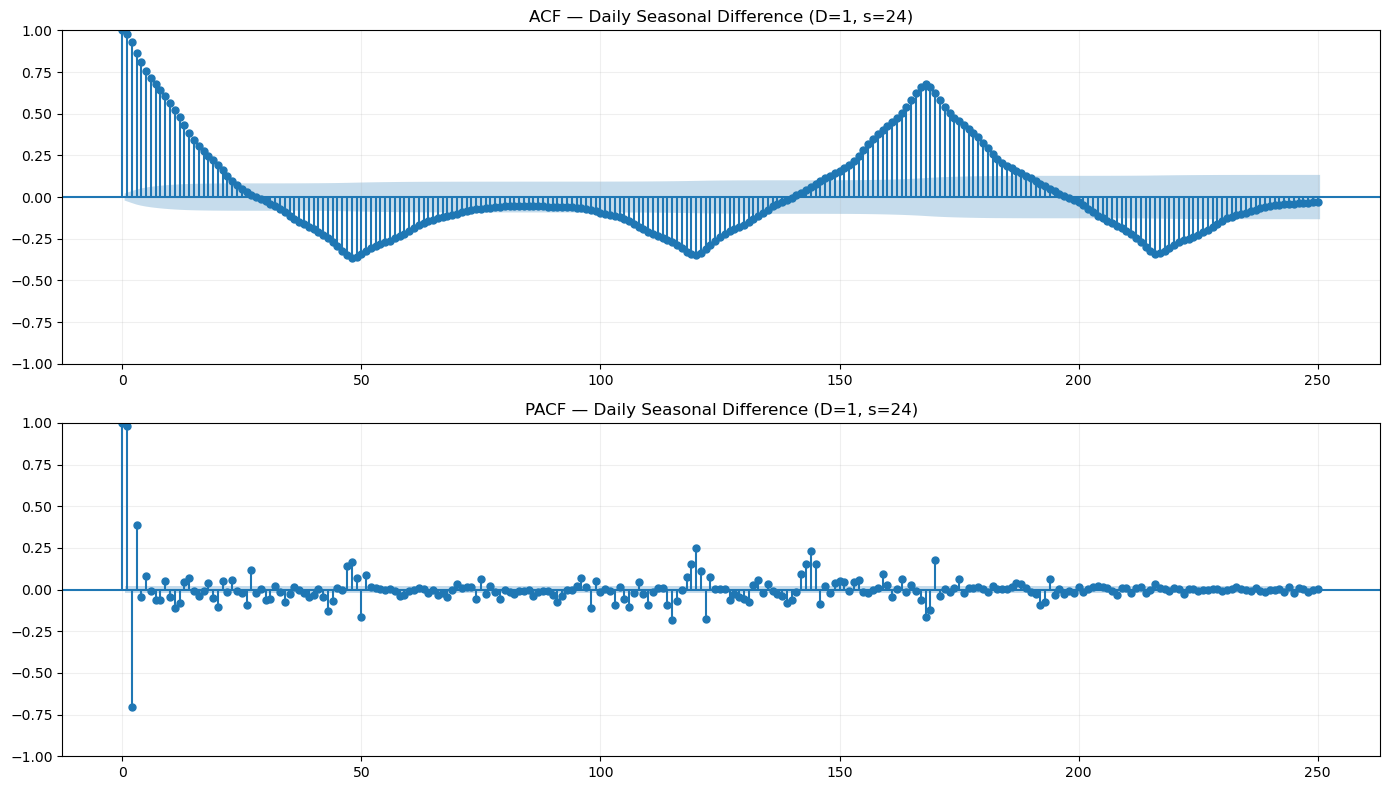

In [30]:
# Daily seasonal differencing
y_diff24 = y.diff(24).dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(y_diff24, lags=250, ax=axes[0])
axes[0].set_title("ACF — Daily Seasonal Difference (D=1, s=24)")
axes[0].grid(alpha=0.2)

plot_pacf(y_diff24, lags=250, ax=axes[1], method="ywm")
axes[1].set_title("PACF — Daily Seasonal Difference (D=1, s=24)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [31]:
candidates = {
"Diff(1)": [
        ((2, 0, 5), (0, 1, 0, 24)),
        ((4, 0, 5), (0, 1, 0, 24)),
        ((3, 0, 1), (0, 1, 0, 24)),
        ((3, 0, 2), (0, 1, 0, 24)),
        ((3, 0, 3), (0, 1, 0, 24)),#
        ((3, 0, 0), (0, 1, 0, 24)),
        ((0, 0, 3), (0, 1, 0, 24)),
        ((0, 0, 1), (0, 1, 0, 24)),
        ((1, 0, 0), (0, 1, 0, 24)),
    ]
}

total_models = sum(len(configs) for configs in candidates.values())
current_model = 0

for family, configurations in candidates.items():

    print(f"\n========== {family} ==========", flush=True)

    best_aic.setdefault(family, np.inf)

    for order, seasonal_order in configurations:

        current_model += 1

        # Skip previously tested models
        already_tested = any(
            row["Family"] == family
            and row["Order"] == order
            and row["Seasonal Order"] == seasonal_order
            for row in aic_results
        )

        if already_tested:
            print(f"[{current_model}/{total_models}] SKIPPED (already tested)")
            continue

        start = time.perf_counter()

        print(
            f"\n[{current_model}/{total_models}] START "
            f"SARIMA{order}x{seasonal_order}",
            flush=True
        )

        try:
            model = SARIMAX(
                y_fit,
                order=order,
                seasonal_order=seasonal_order,
                trend="n",
                simple_differencing=False
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = model.fit(disp=5, maxiter=50)

            converged = result.mle_retvals.get("converged", False)
            elapsed = time.perf_counter() - start

            # Append result instead of resetting
            aic_results.append({
                "Family": family,
                "Order": order,
                "Seasonal Order": seasonal_order,
                "Log-Likelihood": result.llf,
                "k": result.df_model,
                "AIC": result.aic,
                "Converged": converged,
                "Time (s)": elapsed
            })

            print(
                f"[{current_model}/{total_models}] DONE | "
                f"AIC={result.aic:.2f} | "
                f"Converged={converged} | "
                f"Time={elapsed:.1f}s",
                flush=True
            )

            # Update best model for this family
            if converged and np.isfinite(result.aic):
                if result.aic < best_aic[family]:
                    best_aic[family] = result.aic
                    best_models[family] = result

        except Exception as e:
            print(
                f"[{current_model}/{total_models}] FAILED | "
                f"{type(e).__name__}: {e}",
                flush=True
            )


========== Diff(1) ==========

[1/9] START SARIMA(2, 0, 5)x(0, 1, 0, 24)
[1/9] DONE | AIC=136178.91 | Converged=False | Time=18.9s

[2/9] START SARIMA(4, 0, 5)x(0, 1, 0, 24)
[2/9] DONE | AIC=135959.97 | Converged=False | Time=23.9s

[3/9] START SARIMA(3, 0, 1)x(0, 1, 0, 24)
[3/9] DONE | AIC=136177.30 | Converged=True | Time=6.4s

[4/9] START SARIMA(3, 0, 2)x(0, 1, 0, 24)
[4/9] DONE | AIC=136157.31 | Converged=True | Time=7.6s

[5/9] START SARIMA(3, 0, 3)x(0, 1, 0, 24)
[5/9] DONE | AIC=136155.52 | Converged=True | Time=11.4s

[6/9] START SARIMA(3, 0, 0)x(0, 1, 0, 24)
[6/9] DONE | AIC=136230.88 | Converged=True | Time=4.5s

[7/9] START SARIMA(0, 0, 3)x(0, 1, 0, 24)
[7/9] DONE | AIC=146083.30 | Converged=True | Time=23.8s

[8/9] START SARIMA(0, 0, 1)x(0, 1, 0, 24)
[8/9] DONE | AIC=157596.19 | Converged=True | Time=4.3s

[9/9] START SARIMA(1, 0, 0)x(0, 1, 0, 24)
[9/9] DONE | AIC=143453.68 | Converged=True | Time=0.9s


**Outcome Diff(24)** :

- p : [1, 2, 3]
- q : [23, 50,168]
- P : [0,1,2]
- Q : [0,1]
- s : 24

diff_24= {((2, 0, 7), (1, 1, 0, 24))
        ((3, 0, 23), (1, 1, 0, 24))
        ((4, 0, 7), (1, 1, 0, 24))
        ((3, 0, 1), (1, 1, 0, 24))
        ((2, 0, 5), (1, 1, 0, 24))
        ((3, 0, 23), (2, 1, 0, 24))
        ((4, 0, 7), (2, 1, 0, 24))
        ((3, 0, 1), (2, 1, 0, 24))
        ((2, 0, 5), (2, 1, 0, 24))
        }

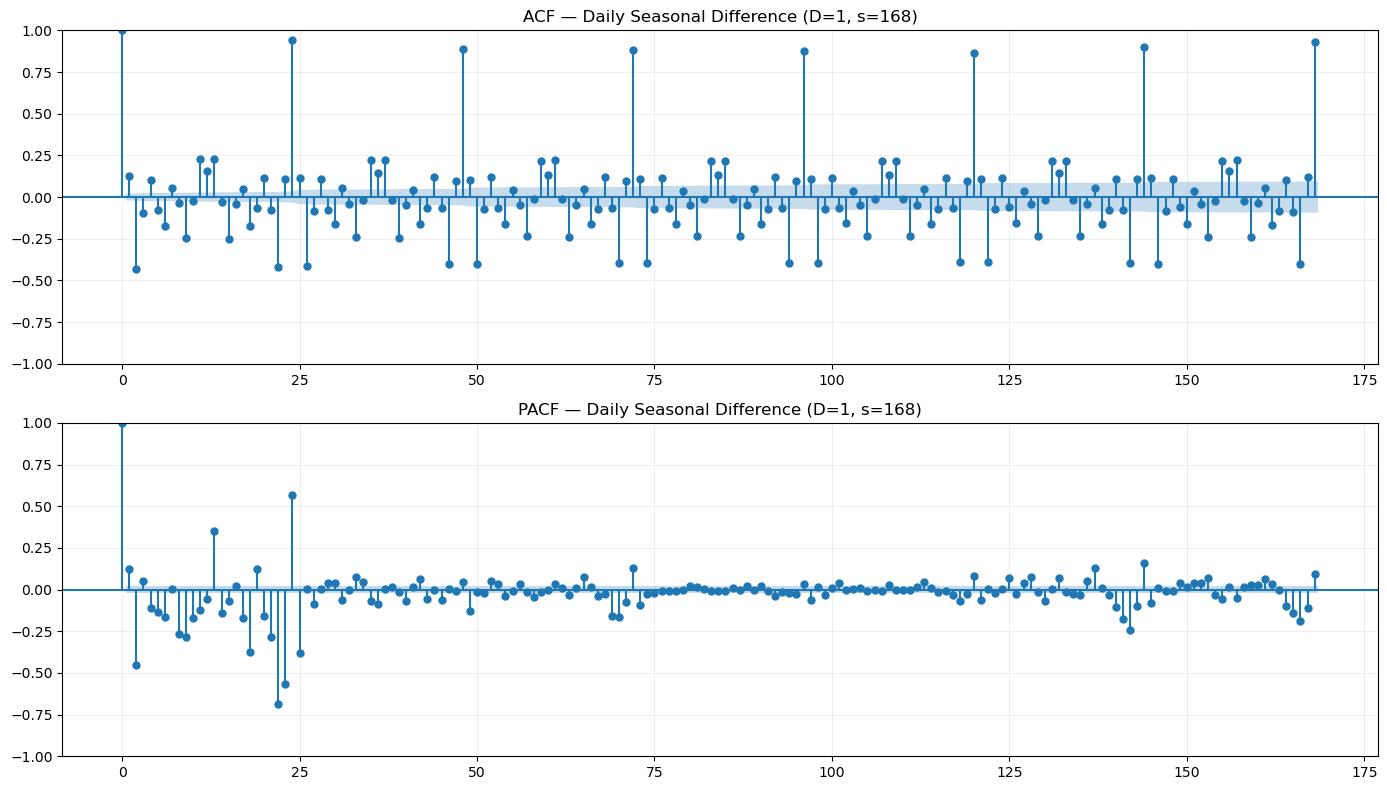

In [32]:
# Daily seasonal differencing
y_diff24 = y.diff().diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(y_diff24, lags=168, ax=axes[0])
axes[0].set_title("ACF — Daily Seasonal Difference (D=1, s=168)")
axes[0].grid(alpha=0.2)

plot_pacf(y_diff24, lags=168, ax=axes[1], method="ywm")
axes[1].set_title("PACF — Daily Seasonal Difference (D=1, s=168)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [117]:

candidates = {
"Diff_24": [
        ((2, 0, 7), (1, 1, 0, 24)),
        ((3, 0, 2), (0, 1, 0, 24)),
        ((3, 0, 7), (1, 1, 0, 24)),
        ((1, 0, 0), (0, 1, 0, 24))
    ]
}

total_models = sum(len(configs) for configs in candidates.values())
current_model = 0

for family, configurations in candidates.items():

    print(f"\n========== {family} ==========", flush=True)

    best_aic.setdefault(family, np.inf)

    for order, seasonal_order in configurations:

        current_model += 1

        # Skip previously tested models
        already_tested = any(
            row["Family"] == family
            and row["Order"] == order
            and row["Seasonal Order"] == seasonal_order
            for row in aic_results
        )

        if already_tested:
            print(f"[{current_model}/{total_models}] SKIPPED (already tested)")
            continue

        start = time.perf_counter()

        print(
            f"\n[{current_model}/{total_models}] START "
            f"SARIMA{order}x{seasonal_order}",
            flush=True
        )

        try:
            model = SARIMAX(
                y_fit,
                order=order,
                seasonal_order=seasonal_order,
                trend="n",
                simple_differencing=False
            )

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result = model.fit(disp=5, maxiter=50)

            converged = result.mle_retvals.get("converged", False)
            elapsed = time.perf_counter() - start

            # Append result instead of resetting
            aic_results.append({
                "Family": family,
                "Order": order,
                "Seasonal Order": seasonal_order,
                "Log-Likelihood": result.llf,
                "k": result.df_model,
                "AIC": result.aic,
                "Converged": converged,
                "Time (s)": elapsed
            })

            print(
                f"[{current_model}/{total_models}] DONE | "
                f"AIC={result.aic:.2f} | "
                f"Converged={converged} | "
                f"Time={elapsed:.1f}s",
                flush=True
            )

            # Update best model for this family
            if converged and np.isfinite(result.aic):
                if result.aic < best_aic[family]:
                    best_aic[family] = result.aic
                    best_models[family] = result

        except Exception as e:
            print(
                f"[{current_model}/{total_models}] FAILED | "
                f"{type(e).__name__}: {e}",
                flush=True
            )


========== Diff_24 ==========

[1/9] START SARIMA(2, 0, 7)x(1, 1, 0, 24)
[1/9] DONE | AIC=135906.23 | Converged=False | Time=58.7s

[2/9] START SARIMA(4, 0, 24)x(1, 1, 0, 24)
[2/9] DONE | AIC=134547.98 | Converged=False | Time=906.7s

[3/9] START SARIMA(3, 0, 20)x(0, 1, 0, 24)
[3/9] DONE | AIC=135619.84 | Converged=False | Time=153.7s

[4/9] START SARIMA(3, 0, 2)x(0, 1, 0, 24)
[4/9] DONE | AIC=136157.31 | Converged=True | Time=7.4s

[5/9] START SARIMA(3, 0, 24)x(0, 1, 0, 24)
[5/9] DONE | AIC=134875.89 | Converged=False | Time=388.3s

[6/9] START SARIMA(3, 0, 7)x(1, 1, 0, 24)
[6/9] DONE | AIC=135957.62 | Converged=False | Time=73.6s

[7/9] START SARIMA(0, 0, 24)x(1, 1, 0, 24)
[7/9] DONE | AIC=145919.49 | Converged=False | Time=829.6s

[8/9] START SARIMA(0, 0, 10)x(0, 1, 0, 24)
[8/9] DONE | AIC=146074.33 | Converged=True | Time=166.6s

[9/9] START SARIMA(1, 0, 0)x(0, 1, 0, 24)
[9/9] DONE | AIC=143453.68 | Converged=True | Time=0.9s


**Outcome Diff(1), Diff(1)** :

- p : [0,1,2,3]
- q : [0,1,2,3]
- P : [0,1,2,3]
- Q : [0,1]
- s : 24

diff_1_1 = {
        ((1, 2, 1), (0, 0, 0, 24))
        ((1, 2, 1), (1, 0, 0, 24))
        ((1, 2, 0), (0, 0, 0, 24))
        ((1, 2, 0), (1, 0, 0, 24))
        ((2, 2, 1), (1, 0, 1, 24))
        ((2, 2, 1), (0, 0, 1, 24))
        ((2, 2, 0), (1, 0, 1, 24))
        ((2, 2, 0), (0, 0, 1, 24))
        }

### **3.4 Box-Jenkins (4) — Model Estimation and AIC Comparison**

We investigate three differencing configurations:

- Ordinary differencing: (d=1,\ D=0,\ s=24).

- Daily seasonal differencing: (d=0,\ D=1,\ s=24).

- Combined ordinary and weekly seasonal differencing: (d=1,\ D=1,\ s=168).

**AIC, MLE, complexité et convergence**

In [33]:
aic_df = pd.DataFrame(aic_results)

display(
    aic_df.sort_values(["Family", "AIC"]).round(2)
)



,Family,Order,Seasonal Order,Log-Likelihood,k,AIC,Converged,Time (s)
1,Diff(1),"(4, 0, 5)","(0, 1, 0, 24)",-67969.99,10,135959.97,False,23.94
4,Diff(1),"(3, 0, 3)","(0, 1, 0, 24)",-68070.76,7,136155.52,True,11.37
3,Diff(1),"(3, 0, 2)","(0, 1, 0, 24)",-68072.65,6,136157.31,True,7.60
2,Diff(1),"(3, 0, 1)","(0, 1, 0, 24)",-68083.65,5,136177.30,True,6.43
0,Diff(1),"(2, 0, 5)","(0, 1, 0, 24)",-68081.45,8,136178.91,False,18.87
5,Diff(1),"(3, 0, 0)","(0, 1, 0, 24)",-68111.44,4,136230.88,True,4.50
8,Diff(1),"(1, 0, 0)","(0, 1, 0, 24)",-71724.84,2,143453.68,True,0.94
6,Diff(1),"(0, 0, 3)","(0, 1, 0, 24)",-73037.65,4,146083.30,True,23.81
7,Diff(1),"(0, 0, 1)","(0, 1, 0, 24)",-78796.09,2,157596.19,True,4.34


In [34]:
# Best converged model per family
best_converged = (
    aic_df[aic_df["Converged"]]
    .sort_values("AIC")
    .groupby("Family")
    .head(1)
)

# Top 2 AIC models per family, regardless of convergence
best_aic_top2 = (
    aic_df[np.isfinite(aic_df["AIC"])]
    .sort_values("AIC")
    .groupby("Family")
    .head(2)
)

# Combine selections and remove duplicates
best_results = (
    pd.concat([best_converged, best_aic_top2])
    .drop_duplicates(subset=["Family", "Order", "Seasonal Order"])
    .sort_values(["Family", "AIC"])
    .reset_index(drop=True)
)

display(best_results)

,Family,Order,Seasonal Order,Log-Likelihood,k,AIC,Converged,Time (s)
0,Diff(1),"(4, 0, 5)","(0, 1, 0, 24)",-67969.986274,10,135959.972547,False,23.935028
1,Diff(1),"(3, 0, 3)","(0, 1, 0, 24)",-68070.758112,7,136155.516225,True,11.369340


### **3.5 Box-Jenkins (5) — Verification: Residual Diagnostics**

Following AIC-based model selection, we examine the residuals of the best converged SARIMA model from each differencing family.

A well-specified forecasting model should leave residuals with no significant remaining autocorrelation.

We investigate:

**Residual time plots:** identify persistent patterns, outliers and changing variance.

**Residual ACF:** detect remaining daily and weekly autocorrelation.

**Ljung-Box test:** assess whether residual autocorrelations are jointly zero.

For the Ljung-Box test:

H₀: All residual autocorrelations up to the tested lag are zero.

H₁: At least one residual autocorrelation is nonzero.

Desired result: p-value > 0.05, meaning we do not reject H₀.

**Residual time plots:**

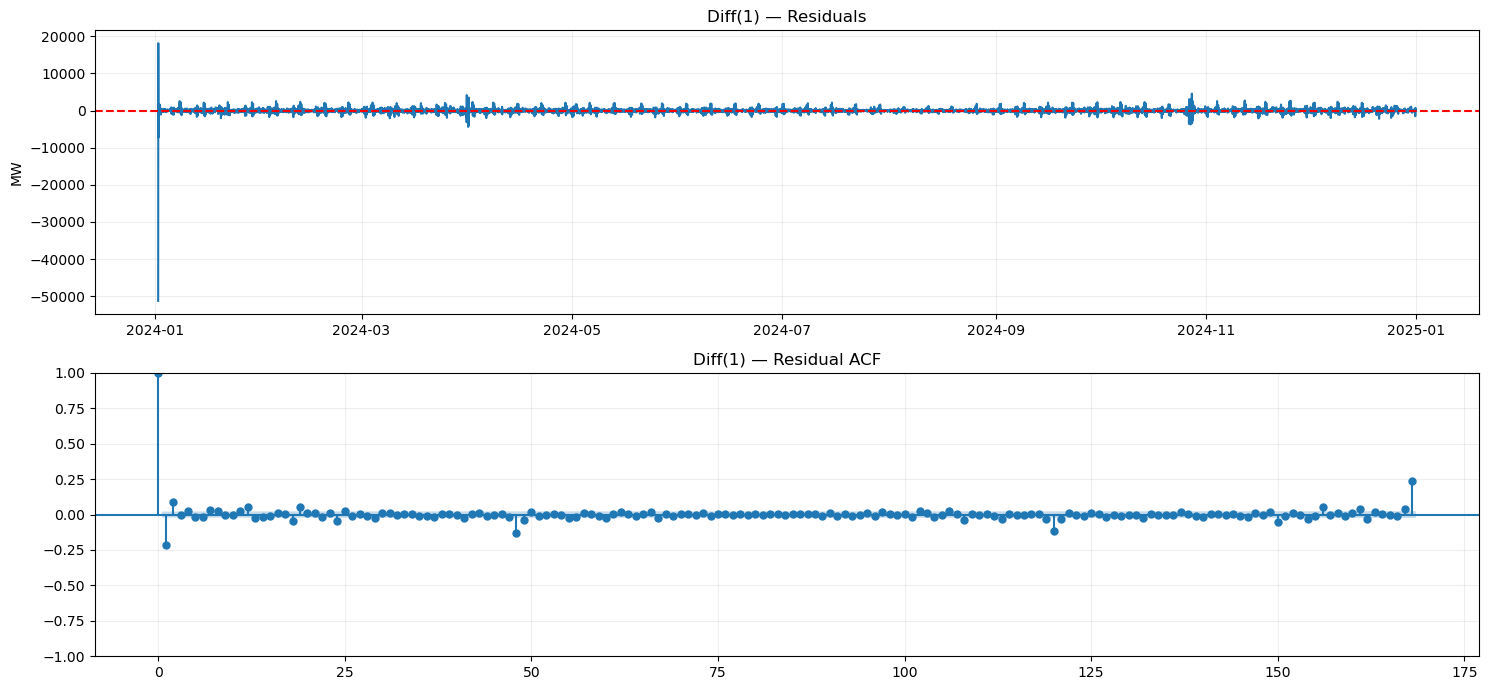

In [35]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

for family, result in best_models.items():

    # Discard initialization observations
    burn = result.loglikelihood_burn
    resid = result.resid.iloc[burn:].dropna()

    fig, axes = plt.subplots(2, 1, figsize=(15, 7))

    axes[0].plot(resid.index, resid)
    axes[0].axhline(0, color="red", linestyle="--")
    axes[0].set_title(f"{family} — Residuals")
    axes[0].set_ylabel("MW")
    axes[0].grid(alpha=0.2)

    plot_acf(resid, lags=168, ax=axes[1])
    axes[1].set_title(f"{family} — Residual ACF")
    axes[1].grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

**Ljung-Box Test**

In [33]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_results = []

for family, result in best_models.items():

    burn = result.loglikelihood_burn
    resid = result.resid.iloc[burn:].dropna()

    lb = acorr_ljungbox(
        resid,
        lags=[1, 24],
        model_df=0,
        return_df=True
    )

    for lag, row in lb.iterrows():
        ljung_results.append({
            "Family": family,
            "Lag": lag,
            "LB Statistic": row["lb_stat"],
            "p-value": row["lb_pvalue"],
            "Reject H0": row["lb_pvalue"] < 0.05
        })

ljung_results = pd.DataFrame(ljung_results)

display(ljung_results.round(4))

,Family,Lag,LB Statistic,p-value,Reject H0
0,Diff(1),1,394.4549,0.0,True
1,Diff(1),24,590.9565,0.0,True


### Residual Diagnostics — Conclusion

The AIC-selected SARIMA models are evaluated using residual plots, autocorrelation diagnostics and Ljung-Box tests at daily (24h) and hourly (1h) lags.

Models displaying significant residual autocorrelation may have failed to capture important temporal dependencies, even when their AIC is relatively low.

These diagnostics will be considered when retaining candidates for day-ahead forecasting validation.

### **3.6 Box-Jenkins (6) — Forecast with Confident Intervals**


After model estimation and residual verification, we evaluate the retained SARIMA candidates under the operational day-ahead forecasting protocol.

For each forecast origin:

- Forecast origin: 11:00 Europe/Paris on day D.

- Target: All 24 local clock-hour slots of day D+1.

- Information cutoff: No observations at or after the forecast origin may be used.

- DST handling: Apply the previously defined alignment and evaluation rules.

- Each model produces point forecasts and 95% prediction intervals.

In [34]:
# Selected SARIMA models from Step 4
selected_models = {}

for family, result in best_models.items():

    selected_models[family] = {
        "order": result.model.order,
        "seasonal_order": result.model.seasonal_order,
        "AIC": result.aic
    }

selected_models_df = pd.DataFrame(selected_models).T

display(selected_models_df)

,AIC,order,seasonal_order
Diff(1),136155.516225,"(3, 0, 3)","(0, 1, 0, 24)"


**Forecast D+1 before 12 a.m. with confidence intervales 95 %**

In [38]:
# Walk-forward validation — fixed SARIMA parameters, expanding history
target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

sarima_val = {}

for family, fitted_result in best_models.items():

    print(f"\nSTART — {family}", flush=True)

    # Keep estimated parameters fixed
    current_result = fitted_result
    last_seen = current_result.model.data.row_labels[-1]

    daily_forecasts = []

    for i, day in enumerate(target_days):

        origin, targets = get_forecast_window(day)

        # Skip origins already covered by the fitted training sample
        if origin <= last_seen:
            continue

        # Add only observations available strictly before 11:00 on D
        new_obs = df.loc[
            (df.index > last_seen) & (df.index < origin),
            "load_mw"
        ]

        if not new_obs.empty:
            current_result = current_result.extend(new_obs)
            last_seen = new_obs.index[-1]

        # Forecast from the last available observation to the end of D+1
        horizon = int(
            (targets[-1] - last_seen) / pd.Timedelta(hours=1)
        )

        fc = current_result.get_forecast(steps=horizon)

        pred = fc.predicted_mean.loc[targets]
        ci = fc.conf_int(alpha=0.05).loc[targets]

        # Convert real UTC hours into 24 French clock-hour slots
        local_hours = targets.tz_convert("Europe/Paris").hour
        duplicates = pd.Index(local_hours).duplicated(keep="last")

        point_24 = np.full(24, np.nan)
        lower_24 = np.full(24, np.nan)
        upper_24 = np.full(24, np.nan)

        for j, (hour, duplicate) in enumerate(zip(local_hours, duplicates)):
            if duplicate:
                continue

            point_24[hour] = pred.iloc[j]
            lower_24[hour] = ci.iloc[j, 0]
            upper_24[hour] = ci.iloc[j, 1]

        daily = pd.DataFrame({
            "prediction": align_24h_forecast(point_24, targets),
            "lower_95": align_24h_forecast(lower_24, targets),
            "upper_95": align_24h_forecast(upper_24, targets)
        })

        daily_forecasts.append(daily)

        if (i + 1) % 30 == 0:
            print(f"{family}: {i + 1}/{len(target_days)} days", flush=True)

    # Store forecasts for this model
    sarima_val[family] = pd.concat(daily_forecasts).sort_index()

    print(f"DONE — {family}", flush=True)


START — Diff(1)
Diff(1): 30/365 days
Diff(1): 60/365 days
Diff(1): 90/365 days
Diff(1): 120/365 days
Diff(1): 150/365 days
Diff(1): 180/365 days
Diff(1): 210/365 days
Diff(1): 240/365 days
Diff(1): 270/365 days
Diff(1): 300/365 days
Diff(1): 330/365 days
Diff(1): 360/365 days
DONE — Diff(1)


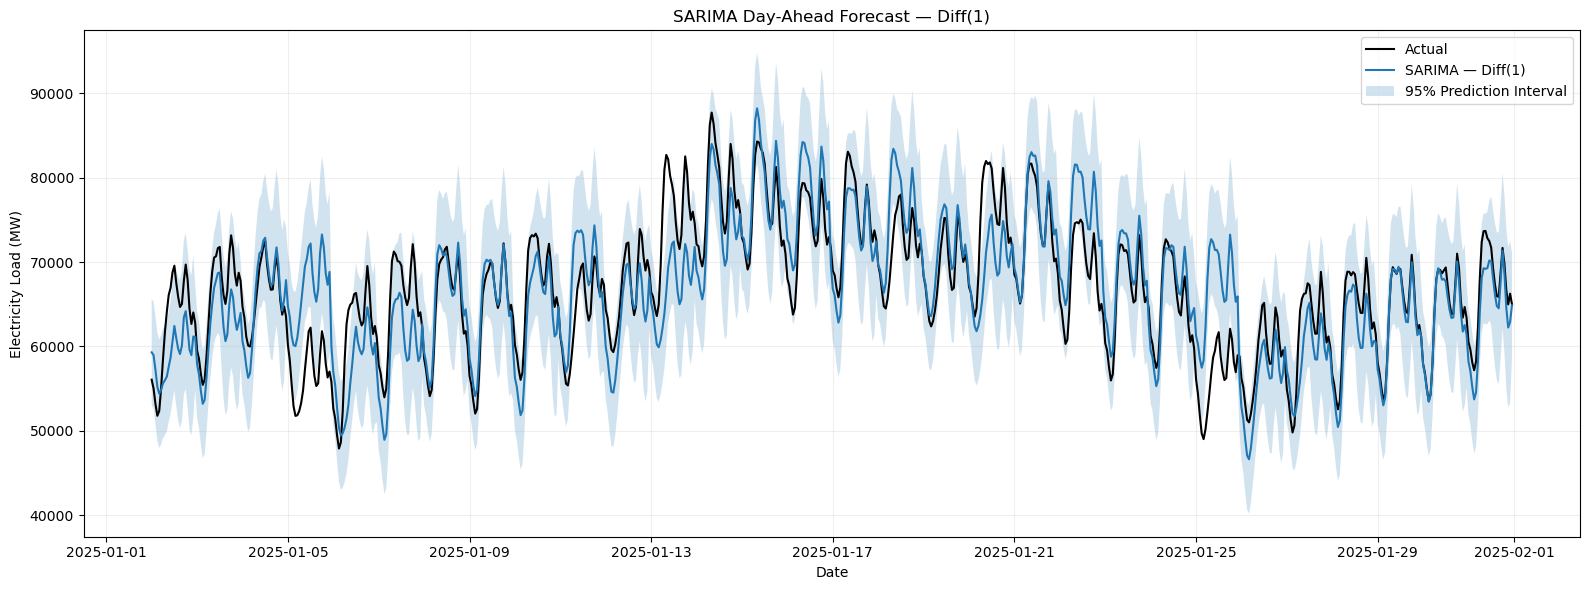

In [39]:
# Plot SARIMA forecasts over one validation month
family = next(iter(sarima_val))

plot_start = "2025-01-02"
plot_end = "2025-01-31"

fc = sarima_val[family].loc[plot_start:plot_end]
actual = df.loc[fc.index, "load_mw"]

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(actual.index, actual, label="Actual", color="black", linewidth=1.5)
ax.plot(fc.index, fc["prediction"], label=f"SARIMA — {family}", linewidth=1.5)

ax.fill_between(
    fc.index,
    fc["lower_95"],
    fc["upper_95"],
    alpha=0.2,
    label="95% Prediction Interval"
)

ax.set_title(f"SARIMA Day-Ahead Forecast — {family}")
ax.set_ylabel("Electricity Load (MW)")
ax.set_xlabel("Date")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Choose the best model**

In [40]:
# Exclude unstable models
models_to_evaluate = {
    family: forecasts
    for family, forecasts in sarima_val.items()
    if family != "diff_1_1"
}

# Common timestamps for all models and benchmarks
common_index = baseline_eval.index

for forecasts in models_to_evaluate.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()

# Keep only timestamps with valid predictions and intervals
for family, forecasts in models_to_evaluate.items():
    valid = forecasts.loc[common_index].notna().all(axis=1)
    valid &= np.isfinite(forecasts.loc[common_index]).all(axis=1)
    common_index = common_index[valid]

assert len(common_index) > 0, "No valid evaluation observations"

y_true = baseline_eval.loc[common_index, "actual"]

comparison = {}

# Baselines
for model in ["seasonal_naive_168h", "rte_d1"]:
    comparison[model] = evaluate_forecast(
        y_true,
        baseline_eval.loc[common_index, model]
    )

# SARIMA models
for family, forecasts in models_to_evaluate.items():

    fc = forecasts.loc[common_index]

    metrics = evaluate_forecast(y_true, fc["prediction"])

    metrics["Coverage 95% (%)"] = (
        (y_true >= fc["lower_95"]) &
        (y_true <= fc["upper_95"])
    ).mean() * 100

    metrics["Avg Interval Width (MW)"] = (
        fc["upper_95"] - fc["lower_95"]
    ).mean()

    comparison[family] = metrics

# Final comparison
comparison_results = (
    pd.DataFrame(comparison)
    .T
    .sort_values("MAPE (%)")
)

print(f"Evaluation observations: {len(common_index)}")
display(comparison_results)

Evaluation observations: 8735


,MAPE (%),MAE (MW),RMSE (MW),Coverage 95% (%),Avg Interval Width (MW)
rte_d1,2.813270,1394.695592,1723.854919,NaN,NaN
Diff(1),5.200698,2629.657946,3807.060533,92.959359,15214.55203
seasonal_naive_168h,6.411190,3448.399313,5135.731668,NaN,NaN


The retained SARIMA model, Diff(1), achieves a MAPE of 5.20%, outperforming the seasonal naive baseline (6.41%) but remaining substantially less accurate than the RTE benchmark (2.81%).

Its 95% prediction intervals achieve 92.96% empirical coverage, below the nominal 95% target, despite a relatively large average width of 15,215 MW.

## **3.7 — SARIMAX with Temperature-Based Exogenous Variables**

We extend SARIMA by introducing two temperature-based explanatory variables:

- **Heating Degree Days (HDD):** \(HDD_t=\max(0,15-T_t)\)
- **Cooling Degree Days (CDD):** \(CDD_t=\max(0,T_t-22)\)

These features approximate heating and cooling demand.

Since the actual temperature of the forecast day is not available at the 11:00 forecast origin, we use **48-hour lagged temperatures** to construct operationally available HDD and CDD features.

We fit a simple SARIMAX model on the training set and evaluate it using the same day-ahead walk-forward validation protocol as our SARIMA models.

The objective is to assess whether incorporating historical temperature information improves forecasting accuracy.

In [41]:
# Temperature available at least 48 hours before the target
temp_lag48 = df["temperature_c"].shift(48)

# Heating and Cooling Degree features
df["HDD"] = (15 - temp_lag48).clip(lower=0)
df["CDD"] = (temp_lag48 - 22).clip(lower=0)

exog_cols = ["HDD", "CDD"]

display(df[["temperature_c", "HDD", "CDD"]].head(55).tail(10))

,temperature_c,HDD,CDD
datetime_utc,,,
2019-01-02 21:00:00+00:00,3.40,NaN,NaN
2019-01-02 22:00:00+00:00,3.07,NaN,NaN
2019-01-02 23:00:00+00:00,2.47,NaN,NaN
2019-01-03 00:00:00+00:00,2.26,9.15,0.0
2019-01-03 01:00:00+00:00,2.30,8.65,0.0
2019-01-03 02:00:00+00:00,2.13,9.09,0.0
2019-01-03 03:00:00+00:00,2.00,9.30,0.0
2019-01-03 04:00:00+00:00,1.58,9.28,0.0
2019-01-03 05:00:00+00:00,1.62,9.32,0.0


In [42]:
# Training data — 2024
train_sarimax = df.loc["2024-01-01":"2024-12-31"]

y_sarimax = train_sarimax["load_mw"].asfreq("h")
X_sarimax = train_sarimax[exog_cols].asfreq("h")

# Fit SARIMAX
sarimax_model = SARIMAX(
    y_sarimax,
    exog=X_sarimax,
    order=(3, 0, 3),
    seasonal_order=(0, 1, 0, 24),
    trend="n"
)

sarimax_result = sarimax_model.fit(
    disp=False,
    maxiter=60
)

print(f"AIC: {sarimax_result.aic:.2f}")
print(f"Converged: {sarimax_result.mle_retvals['converged']}")

display(sarimax_result.params)

AIC: 136205.36
Converged: True


HDD          -21.373471
CDD           51.441369
ar.L1          2.014855
ar.L2         -1.456855
ar.L3          0.413590
ma.L1         -0.038140
ma.L2         -0.115244
ma.L3          0.047876
sigma2    277067.153156
dtype: float64

In [44]:
# Walk-forward SARIMAX validation
import warnings
from statsmodels.tools.sm_exceptions import ValueWarning

# Suppress statsmodels frequency inference warnings
warnings.filterwarnings(
    "ignore",
    message="No frequency information was provided, so inferred frequency",
    category=ValueWarning
)

target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

current_result = sarimax_result
last_seen = y_sarimax.index[-1]
import warnings
from statsmodels.tools.sm_exceptions import ValueWarning

# Suppress statsmodels frequency inference warnings
warnings.filterwarnings(
    "ignore",
    message="No frequency information was provided, so inferred frequency",
    category=ValueWarning
)

daily_forecasts = []

for i, day in enumerate(target_days):

    origin, targets = get_forecast_window(day)

    if origin <= last_seen:
        continue

    # Update with observations and exogenous features available before origin
    new_times = df.index[
        (df.index > last_seen) & (df.index < origin)
    ]

    if len(new_times):
        current_result = current_result.extend(
            endog=df.loc[new_times, "load_mw"],
            exog=df.loc[new_times, exog_cols]
        )
        last_seen = new_times[-1]

    # Full forecasting horizon
    future_times = pd.date_range(
        last_seen + pd.Timedelta(hours=1),
        targets[-1],
        freq="h"
    )

    X_future = df.loc[future_times, exog_cols]

    # Verify availability of source temperatures at forecast origin
    assert (future_times - pd.Timedelta(hours=48) < origin).all()
    assert X_future.notna().all().all()

    forecast = current_result.get_forecast(
        steps=len(future_times),
        exog=X_future
    )

    pred = forecast.predicted_mean.loc[targets]
    ci = forecast.conf_int(alpha=0.05).loc[targets]

    # DST alignment
    local_hours = targets.tz_convert("Europe/Paris").hour
    duplicates = pd.Index(local_hours).duplicated(keep="last")

    point_24 = np.full(24, np.nan)
    lower_24 = np.full(24, np.nan)
    upper_24 = np.full(24, np.nan)

    for j, (hour, duplicate) in enumerate(zip(local_hours, duplicates)):

        if duplicate:
            continue

        point_24[hour] = pred.iloc[j]
        lower_24[hour] = ci.iloc[j, 0]
        upper_24[hour] = ci.iloc[j, 1]

    daily_forecasts.append(pd.DataFrame({
        "prediction": align_24h_forecast(point_24, targets),
        "lower_95": align_24h_forecast(lower_24, targets),
        "upper_95": align_24h_forecast(upper_24, targets)
    }))

    if (i + 1) % 30 == 0:
        print(f"SARIMAX: {i + 1}/{len(target_days)} days", flush=True)

sarimax_val = pd.concat(daily_forecasts).sort_index()

print("SARIMAX validation completed")

SARIMAX: 30/365 days
SARIMAX: 60/365 days
SARIMAX: 90/365 days
SARIMAX: 120/365 days
SARIMAX: 150/365 days
SARIMAX: 180/365 days
SARIMAX: 210/365 days
SARIMAX: 240/365 days
SARIMAX: 270/365 days
SARIMAX: 300/365 days
SARIMAX: 330/365 days
SARIMAX: 360/365 days
SARIMAX validation completed


### **Statistical Models Comparison**

We compare the retained **SARIMA and SARIMAX models** against the RTE D+1 and seasonal naive benchmarks.

To ensure a fair comparison, all models are evaluated on the **same valid timestamps** during the 2025 validation period.

Performance is assessed using:

- **MAPE, MAE, RMSE:** point forecast accuracy.
- **95% Coverage:** proportion of actual observations within the prediction intervals.
- **Average Interval Width:** average uncertainty range in MW.

Models are ranked by **MAPE (ascending)** to identify the most accurate statistical forecasting approach and assess whether adding weather-related regressors improves SARIMA performance.

In [45]:
# Include retained SARIMA models and SARIMAX
models_to_evaluate = {
    family: forecasts
    for family, forecasts in sarima_val.items()
    if family != "diff_1_1"
}

models_to_evaluate["SARIMAX (HDD + CDD)"] = sarimax_val

# Common evaluation timestamps
common_index = baseline_eval.index

for forecasts in models_to_evaluate.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()

# Keep identical valid observations across all models
for forecasts in models_to_evaluate.values():
    values = forecasts.loc[common_index]
    valid = pd.Series(
        np.isfinite(values.to_numpy()).all(axis=1),
        index=common_index
    )
    common_index = common_index[valid]

assert len(common_index) > 0, "No common valid observations"

y_true = baseline_eval.loc[common_index, "actual"]

comparison = {}

# Benchmarks
for model in ["seasonal_naive_168h", "rte_d1"]:
    comparison[model] = evaluate_forecast(
        y_true,
        baseline_eval.loc[common_index, model]
    )

# Statistical models
for family, forecasts in models_to_evaluate.items():

    fc = forecasts.loc[common_index]

    metrics = evaluate_forecast(y_true, fc["prediction"])

    metrics["Coverage 95% (%)"] = (
        (y_true >= fc["lower_95"]) &
        (y_true <= fc["upper_95"])
    ).mean() * 100

    metrics["Avg Interval Width (MW)"] = (
        fc["upper_95"] - fc["lower_95"]
    ).mean()

    comparison[family] = metrics

comparison_results = (
    pd.DataFrame(comparison)
    .T
    .sort_values("MAPE (%)")
)

print(f"Evaluation observations: {len(common_index)}")
display(comparison_results.round(2))

Evaluation observations: 8735


,MAPE (%),MAE (MW),RMSE (MW),Coverage 95% (%),Avg Interval Width (MW)
rte_d1,2.81,1394.70,1723.85,NaN,NaN
Diff(1),5.20,2629.66,3807.06,92.96,15214.55
SARIMAX (HDD + CDD),5.22,2636.01,3810.78,92.95,15272.17
seasonal_naive_168h,6.41,3448.40,5135.73,NaN,NaN


### **3.8 — Holt-Winters Exponential Smoothing**

We evaluate Holt-Winters as an alternative statistical forecasting approach.

Unlike SARIMA, Holt-Winters explicitly models three components through exponential smoothing:

- **Level:** the underlying consumption level.
- **Trend:** the local evolution of electricity demand.
- **Seasonality:** the recurring daily consumption pattern.

Based on our exploratory analysis, we select an additive seasonal model with a 24-hour period and a damped additive trend.

Model smoothing parameters are estimated on the training set. During walk-forward validation, the historical level, trend and seasonal states are updated using only observations available before the 11:00 forecast origin.

We evaluate day-ahead predictions on 2025 using MAPE, MAE and RMSE, and compare Holt-Winters against SARIMA, SARIMAX and the existing benchmarks.

In [48]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import pandas as pd
import numpy as np
import time
import warnings

# Training data — 2024
y_hw = train.loc["2024-01-01":"2024-12-31", "load_mw"].asfreq("h")

hw_configs = [
    {"trend": None,  "damped_trend": False, "seasonal": "add", "seasonal_periods": 24},
    {"trend": "add", "damped_trend": True, "seasonal": "mul", "seasonal_periods": 168},
    {"trend": "add", "damped_trend": True,  "seasonal": "add", "seasonal_periods": 24},
    {"trend": "add", "damped_trend": True,  "seasonal": "mul", "seasonal_periods": 24},
]

hw_models = {}
hw_results = []

for i, config in enumerate(hw_configs, start=1):

    name = f"HW_{i}"
    start = time.perf_counter()

    print(f"[{i}/{len(hw_configs)}] Training {name}", flush=True)

    try:
        model = ExponentialSmoothing(
            y_hw,
            **config,
            initialization_method="estimated"
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            result = model.fit(optimized=True)

        hw_models[name] = result

        hw_results.append({
            "Model": name,
            **config,
            "AIC": result.aic,
            "SSE": result.sse,
            "Alpha": result.params["smoothing_level"],
            "Beta": result.params["smoothing_trend"],
            "Gamma": result.params["smoothing_seasonal"],
            "Phi": result.params["damping_trend"],
            "Time (s)": time.perf_counter() - start
        })

        print(f"DONE — {name} | AIC={result.aic:.2f}", flush=True)

    except Exception as e:
        print(f"FAILED — {name}: {e}", flush=True)

hw_results_df = pd.DataFrame(hw_results).sort_values("AIC")

display(hw_results_df.round(4))

[1/4] Training HW_1


DONE — HW_1 | AIC=118891.20
[2/4] Training HW_2
DONE — HW_2 | AIC=121930.71
[3/4] Training HW_3
DONE — HW_3 | AIC=118905.61
[4/4] Training HW_4
DONE — HW_4 | AIC=119395.59


,Model,trend,damped_trend,seasonal,seasonal_periods,AIC,SSE,Alpha,Beta,Gamma,Phi,Time (s)
0,HW_1,None,False,add,24,118891.2021,6.605489e+09,0.8300,NaN,0.1700,NaN,0.0903
2,HW_3,add,True,add,24,118905.6134,6.611818e+09,0.8182,0.0001,0.1818,0.99,0.6520
3,HW_4,add,True,mul,24,119395.5927,6.991155e+09,0.8536,0.0001,0.1464,0.99,0.6959
1,HW_2,add,True,mul,168,121930.7099,9.029476e+09,0.4646,0.0001,0.5354,0.99,0.7763


### **Validation**

In [49]:
hw_val_models = {}

for name, trained in hw_models.items():

    print(f"\nSTART — {name}", flush=True)

    config = hw_configs[int(name.split("_")[1]) - 1]
    params = trained.params

    daily_forecasts = []

    for i, day in enumerate(target_days):

        origin, targets = get_forecast_window(day)

        # Skip origins overlapping training data
        if origin <= y_hw.index[-1]:
            continue

        # Historical observations available strictly before origin
        last_available = origin - pd.Timedelta(hours=1)

        history = df.loc[
            y_hw.index[0]:last_available, "load_mw"
        ].asfreq("h")

        # Update states using fixed smoothing parameters
        model = ExponentialSmoothing(
            history,
            **config,
            initialization_method="known",
            initial_level=params["initial_level"],
            initial_trend=(
                params["initial_trend"]
                if config["trend"] is not None else None
            ),
            initial_seasonal=params["initial_seasons"]
        )

        fitted = model.fit(
            smoothing_level=params["smoothing_level"],
            smoothing_trend=params["smoothing_trend"],
            smoothing_seasonal=params["smoothing_seasonal"],
            damping_trend=params["damping_trend"],
            optimized=False
        )

        # Forecast through the end of D+1
        horizon = int(
            (targets[-1] - last_available) / pd.Timedelta(hours=1)
        )

        pred = fitted.forecast(horizon).loc[targets]

        # DST alignment
        local_hours = targets.tz_convert("Europe/Paris").hour
        duplicates = pd.Index(local_hours).duplicated(keep="last")

        point_24 = np.full(24, np.nan)

        for j, (hour, duplicate) in enumerate(zip(local_hours, duplicates)):
            if not duplicate:
                point_24[hour] = pred.iloc[j]

        daily_forecasts.append(
            align_24h_forecast(point_24, targets)
        )

        if (i + 1) % 30 == 0:
            print(f"{name}: {i + 1}/{len(target_days)} days", flush=True)

    hw_val_models[name] = (
        pd.concat(daily_forecasts)
        .sort_index()
        .to_frame("prediction")
    )

    print(f"DONE — {name}", flush=True)


START — HW_1
HW_1: 30/365 days
HW_1: 60/365 days
HW_1: 90/365 days
HW_1: 120/365 days
HW_1: 150/365 days
HW_1: 180/365 days
HW_1: 210/365 days
HW_1: 240/365 days
HW_1: 270/365 days
HW_1: 300/365 days
HW_1: 330/365 days
HW_1: 360/365 days
DONE — HW_1

START — HW_2
HW_2: 30/365 days
HW_2: 60/365 days
HW_2: 90/365 days
HW_2: 120/365 days
HW_2: 150/365 days
HW_2: 180/365 days
HW_2: 210/365 days
HW_2: 240/365 days
HW_2: 270/365 days
HW_2: 300/365 days
HW_2: 330/365 days
HW_2: 360/365 days
DONE — HW_2

START — HW_3
HW_3: 30/365 days
HW_3: 60/365 days
HW_3: 90/365 days
HW_3: 120/365 days
HW_3: 150/365 days
HW_3: 180/365 days
HW_3: 210/365 days
HW_3: 240/365 days
HW_3: 270/365 days
HW_3: 300/365 days
HW_3: 330/365 days
HW_3: 360/365 days
DONE — HW_3

START — HW_4
HW_4: 30/365 days
HW_4: 60/365 days
HW_4: 90/365 days
HW_4: 120/365 days
HW_4: 150/365 days
HW_4: 180/365 days
HW_4: 210/365 days
HW_4: 240/365 days
HW_4: 270/365 days
HW_4: 300/365 days
HW_4: 330/365 days
HW_4: 360/365 days
DONE — H

### **Calculating Confidence Intervals** for Holt-Winter models 

In [50]:
# --------------------------------------------------
# HOLT-WINTERS — HOURLY CONFORMAL PREDICTION INTERVALS
# --------------------------------------------------

import numpy as np
import pandas as pd

ALPHA = 0.05
SPLIT_DATE = pd.Timestamp("2025-07-01", tz="Europe/Paris")

def conformal_quantile(errors, alpha=ALPHA):
    errors = np.sort(np.asarray(errors.dropna()))
    n = len(errors)
    rank = int(np.ceil((n + 1) * (1 - alpha)))
    return errors[rank - 1] if rank <= n else np.inf

for name, forecasts in hw_val_models.items():

    # Use only originally valid observations
    data = forecasts[["prediction"]].join(
        baseline_eval[["actual"]], how="inner"
    ).dropna().sort_index()

    data["hour_fr"] = data.index.tz_convert("Europe/Paris").hour

    # Calibrate on January–June 2025
    calibration = data[
        data.index.tz_convert("Europe/Paris") < SPLIT_DATE
    ].copy()

    calibration["abs_error"] = (
        calibration["actual"] - calibration["prediction"]
    ).abs()

    margins = calibration.groupby("hour_fr")["abs_error"].apply(
        conformal_quantile, alpha=ALPHA
    )

    # Add prediction intervals to the original forecast DataFrame
    hours = forecasts.index.tz_convert("Europe/Paris").hour
    margin = pd.Series(hours, index=forecasts.index).map(margins)

    hw_val_models[name]["lower_95"] = forecasts["prediction"] - margin
    hw_val_models[name]["upper_95"] = forecasts["prediction"] + margin

    # Evaluate on July–December 2025 only
    evaluation = data[
        data.index.tz_convert("Europe/Paris") >= SPLIT_DATE
    ].join(hw_val_models[name][["lower_95", "upper_95"]]).dropna()

    coverage = (
        (evaluation["actual"] >= evaluation["lower_95"]) &
        (evaluation["actual"] <= evaluation["upper_95"])
    ).mean() * 100

    width = (
        evaluation["upper_95"] - evaluation["lower_95"]
    ).mean()

    print(f"{name}: Coverage = {coverage:.2f}% | Width = {width:.0f} MW")

HW_1: Coverage = 96.24% | Width = 20631 MW
HW_2: Coverage = 99.05% | Width = 20541 MW
HW_3: Coverage = 96.65% | Width = 20705 MW
HW_4: Coverage = 97.71% | Width = 21316 MW


In [51]:
# Collect all statistical models
models_to_evaluate = {
    family: forecasts
    for family, forecasts in sarima_val.items()
    if family != "diff_1_1"
}

models_to_evaluate["SARIMAX (HDD + CDD)"] = sarimax_val

for name, forecasts in hw_val_models.items():
    models_to_evaluate[name] = forecasts

# Common evaluation timestamps
common_index = baseline_eval.index

for forecasts in models_to_evaluate.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()

# Keep only timestamps with finite point forecasts
for forecasts in models_to_evaluate.values():
    prediction = forecasts.loc[common_index, "prediction"]
    common_index = common_index[np.isfinite(prediction.to_numpy())]

assert len(common_index) > 0, "No common valid observations"

y_true = baseline_eval.loc[common_index, "actual"]

comparison = {}

# Benchmarks
for name in ["seasonal_naive_168h", "rte_d1"]:
    comparison[name] = evaluate_forecast(
        y_true,
        baseline_eval.loc[common_index, name]
    )

# Statistical models
for name, forecasts in models_to_evaluate.items():

    fc = forecasts.loc[common_index]

    metrics = evaluate_forecast(y_true, fc["prediction"])

    # Prediction intervals, if available
    if {"lower_95", "upper_95"}.issubset(fc.columns):

        valid_intervals = (
            np.isfinite(fc["lower_95"]) &
            np.isfinite(fc["upper_95"])
        )

        if valid_intervals.all():

            metrics["Coverage 95% (%)"] = (
                (y_true >= fc["lower_95"]) &
                (y_true <= fc["upper_95"])
            ).mean() * 100

            metrics["Avg Interval Width (MW)"] = (
                fc["upper_95"] - fc["lower_95"]
            ).mean()

    comparison[name] = metrics

comparison_results = (
    pd.DataFrame(comparison)
    .T
    .sort_values("MAPE (%)")
)

print(f"Evaluation observations: {len(common_index)}")
display(comparison_results.round(2))

Evaluation observations: 8735


,MAPE (%),MAE (MW),RMSE (MW),Coverage 95% (%),Avg Interval Width (MW)
rte_d1,2.81,1394.70,1723.85,NaN,NaN
Diff(1),5.20,2629.66,3807.06,92.96,15214.55
SARIMAX (HDD + CDD),5.22,2636.01,3810.78,92.95,15272.17
HW_2,6.36,3290.91,4333.84,97.32,20541.01
seasonal_naive_168h,6.41,3448.40,5135.73,NaN,NaN
HW_4,7.57,3795.15,4976.86,96.65,21316.66
HW_3,7.60,3751.10,4950.05,96.11,20705.13
HW_1,7.66,3783.73,4980.57,95.90,20631.54


### **3.9 — Statistical Models:**

The statistical forecasting models remain significantly less accurate than the **RTE D+1 benchmark (MAPE: 2.81%)**.

- **SARIMA Diff(1)** achieves the best statistical performance (MAPE: 5.20%), while adding weather regressors through **SARIMAX (5.22%)** provides no measurable improvement.
- **Holt-Winters** performs worse overall, with MAPE values ranging from 6.36% to 7.66%.
- **Prediction intervals** reveal additional limitations: SARIMA/SARIMAX achieve approximately 93% coverage, below the nominal 95%, while Holt-Winters achieves higher coverage (96–97%) but with substantially wider intervals (approximately 20,500–21,300 MW).

**Conclusion:** Classical statistical models capture some temporal patterns but fail to outperform RTE's operational forecasts. Their limited accuracy and relatively wide uncertainty intervals motivate the transition to **machine learning**, particularly LightGBM, to model nonlinear relationships and directly correct RTE forecasting errors.

## **4. Machine Learning — LightGBM**

We now investigate gradient boosting approaches for day-ahead electricity demand forecasting using LightGBM.

Unlike the statistical models explored previously, LightGBM learns nonlinear relationships between electricity consumption, calendar effects, historical demand and temperature-based features.

We adopt a **global direct multi-horizon forecasting strategy**: one model predicts each target hour independently using its associated features, without recursively feeding previous predictions into subsequent horizons.

All models follow the same operational forecasting protocol: predictions are issued at **11:00 Europe/Paris on day D** for the 24 local clock-hour slots of D+1.

### Section Overview

**4.1 — Feature Engineering**

Transform the hourly time series into a supervised tabular dataset, including historical consumption, lagged temperature, calendar indicators and RTE forecast information.

Two calendar representations will be constructed: detailed binary flags and aggregated positive/negative activity flags.

**4.2 — Direct LightGBM**

Train models to predict electricity consumption directly, comparing detailed and aggregated calendar features.

**4.3 — Trend + LightGBM**

Estimate a local trend using historical observations and train LightGBM to predict the remaining consumption component. Compare both calendar representations.

**4.4 — RTE Error Correction with LightGBM**

Train LightGBM to predict and correct RTE day-ahead forecast errors, first using historical RTE errors and then incorporating the most promising calendar and weather features.

We assume that the RTE D+1 forecasts are available at the 11:00 forecast origin. This assumption will be explicitly acknowledged as a methodological limitation.

**4.5 — Hyperparameter Tuning & Walk-forward Validation**

Optimize promising configurations and evaluate all candidates on the 2025 validation set using the same timestamps, forecast origins and DST conventions.

MAPE is the primary model-selection metric, complemented by MAE and RMSE.

**4.6 — Comparison with Statistical Models and Benchmarks**

Compare the LightGBM variants against the previously evaluated SARIMA, SARIMAX, Holt-Winters, Seasonal Naive and RTE D+1 models stored in `comparison_results`.

The strongest configurations will be retained for final evaluation on the untouched 2026 test set.

### **4.1 — Feature Engineering: Calendar-Based Features**

Electricity demand is influenced by human activity patterns, including working days, holidays, seasons, and daily consumption cycles.

To incorporate this domain knowledge, we designed **calendar-based features using French local time (`Europe/Paris`)**, while retaining UTC timestamps for temporal alignment.

Rather than relying only on categorical calendar variables, we constructed a **heuristic scoring system** representing expected increases or decreases in electricity demand.

#### Calendar Scoring Rules

| Component | Conditions | Score |
|---|---|---:|
| **Season** | Winter (Dec–Feb) | +2 |
| | Summer (Jun–Aug) | −2 |
| | Summer transition periods | −1 |
| | Other periods | 0 |
| **Holiday period** | Regular activity | +2 |
| | School holidays only | −1 |
| | Business holidays only | −2 |
| | Both holiday categories | −3 |
| **Day** | Weekday | +1 |
| | Weekend | −1 |
| | Business holiday period | Additional −1 |
| **Hour** | 05:00–08:00 or 17:00–19:00 | +1 |
| | Other hours | −1 |

Holiday periods were approximated using recurring date ranges rather than official year-specific regional calendars.

#### Feature Aggregation

Two synthetic calendar indicators were created:

**Unweighted calendar score:**

$$
CalendarScore = Season + Holiday + Day + Hour
$$

**Weighted calendar score:**

$$
CalendarScore_{weighted} =
\frac{4\,Season + Holiday + 2\,Day + 8\,Hour}{15}
$$

The weighted version emphasizes **intraday consumption patterns**, followed by seasonal and weekday effects.

These scores are **domain-informed assumptions, not statistically estimated coefficients**. LightGBM subsequently learns how to use them, including nonlinear interactions with weather and historical demand variables.

The weighted indicator, `calendar_amplify_ewa`, was retained in our best-performing **RTE + LightGBM error-correction model**.

In [21]:
CALENDAR_CONFIG = {

    # 1. SEASONAL ACTIVITY
    "season": {
        "winter": {
            "periods": [("12-01", "02-28")],
            "score": +2
        },
        "summer": {
            "periods": [("06-01", "08-31")],
            "score": -2
        },
        "marginal_summer": {
            "periods": [
                ("05-15", "05-31"),
                ("09-01", "10-15")
            ],
            "score": -1
        },
        "other": {
            "score": 0
        }
    },

    # 2. HOLIDAY ACTIVITY
    "month": {
        "business_holiday": {
            "periods": [
                ("12-15", "01-05"),
                ("07-15", "08-31")
            ],
            "score": -2
        },

        "school_holiday": {
            "periods": [
                ("12-21", "01-04"),  # Christmas
                ("02-15", "03-01"),  # Winter
                ("04-12", "04-25"),  # Spring
                ("07-06", "08-31"),  # Summer
                ("10-20", "11-02")   # All Saints
            ],
            "score": -1
        },

        "normal_score": +2,
        "both_score": -3
    },

    # 3. WEEKLY ACTIVITY
    "day": {
        "business_days": [0, 1, 2, 3, 4],
        "business_score": +1,

        "weekend_days": [5, 6],
        "weekend_score": -1,

        # Additional score during business holidays only
        "business_holiday_bonus": -1
    },

    # 4. HOURLY ACTIVITY
    "hour": {
        "activity_hours": [
            (5, 9),
            (17, 20)
        ],
        "activity_score": +1,
        "inactivity_score": -1
    }
}

In [22]:
import numpy as np
import pandas as pd

# Copy the original dataset
ml_data = df.copy()

# Target timestamps in French local time
fr = ml_data.index.tz_convert("Europe/Paris")

# Raw calendar metadata
ml_data["target_hour"] = fr.hour
ml_data["target_day_of_week"] = fr.dayofweek
ml_data["target_month"] = fr.month

# Month-day representation for recurring annual periods
month_day = pd.Series(fr.strftime("%m-%d"), index=ml_data.index)


def in_periods(month_day, periods):
    """Return a mask for inclusive recurring calendar periods."""
    mask = pd.Series(False, index=month_day.index)

    for start, end in periods:
        if start <= end:
            mask |= month_day.between(start, end)
        else:
            # Handle periods crossing New Year
            mask |= (month_day >= start) | (month_day <= end)

    return mask


# 1. SEASON
season_cfg = CALENDAR_CONFIG["season"]

winter = in_periods(
    month_day, season_cfg["winter"]["periods"]
) | month_day.eq("02-29")

summer = in_periods(
    month_day, season_cfg["summer"]["periods"]
)

marginal = in_periods(
    month_day, season_cfg["marginal_summer"]["periods"]
)

ml_data["season"] = np.select(
    [winter, summer, marginal],
    [
        season_cfg["winter"]["score"],
        season_cfg["summer"]["score"],
        season_cfg["marginal_summer"]["score"]
    ],
    default=season_cfg["other"]["score"]
)


# 2. HOLIDAY / MONTH
month_cfg = CALENDAR_CONFIG["month"]

business_holiday = in_periods(
    month_day, month_cfg["business_holiday"]["periods"]
)

school_holiday = in_periods(
    month_day, month_cfg["school_holiday"]["periods"]
)

ml_data["month"] = np.select(
    [
        business_holiday & school_holiday,
        business_holiday,
        school_holiday
    ],
    [
        month_cfg["both_score"],
        month_cfg["business_holiday"]["score"],
        month_cfg["school_holiday"]["score"]
    ],
    default=month_cfg["normal_score"]
)


# 3. WEEKLY ACTIVITY / DAY
day_cfg = CALENDAR_CONFIG["day"]

business_day = ml_data["target_day_of_week"].isin(
    day_cfg["business_days"]
)

ml_data["day"] = np.where(
    business_day,
    day_cfg["business_score"],
    day_cfg["weekend_score"]
)

# Business holiday penalty (school holidays excluded)
ml_data["day"] += (
    business_holiday.astype(int)
    * day_cfg["business_holiday_bonus"]
)


# 4. HOURLY ACTIVITY / HOUR
hour_cfg = CALENDAR_CONFIG["hour"]

activity = pd.Series(False, index=ml_data.index)

for start, end in hour_cfg["activity_hours"]:
    activity |= ml_data["target_hour"].between(
        start, end - 1
    )

ml_data["hour"] = np.where(
    activity,
    hour_cfg["activity_score"],
    hour_cfg["inactivity_score"]
)


# 5. CALENDAR AGGREGATION
calendar_cols = ["season", "month", "day", "hour"]

ml_data["calendar_amplify"] = ml_data[calendar_cols].sum(axis=1)

# Exponentially decreasing weights: hour > season > day > month
ewa_weights = {
    "hour": 8,
    "season": 4,
    "day": 2,
    "month": 1
}

total_weight = sum(ewa_weights.values())

ml_data["calendar_amplify_ewa"] = sum(
    ml_data[col] * weight
    for col, weight in ewa_weights.items()
) / total_weight


# Sanity checks
assert ml_data[calendar_cols].notna().all().all()
assert ml_data["calendar_amplify"].equals(
    ml_data[calendar_cols].sum(axis=1)
)

display(
    ml_data[
        [
            "target_hour", "target_day_of_week",
            "season", "month", "day", "hour",
            "calendar_amplify", "calendar_amplify_ewa"
        ]
    ].head(10)
)

,target_hour,target_day_of_week,season,month,day,hour,calendar_amplify,calendar_amplify_ewa
datetime_utc,,,,,,,,
2019-01-01 00:00:00+00:00,1,1,2,-3,0,-1,-2,-0.200000
2019-01-01 01:00:00+00:00,2,1,2,-3,0,-1,-2,-0.200000
2019-01-01 02:00:00+00:00,3,1,2,-3,0,-1,-2,-0.200000
2019-01-01 03:00:00+00:00,4,1,2,-3,0,-1,-2,-0.200000
2019-01-01 04:00:00+00:00,5,1,2,-3,0,1,0,0.866667
2019-01-01 05:00:00+00:00,6,1,2,-3,0,1,0,0.866667
2019-01-01 06:00:00+00:00,7,1,2,-3,0,1,0,0.866667
2019-01-01 07:00:00+00:00,8,1,2,-3,0,1,0,0.866667
2019-01-01 08:00:00+00:00,9,1,2,-3,0,-1,-2,-0.200000


### **Historical Load & Weather Features**

To capture temporal dependencies and weather-related demand variations, we construct historical features using only information available **before the day-ahead forecast origin (D at 11:00, Europe/Paris)**.

| Feature | Definition | Purpose |
|---|---|---|
| `load_lag_48h` | Electricity load at t−48h | Capture recent demand patterns |
| `load_lag_168h` | Electricity load at t−168h | Capture weekly seasonality |
| `temperature_lag_48h` | Temperature at t−48h | Incorporate historical weather conditions |
| `HDD_48h` | max(0, 15 − Temperature at t−48h) | Approximate heating demand |
| `CDD_48h` | max(0, Temperature at t−48h − 22) | Approximate cooling demand |

**Heating Degree Days (HDD)** and **Cooling Degree Days (CDD)** represent temperature deviations from predefined thresholds (15°C and 22°C). Here, they are computed from individual hourly temperatures rather than accumulated over entire days.

All lags are calculated on the continuous **UTC hourly index**, ensuring consistent elapsed-time offsets across daylight saving transitions.

**Leakage prevention:** the 48h and 168h offsets ensure these features refer to historical observations available before the forecast deadline for every target hour of D+1.

In [23]:
# Historical electricity consumption
ml_data["load_lag_48h"] = ml_data["load_mw"].shift(48)
ml_data["load_lag_168h"] = ml_data["load_mw"].shift(168)

# Historical temperature
ml_data["temperature_lag_48h"] = ml_data["temperature_c"].shift(48)

# Heating and cooling degree features
ml_data["HDD_48h"] = np.maximum(
    0, 15 - ml_data["temperature_lag_48h"]
)

ml_data["CDD_48h"] = np.maximum(
    0, ml_data["temperature_lag_48h"] - 22
)

print("Historical features created successfully!")

Historical features created successfully!


In [24]:
# Common features for direct LightGBM
common_features = [
    "target_hour",
    "target_day_of_week",
    "target_month",
    "load_lag_48h",
    "load_lag_168h",
    "HDD_48h",
    "CDD_48h"
]

# Three calendar representations
calendar_variants = {
    "detailed": ["season", "month", "day", "hour"],
    "aggregated": ["calendar_amplify"],
    "weighted": ["calendar_amplify_ewa"]
}

# Independent datasets
ml_datasets = {}

for name, calendar_features in calendar_variants.items():

    columns = common_features + calendar_features + ["load_mw"]

    ml_datasets[name] = ml_data[columns].copy()

    print(f"{name}: {ml_datasets[name].shape}")


# Inspect one complete example
display(ml_datasets["weighted"].head(20))

detailed: (65710, 12)
aggregated: (65710, 9)
weighted: (65710, 9)


,target_hour,target_day_of_week,target_month,load_lag_48h,load_lag_168h,HDD_48h,CDD_48h,calendar_amplify_ewa,load_mw
datetime_utc,,,,,,,,,
2019-01-01 00:00:00+00:00,1,1,1,NaN,NaN,NaN,NaN,-0.200000,60826.0
2019-01-01 01:00:00+00:00,2,1,1,NaN,NaN,NaN,NaN,-0.200000,59786.0
2019-01-01 02:00:00+00:00,3,1,1,NaN,NaN,NaN,NaN,-0.200000,56622.0
2019-01-01 03:00:00+00:00,4,1,1,NaN,NaN,NaN,NaN,-0.200000,53920.0
2019-01-01 04:00:00+00:00,5,1,1,NaN,NaN,NaN,NaN,0.866667,52972.0
2019-01-01 05:00:00+00:00,6,1,1,NaN,NaN,NaN,NaN,0.866667,53136.0
2019-01-01 06:00:00+00:00,7,1,1,NaN,NaN,NaN,NaN,0.866667,53489.0
2019-01-01 07:00:00+00:00,8,1,1,NaN,NaN,NaN,NaN,0.866667,53535.0
2019-01-01 08:00:00+00:00,9,1,1,NaN,NaN,NaN,NaN,-0.200000,53742.0


### **RTE Forecast Features & Standardization**

To improve upon the existing RTE day-ahead forecast, we introduce features that capture both its predicted electricity demand and its historical forecasting errors.

| Feature | Definition | Purpose |
|---|---|---|
| `rte_forecast_d1_mw_disp` | RTE day-ahead forecast for the target UTC timestamp | Provide the existing operational forecast |
| `rte_error_lag_48h` | Actual load − RTE forecast at t−48h | Capture recent RTE forecasting errors |
| `rte_forecast_d1_mw_disp_scaled` | Standardized RTE forecast | Test the effect of feature scaling |
| `rte_error_lag_48h_scaled` | Standardized historical RTE error | Test the effect of feature scaling |

The historical error feature is calculated as:

$$
e_{t-48}=y_{t-48}-\hat{y}^{RTE}_{t-48}
$$

**Standardization:** a `StandardScaler` is fitted exclusively on the **2019–2024 training period** and then applied to the complete dataset, preventing information leakage from validation and test distributions.

**Availability assumption:** the RTE D+1 forecast for each target hour is assumed to be available at the operational forecast origin (D at 11:00, Europe/Paris). This assumption must be verified against the actual publication schedule.

These features allow LightGBM to learn systematic forecasting errors rather than predicting electricity consumption entirely from scratch.

In [25]:
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# RTE FEATURES
# --------------------------------------------------

# RTE forecast corresponding to the target UTC timestamp
ml_data["rte_forecast_d1_mw_disp"] = (
    ml_data["rte_forecast_d1_mw"]
)

# Historical RTE error
rte_error = (
    ml_data["load_mw"] - ml_data["rte_forecast_d1_mw"]
)

# Error observed 48 hours before the target
ml_data["rte_error_lag_48h"] = rte_error.shift(48)


# --------------------------------------------------
# Z-SCORE — TRAIN ONLY (2019–2024)
# --------------------------------------------------

rte_features = [
    "rte_forecast_d1_mw_disp",
    "rte_error_lag_48h"
]

scaled_features = [
    "rte_forecast_d1_mw_disp_scaled",
    "rte_error_lag_48h_scaled"
]

fr_year = ml_data.index.tz_convert("Europe/Paris").year
train_mask = (fr_year >= 2019) & (fr_year <= 2024)

rte_scaler = StandardScaler()

rte_scaler.fit(
    ml_data.loc[train_mask, rte_features].dropna()
)

ml_data[scaled_features] = rte_scaler.transform(
    ml_data[rte_features]
)

print("RTE features created successfully!")

display(
    ml_data[rte_features + scaled_features].tail()
)

RTE features created successfully!


,rte_forecast_d1_mw_disp,rte_error_lag_48h,rte_forecast_d1_mw_disp_scaled,rte_error_lag_48h_scaled
datetime_utc,,,,
2026-06-30 17:00:00+00:00,53312.0,248.0,0.211504,-0.252170
2026-06-30 18:00:00+00:00,51388.0,458.0,0.038560,-0.087968
2026-06-30 19:00:00+00:00,49012.0,-143.0,-0.175013,-0.557898
2026-06-30 20:00:00+00:00,48988.0,-1156.0,-0.177170,-1.349977
2026-06-30 21:00:00+00:00,49438.0,-625.0,-0.136721,-0.934781


### **Feature Sets & Dataset Configurations**

We construct five independent feature configurations to assess how different calendar representations and RTE information influence LightGBM forecasting performance.

All configurations share the same underlying hourly observations, while their explanatory variables differ.

| Dataset | Feature Configuration | Objective |
|---|---|---|
| `detailed` | Historical load, weather indicators, individual calendar scores | Evaluate detailed calendar information |
| `aggregated` | Historical load, weather indicators, unweighted calendar score | Test a compact calendar representation |
| `weighted` | Historical load, weather indicators, weighted calendar score | Emphasize selected calendar effects |
| `rte` | RTE forecast, historical RTE error, basic calendar variables | Test RTE-based forecasting with raw features |
| `rte_scaled` | Standardized RTE features, basic calendar variables | Evaluate the influence of standardization |

The three direct configurations (`detailed`, `aggregated`, `weighted`) share historical consumption lags, heating/cooling indicators, and basic calendar features.

The two RTE configurations (`rte`, `rte_scaled`) instead focus on the existing RTE forecast and historical forecasting errors.

**Important:** at this stage, all datasets retain `load_mw` as the reference target column. The RTE error-correction strategy, where LightGBM explicitly predicts the difference between actual consumption and RTE forecasts, is introduced separately in the subsequent modeling experiments.

This design enables a structured comparison of **calendar feature engineering, direct forecasting, and RTE-based approaches** under the same chronological validation protocol.

In [26]:
# Common features for direct LightGBM
common_features = [
    "target_hour",
    "target_day_of_week",
    "target_month",
    "load_lag_48h",
    "load_lag_168h",
    "HDD_48h",
    "CDD_48h"
]

# Three calendar representations
calendar_variants = {
    "detailed": ["season", "month", "day", "hour"],
    "aggregated": ["calendar_amplify"],
    "weighted": ["calendar_amplify_ewa"]
}

# Independent datasets
ml_datasets = {}

# Direct LightGBM datasets
for name, calendar_features in calendar_variants.items():

    columns = common_features + calendar_features + ["load_mw"]

    ml_datasets[name] = ml_data[columns].copy()


# RTE LightGBM — raw features
rte_common = [
    "target_hour",
    "target_day_of_week",
    "target_month"
]

ml_datasets["rte"] = ml_data[
    rte_common
    + ["rte_forecast_d1_mw_disp", "rte_error_lag_48h"]
    + ["load_mw"]
].copy()


# RTE LightGBM — scaled features
ml_datasets["rte_scaled"] = ml_data[
    rte_common
    + [
        "rte_forecast_d1_mw_disp_scaled",
        "rte_error_lag_48h_scaled"
    ]
    + ["load_mw"]
].copy()

# Dataset summary
for name, dataset in ml_datasets.items():
    print(f"{name:15s}: {dataset.shape}")

detailed       : (65710, 12)
aggregated     : (65710, 9)
weighted       : (65710, 9)
rte            : (65710, 6)
rte_scaled     : (65710, 6)


### **4.2 — Direct LightGBM**

We train three global LightGBM regressors to predict hourly electricity demand directly.

Each model uses the same historical load, temperature and temporal features, but a different calendar representation:

- **Detailed:** separate seasonal, holiday, weekly and hourly activity scores.

- **Aggregated:** the sum of the four calendar scores.

- **Weighted:** an exponentially weighted average of the calendar scores.

All models share identical hyperparameters to isolate the effect of calendar feature engineering.

#### **4.2.1 — LightGBM Training Methodology**

All LightGBM models developed in this project follow a **common training protocol**, ensuring consistent and comparable experiments.

- **Training period:** 2019–2024, based on French calendar years.
- **Validation period:** 2025, using our day-ahead walk-forward evaluation protocol.
- **Target:** hourly electricity demand (`load_mw`), or a transformed target for residual-based approaches.
- **Architecture:** one global LightGBM regressor predicting all target hours.
- **Objective:** regression with L2 loss.
- **Missing values:** incomplete training observations are excluded.
- **Hyperparameters:** a shared initial configuration (`LGBM_PARAMS`), subsequently optimized for selected models.

All models respect the same forecasting constraints: **prediction origin at D 11:00 (Europe/Paris), target day D+1, and no information leakage**.

The following experiments differ primarily in their **feature representations and prediction targets**, while retaining this common training and evaluation methodology.

We first train three direct forecasting models using detailed, aggregated, and weighted calendar features.

In [39]:
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# Shared LightGBM configuration
LGBM_PARAMS = {
    "objective": "regression",
    "n_estimators": 1000,
    "learning_rate": 0.03,
    "num_leaves": 15,
    "max_depth": 12,
    "min_child_samples": 50,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.9,
    "reg_lambda": 1.0,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
}

calendar_models = ["detailed", "aggregated", "weighted"]

lgbm_models = {}

for name in calendar_models:

    dataset = ml_datasets[name]

    # Training period — French calendar years 2019–2024
    fr_year = dataset.index.tz_convert("Europe/Paris").year
    train_mask = (fr_year >= 2019) & (fr_year <= 2024)

    train_data = dataset.loc[train_mask].dropna()

    X_train = train_data.drop(columns=["load_mw"])
    y_train = train_data["load_mw"]

    model = lgb.LGBMRegressor(**LGBM_PARAMS)
    model.fit(X_train, y_train)

    lgbm_models[name] = model

    print(
        f"{name:12s} | "
        f"Training observations: {len(X_train):,} | "
        f"Features: {X_train.shape[1]}"
    )

print("\nAll LightGBM models trained successfully.")

detailed     | Training observations: 52,439 | Features: 11
aggregated   | Training observations: 52,439 | Features: 8
weighted     | Training observations: 52,439 | Features: 8

All LightGBM models trained successfully.


#### **4.2.2 — Day-Ahead Walk-Forward Validation**

All LightGBM variants follow the same operational validation protocol:

- **Forecast origin:** day D at 11:00 (Europe/Paris).
- **Forecast target:** the 24 local clock-hour slots of D+1.
- **Validation period:** 2025, processed chronologically.
- **Prediction strategy:** direct forecasting of all target hours, without recursive predictions.
- **Temporal alignment:** forecasts are indexed by UTC timestamps, with DST handled through the previously defined conventions.

This protocol will be reused for all subsequent LightGBM configurations.

In [61]:
# Validation days — French local calendar
target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

lgbm_val = {}

for name in calendar_models:

    model = lgbm_models[name]
    dataset = ml_datasets[name]

    daily_forecasts = []

    for i, day in enumerate(target_days):

        origin, targets = get_forecast_window(day)

        # Retrieve target-hour features
        X_day = dataset.loc[targets].drop(columns=["load_mw"])

        # Check all features are available
        assert X_day.notna().all().all(), (
            f"Missing features for {name} on {day}"
        )

        # Predict all target hours directly
        predictions = model.predict(X_day)

        daily_forecasts.append(
            pd.Series(predictions, index=targets)
        )

        if (i + 1) % 60 == 0:
            print(
                f"{name}: {i + 1}/{len(target_days)} days",
                flush=True
            )

    # Store hourly forecasts indexed by UTC
    lgbm_val[name] = (
        pd.concat(daily_forecasts)
        .sort_index()
        .to_frame("prediction")
    )

    print(f"DONE — {name}\n")

detailed: 60/365 days
detailed: 120/365 days
detailed: 180/365 days
detailed: 240/365 days
detailed: 300/365 days
detailed: 360/365 days
DONE — detailed

aggregated: 60/365 days
aggregated: 120/365 days
aggregated: 180/365 days
aggregated: 240/365 days
aggregated: 300/365 days
aggregated: 360/365 days
DONE — aggregated

weighted: 60/365 days
weighted: 120/365 days
weighted: 180/365 days
weighted: 240/365 days
weighted: 300/365 days
weighted: 360/365 days
DONE — weighted



#### **4.2.3 — Model Evaluation & Comparison**

All models are evaluated against the **RTE D+1** and **seasonal naive (168h)** benchmarks using identical valid validation timestamps.

Performance is measured using **MAPE, MAE and RMSE**, with models ranked by MAPE.

This common evaluation procedure ensures consistent comparisons across LightGBM configurations and will be reused in subsequent experiments.

In [62]:
# Common timestamps across all forecasts and benchmarks
common_index = baseline_eval.index

for forecasts in lgbm_val.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()

# Retain only finite predictions for every model
for forecasts in lgbm_val.values():

    pred = forecasts.loc[common_index, "prediction"]

    common_index = common_index[
        np.isfinite(pred.to_numpy())
    ]

assert len(common_index) > 0, "No common evaluation timestamps"

y_true = baseline_eval.loc[common_index, "actual"]

lgbm_comparison = {}

# Benchmarks
for name in ["seasonal_naive_168h", "rte_d1"]:

    lgbm_comparison[name] = evaluate_forecast(
        y_true,
        baseline_eval.loc[common_index, name]
    )

# LightGBM models
for name, forecasts in lgbm_val.items():

    lgbm_comparison[f"LightGBM ({name})"] = evaluate_forecast(
        y_true,
        forecasts.loc[common_index, "prediction"]
    )

lgbm_results = (
    pd.DataFrame(lgbm_comparison)
    .T
    .sort_values("MAPE (%)")
)

print(f"Evaluation observations: {len(common_index):,}")
display(lgbm_results.round(2))

# Best calendar representation on validation
best_calendar = (
    lgbm_results
    .loc[
        [f"LightGBM ({name})" for name in calendar_models],
        "MAPE (%)"
    ]
    .idxmin()
)

print(f"\nBest calendar representation: {best_calendar}")

Evaluation observations: 8,759


,MAPE (%),MAE (MW),RMSE (MW)
rte_d1,2.82,1396.65,1725.79
LightGBM (weighted),3.75,1975.82,2866.13
LightGBM (aggregated),3.76,1981.27,2866.97
LightGBM (detailed),3.77,1986.34,2881.59
seasonal_naive_168h,6.43,3460.56,5145.81



Best calendar representation: LightGBM (weighted)



All three LightGBM configurations outperform the seasonal naive baseline (MAPE: 6.43%) but remain less accurate than the **RTE D+1 benchmark (2.82%)**.

The **weighted calendar representation** achieves the best LightGBM performance (MAPE: 3.75%), although differences between the three configurations are marginal (3.75–3.77%).

These results suggest that calendar feature aggregation has a limited impact on direct forecasting accuracy.

**Next step:** investigate alternative strategies, including trend decomposition and RTE forecast error correction, to improve upon the direct LightGBM approach and potentially outperform the RTE benchmark.

### **4.3 — Trend + LightGBM**

We investigate a hybrid forecasting approach combining a statistical estimate of the recent electricity demand level with a LightGBM residual model.

The local level is estimated using an exponentially weighted moving average (EWMA), computed exclusively from observations available before the 11:00 forecast origin.

LightGBM is trained to predict the difference between observed consumption and this historical level:

$$
r_t=y_t-\hat T_{t|D}
$$

The final forecast is obtained by adding the predicted residual to the statistical level:

$$
\hat y_t=\hat T_{t|D}+\hat r_t
$$

We initially use the best-performing calendar representation from Section 4.2, `weighted`, and compare the hybrid model against the direct LightGBM on the 2025 validation set.

In [63]:
# EWMA configuration
TREND_HALFLIFE = 3  # Hours

# Historical level available strictly before each timestamp
historical_level = (
    ml_data["load_mw"]
    .shift(1)
    .ewm(
        halflife=TREND_HALFLIFE,
        adjust=False,
        min_periods=24
    )
    .mean()
)

# Target dates in French local time
target_dates_fr = (
    ml_data.index
    .tz_convert("Europe/Paris")
    .tz_localize(None)
    .normalize()
)

# Forecast origin: previous French day at 11:00
origins_fr = (
    target_dates_fr
    - pd.Timedelta(days=1)
    + pd.Timedelta(hours=11)
)

origins_utc = (
    origins_fr
    .tz_localize("Europe/Paris")
    .tz_convert("UTC")
)

# Historical level at each forecast origin
trend_level = pd.Series(
    historical_level.reindex(origins_utc).to_numpy(),
    index=ml_data.index
)

# Independent datasets
trend_datasets = {}

for name in ["detailed", "aggregated", "weighted"]:

    dataset = ml_datasets[name].copy()

    dataset["trend_ewma"] = trend_level

    # Residual target
    dataset["residual_target"] = (
        dataset["load_mw"] - dataset["trend_ewma"]
    )

    trend_datasets[name] = dataset

    print(f"{name}: {dataset.shape}")

display(trend_datasets["weighted"].tail())

detailed: (65710, 14)
aggregated: (65710, 11)
weighted: (65710, 11)


,target_hour,target_day_of_week,target_month,load_lag_48h,load_lag_168h,HDD_48h,CDD_48h,calendar_amplify_ewa,load_mw,trend_ewma,residual_target
datetime_utc,,,,,,,,,,,
2026-06-30 17:00:00+00:00,19,1,6,48210.0,57359.0,0.0,6.07,0.266667,52743.0,44881.917803,7861.082197
2026-06-30 18:00:00+00:00,20,1,6,48108.0,56264.0,0.0,5.53,-0.800000,51588.0,44881.917803,6706.082197
2026-06-30 19:00:00+00:00,21,1,6,46669.0,54054.0,0.0,3.42,-0.800000,49184.0,44881.917803,4302.082197
2026-06-30 20:00:00+00:00,22,1,6,46206.0,53171.0,0.0,1.56,-0.800000,48669.0,44881.917803,3787.082197
2026-06-30 21:00:00+00:00,23,1,6,46950.0,53672.0,0.0,0.89,-0.800000,49425.0,44881.917803,4543.082197


#### **4.3.2 — Trend + LightGBM Training**

Following the common training protocol defined in Section 4.2.1, we train three LightGBM models using the **detailed, aggregated, and weighted** calendar representations.

All models share the same hyperparameters and training period (2019–2024), with the **trend residual** as the prediction target.

In [64]:
trend_models = {}
trend_variants = ["detailed", "aggregated", "weighted"]

for name in trend_variants:

    dataset = trend_datasets[name]

    # Training period — 2019–2024
    fr_year = dataset.index.tz_convert("Europe/Paris").year
    train_mask = (fr_year >= 2019) & (fr_year <= 2024)

    train_data = dataset.loc[train_mask].dropna()

    # Exclude observed load, trend and residual target
    feature_cols = [
        col for col in dataset.columns
        if col not in ["load_mw", "trend_ewma", "residual_target"]
    ]

    X_train = train_data[feature_cols]
    y_train = train_data["residual_target"]

    model = lgb.LGBMRegressor(**LGBM_PARAMS)
    model.fit(X_train, y_train)

    trend_models[name] = model

    print(
        f"{name:12s} | "
        f"Training observations: {len(X_train):,} | "
        f"Features: {X_train.shape[1]}"
    )

print("\nAll Trend + LightGBM models trained.")

detailed     | Training observations: 52,439 | Features: 11
aggregated   | Training observations: 52,439 | Features: 8
weighted     | Training observations: 52,439 | Features: 8

All Trend + LightGBM models trained.


#### **4.3.3 — Walk-Forward Validation & Model Comparison**

Following the common validation protocol defined in Sections 4.2.2–4.2.3, we reconstruct the hourly forecasts by adding the predicted residuals to the estimated trend.

The three **Trend + LightGBM** variants are then compared against the direct LightGBM models and the RTE and seasonal naive benchmarks, using identical validation timestamps and evaluation metrics (MAPE, MAE, RMSE).

In [65]:
# Validation days — French local calendar
target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

trend_lgbm_val = {}

for name in trend_variants:

    model = trend_models[name]
    dataset = trend_datasets[name]

    feature_cols = model.feature_name_

    daily_forecasts = []

    for i, day in enumerate(target_days):

        origin, targets = get_forecast_window(day)

        X_day = dataset.loc[targets, feature_cols]
        level_day = dataset.loc[targets, "trend_ewma"]

        assert X_day.notna().all().all()
        assert level_day.notna().all()

        # Predict the residual component
        residual_pred = model.predict(X_day)

        # Reconstruct the final forecast
        final_pred = level_day.to_numpy() + residual_pred

        daily_forecasts.append(
            pd.Series(final_pred, index=targets)
        )

        if (i + 1) % 60 == 0:
            print(f"{name}: {i + 1}/{len(target_days)} days")

    trend_lgbm_val[name] = (
        pd.concat(daily_forecasts)
        .sort_index()
        .to_frame("prediction")
    )

    print(f"DONE — Trend + LightGBM ({name})")


# --------------------------------------------------
# COMPARISON
# --------------------------------------------------

models_to_compare = {}

# Direct LightGBM
for name, forecasts in lgbm_val.items():
    models_to_compare[f"Direct LGBM ({name})"] = forecasts

# Trend + LightGBM
for name, forecasts in trend_lgbm_val.items():
    models_to_compare[f"Trend LGBM ({name})"] = forecasts

# Common evaluation timestamps
common_index = baseline_eval.index

for forecasts in models_to_compare.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()

for forecasts in models_to_compare.values():
    predictions = forecasts.loc[common_index, "prediction"]
    common_index = common_index[
        np.isfinite(predictions.to_numpy())
    ]

assert len(common_index) > 0, "No common evaluation timestamps"

y_true = baseline_eval.loc[common_index, "actual"]

comparison = {}

# Benchmarks
for name in ["seasonal_naive_168h", "rte_d1"]:
    comparison[name] = evaluate_forecast(
        y_true,
        baseline_eval.loc[common_index, name]
    )

# Direct and hybrid LightGBM
for name, forecasts in models_to_compare.items():
    comparison[name] = evaluate_forecast(
        y_true,
        forecasts.loc[common_index, "prediction"]
    )

trend_results = (
    pd.DataFrame(comparison)
    .T
    .sort_values("MAPE (%)")
)

print(f"\nEvaluation observations: {len(common_index):,}")
display(trend_results.round(2))

detailed: 60/365 days
detailed: 120/365 days
detailed: 180/365 days
detailed: 240/365 days
detailed: 300/365 days
detailed: 360/365 days
DONE — Trend + LightGBM (detailed)
aggregated: 60/365 days
aggregated: 120/365 days
aggregated: 180/365 days
aggregated: 240/365 days
aggregated: 300/365 days
aggregated: 360/365 days
DONE — Trend + LightGBM (aggregated)
weighted: 60/365 days
weighted: 120/365 days
weighted: 180/365 days
weighted: 240/365 days
weighted: 300/365 days
weighted: 360/365 days
DONE — Trend + LightGBM (weighted)

Evaluation observations: 8,759


,MAPE (%),MAE (MW),RMSE (MW)
rte_d1,2.82,1396.65,1725.79
Trend LGBM (aggregated),3.43,1793.94,2505.99
Trend LGBM (detailed),3.44,1799.64,2516.38
Trend LGBM (weighted),3.46,1812.27,2529.71
Direct LGBM (weighted),3.75,1975.82,2866.13
Direct LGBM (aggregated),3.76,1981.27,2866.97
Direct LGBM (detailed),3.77,1986.34,2881.59
seasonal_naive_168h,6.43,3460.56,5145.81


### **4.4 — RTE Error Correction with LightGBM**

We investigate whether LightGBM can improve RTE's day-ahead electricity demand forecasts by learning their residual errors.

Instead of predicting electricity consumption directly, LightGBM estimates the difference between observed demand and the RTE forecast. The predicted correction is then added to the original RTE forecast.

Three configurations are compared:

- **RTE Base:** RTE forecast, historical RTE error and temporal features.
- **RTE Scaled:** identical features with train-fitted Z-score standardization.
- **RTE + Calendar:** RTE features enriched with lagged temperature and the best-performing calendar representation.

We assume that the RTE D+1 forecast is available at the 11:00 Europe/Paris forecasting origin. Historical errors are strictly lagged to prevent target leakage.

All models are trained on 2019–2024 and evaluated through the same daily walk-forward protocol on 2025. The primary metric remains MAPE (%).

In [40]:
# --------------------------------------------------
# RTE + LIGHTGBM DATASETS
# --------------------------------------------------

# Best calendar representation from Section 4.2
BEST_RTE_CALENDAR = "weighted"

calendar_features = calendar_variants[BEST_RTE_CALENDAR]

# Create independent copies
rte_datasets = {
    "rte": ml_datasets["rte"].copy(),
    "rte_scaled": ml_datasets["rte_scaled"].copy()
}

# RTE + calendar + temperature
rte_calendar_features = [
    "target_hour",
    "target_day_of_week",
    "target_month",
    "rte_forecast_d1_mw_disp",
    "rte_error_lag_48h",
    "HDD_48h",
    "CDD_48h"
] + calendar_features

rte_datasets["rte_calendar"] = ml_data[
    rte_calendar_features + ["load_mw"]
].copy()


# --------------------------------------------------
# RESIDUAL TARGET
# --------------------------------------------------

for name, dataset in rte_datasets.items():

    # Training target: actual demand minus RTE forecast
    dataset["residual_target"] = (
        dataset["load_mw"]
        - ml_data.loc[dataset.index, "rte_forecast_d1_mw_disp"]
    )

    print(f"{name:15s}: {dataset.shape}")

display(rte_datasets["rte_calendar"].head(10))

rte            : (65710, 7)
rte_scaled     : (65710, 7)
rte_calendar   : (65710, 10)


,target_hour,target_day_of_week,target_month,rte_forecast_d1_mw_disp,rte_error_lag_48h,HDD_48h,CDD_48h,calendar_amplify_ewa,load_mw,residual_target
datetime_utc,,,,,,,,,,
2019-01-01 00:00:00+00:00,1,1,1,60838.0,NaN,NaN,NaN,-0.200000,60826.0,-12.0
2019-01-01 01:00:00+00:00,2,1,1,59500.0,NaN,NaN,NaN,-0.200000,59786.0,286.0
2019-01-01 02:00:00+00:00,3,1,1,56012.0,NaN,NaN,NaN,-0.200000,56622.0,610.0
2019-01-01 03:00:00+00:00,4,1,1,53300.0,NaN,NaN,NaN,-0.200000,53920.0,620.0
2019-01-01 04:00:00+00:00,5,1,1,52188.0,NaN,NaN,NaN,0.866667,52972.0,784.0
2019-01-01 05:00:00+00:00,6,1,1,52162.0,NaN,NaN,NaN,0.866667,53136.0,974.0
2019-01-01 06:00:00+00:00,7,1,1,52212.0,NaN,NaN,NaN,0.866667,53489.0,1277.0
2019-01-01 07:00:00+00:00,8,1,1,51975.0,NaN,NaN,NaN,0.866667,53535.0,1560.0
2019-01-01 08:00:00+00:00,9,1,1,52462.0,NaN,NaN,NaN,-0.200000,53742.0,1280.0


#### **4.4.2 — RTE Error Correction: Model Training**

Following the common training protocol defined in Section 4.2.1, we train the different RTE correction variants on **2019–2024**, using shared LightGBM hyperparameters.

Unlike previous approaches, the models learn to predict **RTE forecasting errors** rather than electricity demand directly. Each variant uses a different feature configuration to assess its impact on correction accuracy.

In [41]:
rte_models = {}
rte_feature_cols = {}

for name, dataset in rte_datasets.items():

    # French training calendar years
    fr_year = dataset.index.tz_convert("Europe/Paris").year
    train_mask = (fr_year >= 2019) & (fr_year <= 2024)

    # Exclude target variables
    features = [
        col for col in dataset.columns
        if col not in ["load_mw", "residual_target"]
    ]

    # Drop incomplete training observations
    train_data = dataset.loc[train_mask].dropna(
        subset=features + ["residual_target"]
    )

    X_train = train_data[features]
    y_train = train_data["residual_target"]

    # Fit LightGBM
    model = lgb.LGBMRegressor(**LGBM_PARAMS)
    model.fit(X_train, y_train)

    rte_models[name] = model
    rte_feature_cols[name] = features

    print(
        f"{name:15s} | "
        f"Samples: {len(X_train):,} | "
        f"Features: {len(features)}"
    )

print("\nAll RTE correction models trained.")

rte             | Samples: 52,559 | Features: 5
rte_scaled      | Samples: 52,559 | Features: 5
rte_calendar    | Samples: 52,559 | Features: 8

All RTE correction models trained.


#### **4.4.3 — Walk-Forward Validation & Model Comparison**

Following the common validation protocol defined in Sections 4.2.2–4.2.3, we reconstruct the final forecasts by adding the predicted corrections to the original RTE D+1 forecasts.

All **RTE + LightGBM** variants are then compared against the direct and trend-based LightGBM models, as well as the RTE and seasonal naive benchmarks, using identical validation timestamps and evaluation metrics (MAPE, MAE, RMSE).

In [70]:
# --------------------------------------------------
# WALK-FORWARD VALIDATION — RTE + LIGHTGBM (2025)
# --------------------------------------------------

target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()
rte_lgbm_val = {}

for name, model in rte_models.items():
    dataset, features = rte_datasets[name], rte_feature_cols[name]
    daily_forecasts = []

    for i, day in enumerate(target_days):
        origin, targets = get_forecast_window(day)

        X_day = dataset.loc[targets, features]
        rte_day = ml_data.loc[targets, "rte_forecast_d1_mw_disp"]
        valid = X_day.notna().all(axis=1) & rte_day.notna()

        predictions = pd.Series(np.nan, index=targets)

        if valid.any():
            corrections = model.predict(X_day.loc[valid])
            predictions.loc[valid] = rte_day.loc[valid].to_numpy() + corrections

        daily_forecasts.append(predictions)

        if (i + 1) % 60 == 0:
            print(f"{name}: {i + 1}/{len(target_days)} days", flush=True)

    rte_lgbm_val[name] = pd.concat(daily_forecasts).sort_index().to_frame("prediction")
    print(f"DONE — {name}")


# --------------------------------------------------
# COMPARISON — ALL LIGHTGBM STRUCTURES
# --------------------------------------------------

models_to_compare = {
    **{f"Direct LGBM ({k})": v for k, v in lgbm_val.items()},
    **{f"Trend LGBM ({k})": v for k, v in trend_lgbm_val.items()},
    **{f"RTE LGBM ({k})": v for k, v in rte_lgbm_val.items()}
}

# Keep timestamps shared by all forecasts and benchmarks
common_index = baseline_eval.index

for forecasts in models_to_compare.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()

for forecasts in models_to_compare.values():
    common_index = common_index[
        np.isfinite(forecasts.loc[common_index, "prediction"].to_numpy())
    ]

assert len(common_index) > 0, "No common evaluation timestamps"

y_true = baseline_eval.loc[common_index, "actual"]

# Evaluate benchmarks and LightGBM variants
comparison = {
    name: evaluate_forecast(y_true, baseline_eval.loc[common_index, name])
    for name in ["seasonal_naive_168h", "rte_d1"]
}

comparison.update({
    name: evaluate_forecast(y_true, fc.loc[common_index, "prediction"])
    for name, fc in models_to_compare.items()
})

ml_comparison_results = pd.DataFrame(comparison).T.sort_values("MAPE (%)")

print(f"Evaluation observations: {len(common_index):,}")
display(ml_comparison_results.round(2))

rte: 60/365 days
rte: 120/365 days
rte: 180/365 days
rte: 240/365 days
rte: 300/365 days
rte: 360/365 days
DONE — rte
rte_scaled: 60/365 days
rte_scaled: 120/365 days
rte_scaled: 180/365 days
rte_scaled: 240/365 days
rte_scaled: 300/365 days
rte_scaled: 360/365 days
DONE — rte_scaled
rte_calendar: 60/365 days
rte_calendar: 120/365 days
rte_calendar: 180/365 days
rte_calendar: 240/365 days
rte_calendar: 300/365 days
rte_calendar: 360/365 days
DONE — rte_calendar
Evaluation observations: 8,759


,MAPE (%),MAE (MW),RMSE (MW)
RTE LGBM (rte_calendar),1.61,822.65,1086.49
RTE LGBM (rte_scaled),1.61,822.14,1083.31
RTE LGBM (rte),1.61,823.33,1084.49
rte_d1,2.82,1396.65,1725.79
Trend LGBM (aggregated),3.43,1793.94,2505.99
Trend LGBM (detailed),3.44,1799.64,2516.38
Trend LGBM (weighted),3.46,1812.27,2529.71
Direct LGBM (weighted),3.75,1975.82,2866.13
Direct LGBM (aggregated),3.76,1981.27,2866.97
Direct LGBM (detailed),3.77,1986.34,2881.59


### **4.5 — Hyperparameter Tuning**

We optimize the three selected LightGBM architectures using randomized hyperparameter search and chronological validation.

Models are fitted on 2019–2023 and evaluated on 2024. This preserves the temporal ordering of observations and prevents the use of future targets during model fitting.

For hybrid models, candidate predictions are reconstructed by adding the estimated residual to the statistical trend or RTE forecast. Hyperparameters are selected by minimizing the MAPE of the reconstructed electricity demand forecast.

After tuning, the selected configurations are refitted on 2019–2024 and subsequently evaluated on the 2025 walk-forward validation set.

In [71]:
import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.model_selection import ParameterSampler

# Selected models and their independent datasets
tuning_datasets = {
    "Direct LGBM (weighted)": ml_datasets["weighted"].copy(),
    "Trend LGBM (aggregated)": trend_datasets["aggregated"].copy(),
    "RTE LGBM (rte_calendar)": rte_datasets["rte_calendar"].copy()
}

# Forecast baselines for reconstructed predictions
tuning_baselines = {
    "Direct LGBM (weighted)": None,
    "Trend LGBM (aggregated)": trend_datasets["aggregated"]["trend_ewma"],
    "RTE LGBM (rte_calendar)": ml_data["rte_forecast_d1_mw_disp"]
}

# Hyperparameter search space
PARAM_GRID = {
    "n_estimators": [300, 500, 800, 1200],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "num_leaves": [15, 31, 63, 127],
    "max_depth": [-1, 6, 10, 14],
    "min_child_samples": [20, 50, 100, 200],
    "reg_lambda": [0.0, 1.0, 5.0, 10.0]
}

# Number of random combinations per model
N_ITER = 15

# Generate the same configurations for all three models
param_candidates = list(
    ParameterSampler(
        PARAM_GRID,
        n_iter=N_ITER,
        random_state=42
    )
)

print(f"Configurations per model: {len(param_candidates)}")
print(f"Total model fits during tuning: {3 * len(param_candidates)}")

Configurations per model: 15
Total model fits during tuning: 45


#### **4.5.1 — Chronological Randomized Search**

We evaluate randomized hyperparameter configurations for the three selected LightGBM architectures.

Each candidate is trained on **2019–2023** and scored on the valid forecasting hours of **2024**, using the MAPE of the final reconstructed demand predictions.

The best hyperparameter configuration is retained separately for each architecture.

In [72]:
# --------------------------------------------------
# CHRONOLOGICAL TUNING PERIODS
# --------------------------------------------------

def french_year_mask(index, start_year, end_year):
    years = index.tz_convert("Europe/Paris").year
    return (years >= start_year) & (years <= end_year)


# Build valid 2024 target timestamps using the forecast protocol
tuning_target_days = pd.date_range(
    "2024-01-01", "2024-12-31", freq="D"
)

tuning_hours = []

for day in tuning_target_days:
    origin, targets = get_forecast_window(day.strftime("%Y-%m-%d"))

    # Keep the second occurrence of repeated French clock hours
    local_clock = targets.tz_convert("Europe/Paris").tz_localize(None)
    valid = ~local_clock.duplicated(keep="last")

    tuning_hours.extend(targets[valid])

tuning_index = pd.DatetimeIndex(tuning_hours).unique().sort_values()


# --------------------------------------------------
# RANDOMIZED SEARCH
# --------------------------------------------------

tuning_results = []
best_params = {}

for model_name, dataset in tuning_datasets.items():

    print(f"\nTUNING — {model_name}", flush=True)

    # Identify model inputs
    target_col = (
        "load_mw"
        if model_name.startswith("Direct")
        else "residual_target"
    )

    feature_cols = [
        col for col in dataset.columns
        if col not in ["load_mw", "residual_target", "trend_ewma"]
    ]

    baseline = tuning_baselines[model_name]

    # Historical fitting set: 2019–2023
    train_mask = french_year_mask(dataset.index, 2019, 2023)

    train_data = dataset.loc[train_mask].dropna(
        subset=feature_cols + [target_col]
    )

    X_train = train_data[feature_cols]
    y_train = train_data[target_col]

    # Tuning set: valid target hours in 2024
    eval_index = dataset.index.intersection(tuning_index)

    X_eval = dataset.loc[eval_index, feature_cols]
    y_eval = dataset.loc[eval_index, "load_mw"]

    valid = X_eval.notna().all(axis=1) & y_eval.notna()

    if baseline is not None:
        valid &= baseline.loc[eval_index].notna()

    X_eval = X_eval.loc[valid]
    y_eval = y_eval.loc[valid]

    assert len(X_train) > 0 and len(X_eval) > 0

    best_score = np.inf

    for i, params in enumerate(param_candidates, start=1):

        model_params = dict(LGBM_PARAMS, **params)

        model = lgb.LGBMRegressor(**model_params)
        model.fit(X_train, y_train)

        # Predict consumption directly or predict residuals
        pred = model.predict(X_eval)

        # Reconstruct electricity demand for hybrid models
        if baseline is not None:
            pred = pred + baseline.loc[X_eval.index].to_numpy()

        # Primary metric: MAPE of actual electricity demand
        score = evaluate_forecast(y_eval, pred)["MAPE (%)"]

        tuning_results.append({
            "Model": model_name,
            "Iteration": i,
            "MAPE (%)": score,
            **params
        })

        if score < best_score:
            best_score = score
            best_params[model_name] = params.copy()

        print(
            f"{i:02d}/{len(param_candidates)} | "
            f"MAPE = {score:.3f}% | "
            f"Best = {best_score:.3f}%",
            flush=True
        )

    print(f"BEST — {model_name}: {best_score:.3f}%")


# --------------------------------------------------
# RESULTS
# --------------------------------------------------

tuning_results_df = pd.DataFrame(tuning_results)

best_tuning_results = (
    tuning_results_df
    .sort_values("MAPE (%)")
    .drop_duplicates("Model")
    .set_index("Model")
    .sort_values("MAPE (%)")
)

display(best_tuning_results.round(4))


TUNING — Direct LGBM (weighted)
01/15 | MAPE = 3.954% | Best = 3.954%
02/15 | MAPE = 3.928% | Best = 3.928%
03/15 | MAPE = 3.876% | Best = 3.876%
04/15 | MAPE = 3.899% | Best = 3.876%
05/15 | MAPE = 3.906% | Best = 3.876%
06/15 | MAPE = 3.902% | Best = 3.876%
07/15 | MAPE = 4.052% | Best = 3.876%
08/15 | MAPE = 3.909% | Best = 3.876%
09/15 | MAPE = 3.896% | Best = 3.876%
10/15 | MAPE = 3.990% | Best = 3.876%
11/15 | MAPE = 3.966% | Best = 3.876%
12/15 | MAPE = 3.900% | Best = 3.876%
13/15 | MAPE = 3.925% | Best = 3.876%
14/15 | MAPE = 3.912% | Best = 3.876%
15/15 | MAPE = 3.901% | Best = 3.876%
BEST — Direct LGBM (weighted): 3.876%

TUNING — Trend LGBM (aggregated)
01/15 | MAPE = 3.354% | Best = 3.354%
02/15 | MAPE = 3.340% | Best = 3.340%
03/15 | MAPE = 3.325% | Best = 3.325%
04/15 | MAPE = 3.314% | Best = 3.314%
05/15 | MAPE = 3.338% | Best = 3.314%
06/15 | MAPE = 3.313% | Best = 3.313%
07/15 | MAPE = 3.492% | Best = 3.313%
08/15 | MAPE = 3.322% | Best = 3.313%
09/15 | MAPE = 3.301%

,Iteration,MAPE (%),reg_lambda,num_leaves,n_estimators,min_child_samples,max_depth,learning_rate
Model,,,,,,,,
RTE LGBM (rte_calendar),12,1.6778,5.0,31,500,200,-1,0.03
Trend LGBM (aggregated),12,3.2995,5.0,31,500,200,-1,0.03
Direct LGBM (weighted),3,3.8757,0.0,127,500,50,14,0.02


#### **4.5.2 — Optimized Model Refit**

After selecting the best hyperparameters for each LightGBM architecture, we retrain the three models on the **full 2019–2024 training period**.

The optimized models are then ready for the final **2025 walk-forward validation**, using the common forecasting protocol.

In [73]:
# --------------------------------------------------
# REFIT OPTIMIZED MODELS — 2019–2024
# --------------------------------------------------

tuned_models = {}
tuned_features = {}

for model_name, dataset in tuning_datasets.items():

    target_col = (
        "load_mw"
        if model_name.startswith("Direct")
        else "residual_target"
    )

    feature_cols = [
        col for col in dataset.columns
        if col not in ["load_mw", "residual_target", "trend_ewma"]
    ]

    train_mask = french_year_mask(dataset.index, 2019, 2024)

    train_data = dataset.loc[train_mask].dropna(
        subset=feature_cols + [target_col]
    )

    # Selected hyperparameters for this architecture
    params = dict(LGBM_PARAMS, **best_params[model_name])

    model = lgb.LGBMRegressor(**params)

    model.fit(
        train_data[feature_cols],
        train_data[target_col]
    )

    tuned_models[model_name] = model
    tuned_features[model_name] = feature_cols

    print(
        f"{model_name} | "
        f"Refitted on {len(train_data):,} observations"
    )

print("\nAll optimized LightGBM models are ready.")

Direct LGBM (weighted) | Refitted on 52,439 observations
Trend LGBM (aggregated) | Refitted on 52,439 observations
RTE LGBM (rte_calendar) | Refitted on 52,559 observations

All optimized LightGBM models are ready.


#### **4.5.3 — Optimized Models: Walk-Forward Validation & Comparison**

Following the common day-ahead validation protocol, the three optimized LightGBM models are evaluated on **2025**, with hybrid forecasts reconstructed using their respective baselines.

All models are compared against **RTE D+1** and the seasonal naive benchmark on identical valid timestamps, using MAPE, MAE, and RMSE to assess the impact of hyperparameter tuning.

In [74]:
# --------------------------------------------------
# WALK-FORWARD VALIDATION — 2025
# --------------------------------------------------

target_days = val["datetime_fr"].dt.strftime("%Y-%m-%d").unique()

tuned_lgbm_val = {}

for model_name, model in tuned_models.items():

    dataset = tuning_datasets[model_name]
    features = tuned_features[model_name]
    baseline = tuning_baselines[model_name]

    daily_forecasts = []

    for day in target_days:

        origin, targets = get_forecast_window(day)

        X_day = dataset.loc[targets, features]

        # Use the same baseline as during tuning
        if baseline is None:
            base_day = pd.Series(0.0, index=targets)
        else:
            base_day = baseline.loc[targets]

        valid = (
            X_day.notna().all(axis=1)
            & base_day.notna()
        )

        predictions = pd.Series(np.nan, index=targets)

        if valid.any():

            correction = model.predict(X_day.loc[valid])

            predictions.loc[valid] = (
                base_day.loc[valid].to_numpy() + correction
            )

        daily_forecasts.append(predictions)

    tuned_lgbm_val[model_name] = (
        pd.concat(daily_forecasts)
        .sort_index()
        .to_frame("prediction")
    )

    print(f"DONE — {model_name}")


# --------------------------------------------------
# COMPARISON ON COMMON VALIDATION TIMESTAMPS
# --------------------------------------------------

common_index = baseline_eval.index

for forecasts in tuned_lgbm_val.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()

for forecasts in tuned_lgbm_val.values():
    values = forecasts.loc[common_index, "prediction"]
    common_index = common_index[np.isfinite(values.to_numpy())]

assert len(common_index) > 0

y_true = baseline_eval.loc[common_index, "actual"]

tuned_comparison = {}

# Benchmarks
for name in ["seasonal_naive_168h", "rte_d1"]:
    tuned_comparison[name] = evaluate_forecast(
        y_true,
        baseline_eval.loc[common_index, name]
    )

# Tuned LightGBM models
for name, forecasts in tuned_lgbm_val.items():
    tuned_comparison[name + " [tuned]"] = evaluate_forecast(
        y_true,
        forecasts.loc[common_index, "prediction"]
    )

tuned_results = (
    pd.DataFrame(tuned_comparison)
    .T
    .sort_values("MAPE (%)")
)

print(f"Evaluation observations: {len(common_index):,}")
display(tuned_results.round(3))

DONE — Direct LGBM (weighted)
DONE — Trend LGBM (aggregated)
DONE — RTE LGBM (rte_calendar)
Evaluation observations: 8,759


,MAPE (%),MAE (MW),RMSE (MW)
RTE LGBM (rte_calendar) [tuned],1.599,817.287,1080.329
rte_d1,2.815,1396.647,1725.789
Trend LGBM (aggregated) [tuned],3.407,1785.857,2490.967
Direct LGBM (weighted) [tuned],3.765,1993.995,2912.695
seasonal_naive_168h,6.430,3460.559,5145.805


The optimized **RTE + LightGBM (rte_calendar)** achieves the best performance, with a MAPE of **1.60%**, substantially outperforming the original RTE forecast (2.82%).

In contrast, the optimized Trend and Direct LightGBM models remain less accurate than RTE, confirming the advantage of **learning forecast corrections rather than predicting electricity demand independently**.

These results motivate a broader comparison of all forecasting approaches developed in this project.

#### **4.6 — Global Forecasting Model Comparison**

We now compare the best statistical and machine learning models against the RTE and seasonal naive benchmarks.

To ensure a consistent evaluation, all models are assessed on **identical valid timestamps from July–December 2025**, corresponding to the evaluation period used for conformal prediction intervals.

The comparison includes:

- **MAPE, MAE, RMSE:** point forecast accuracy.
- **95% Coverage:** empirical prediction interval coverage, when available.
- **Average Interval Width:** uncertainty range in MW, when available.

Models are ranked by MAPE to identify the most accurate forecasting approach across all investigated architectures.

In [78]:
# Statistical model forecasts
all_forecasts = {
    family: forecasts
    for family, forecasts in sarima_val.items()
    if family != "diff_1_1"
}

all_forecasts["SARIMAX (HDD + CDD)"] = sarimax_val

# Holt-Winters configurations
for name, forecasts in hw_val_models.items():
    all_forecasts[name] = forecasts

# Tuned LightGBM models
for name, forecasts in tuned_lgbm_val.items():
    all_forecasts[name + " [tuned]"] = forecasts


# --------------------------------------------------
# COMMON VALIDATION TIMESTAMPS
# --------------------------------------------------

common_index = baseline_eval.index

for forecasts in all_forecasts.values():
    common_index = common_index.intersection(forecasts.index)

common_index = common_index.sort_values()
# Compare all models on the conformal evaluation period
common_index = common_index.intersection(
    conformal_eval.index
)
# Remove timestamps with missing predictions
for forecasts in all_forecasts.values():

    prediction = forecasts.loc[common_index, "prediction"]

    common_index = common_index[
        np.isfinite(prediction.to_numpy())
    ]

assert len(common_index) > 0, "No common evaluation timestamps"

y_true = baseline_eval.loc[common_index, "actual"]

comparison = {}


# --------------------------------------------------
# BENCHMARKS
# --------------------------------------------------

for name in ["seasonal_naive_168h", "rte_d1"]:

    comparison[name] = evaluate_forecast(
        y_true,
        baseline_eval.loc[common_index, name]
    )


# --------------------------------------------------
# STATISTICAL + ML MODELS
# --------------------------------------------------

for name, forecasts in all_forecasts.items():

    fc = forecasts.loc[common_index]

    metrics = evaluate_forecast(
        y_true,
        fc["prediction"]
    )

    # Prediction intervals when available
    if {"lower_95", "upper_95"}.issubset(fc.columns):

        lower = fc["lower_95"]
        upper = fc["upper_95"]

        valid_intervals = (
            np.isfinite(lower) &
            np.isfinite(upper)
        )

        if valid_intervals.all():

            metrics["Coverage 95% (%)"] = (
                (y_true >= lower) &
                (y_true <= upper)
            ).mean() * 100

            metrics["Avg Interval Width (MW)"] = (
                upper - lower
            ).mean()

    comparison[name] = metrics


# --------------------------------------------------
# FINAL RESULTS
# --------------------------------------------------

comparison_results = (
    pd.DataFrame(comparison)
    .T
    .sort_values("MAPE (%)")
)

print(f"Common validation observations: {len(common_index):,}")
display(comparison_results.round(2))

Common validation observations: 4,416


,MAPE (%),MAE (MW),RMSE (MW),Coverage 95% (%),Avg Interval Width (MW)
RTE LGBM (rte_calendar) [tuned],1.57,778.83,1039.75,96.69,4738.75
rte_d1,2.73,1329.55,1671.73,NaN,NaN
Trend LGBM (aggregated) [tuned],2.98,1536.28,2204.86,NaN,NaN
Direct LGBM (weighted) [tuned],3.29,1718.17,2653.59,NaN,NaN
Diff(1),4.95,2439.52,3638.03,93.39,15215.74
SARIMAX (HDD + CDD),4.97,2446.00,3640.49,93.39,15273.36
seasonal_naive_168h,5.17,2768.05,4587.70,NaN,NaN
HW_2,5.68,2820.44,3692.02,99.05,20540.59
HW_3,7.21,3425.58,4619.93,96.65,20704.74
HW_4,7.34,3531.58,4633.01,97.71,21316.13


The **RTE + LightGBM (rte_calendar) [tuned]** model achieves the best overall performance, with a **MAPE of 1.57% versus 2.73% for RTE**, representing a **42.5% relative reduction in forecasting error**.

We therefore select this model for a deeper statistical evaluation in **Section 5**, focusing on forecast reliability, residual diagnostics, uncertainty calibration, and failure analysis to assess its actual strengths and limitations.

## **5 — Final Evaluation: RTE Benchmark vs. Optimized LightGBM**

Following the statistical and machine learning experiments, we select the **optimized RTE + LightGBM (`rte_calendar`)** model as our best-performing forecasting approach.

This section provides a detailed comparison between the original **RTE D+1 forecasts** and their **LightGBM-corrected predictions**, focusing on forecast accuracy, uncertainty, residual behavior, and reliability.

Whenever available, the analysis is conducted on the **held-out test period (January–June 2026)**, using identical valid timestamps for both models.

#### **5.1 — Prediction Intervals & Forecast Visualization**

- Calibrate hourly conformal prediction intervals for both models using historical forecast errors.
- Apply the calibrated intervals to the test forecasts without recalibration.
- Visualize one representative week: actual electricity demand, RTE predictions, LightGBM predictions, and their respective 95% prediction intervals.

#### **5.2 — Residual Diagnostics**

- Compare residual time series and autocorrelation functions (ACF).
- Perform Ljung–Box tests to detect remaining serial correlation.
- Investigate potential relationships between RTE forecasting errors and LightGBM residuals.
- Discuss statistical limitations and remaining temporal dependencies.

#### **5.3 — Forecast Failure & Reliability Analysis**

- Identify observations outside the 95% prediction intervals.
- Detect large point forecast errors using an adjustable APE threshold of 5%.
- Visualize when each model fails and compare failure patterns.
- Assess the operational reliability of corrected forecasts.

#### **5.4 — Final Statistical Comparison**

Summarize both models using:

- Mean Absolute Percentage Error (MAPE).
- Empirical 95% prediction interval coverage.
- Interval failure rate.
- Point failure rate (APE > 5%).
- Absolute and relative performance differences compared with RTE.

**Objective:** determine not only whether LightGBM improves RTE's forecasting accuracy, but also whether these

### **5.1 — Prediction Intervals & Forecast Visualization**

We compare the original RTE D+1 forecasts with our optimized RTE + LightGBM model using hourly conformal prediction intervals.

For both models, 95% prediction intervals are calibrated independently using absolute forecasting errors from January–June 2025, with one margin per French local hour.

These fixed margins are subsequently applied to the held-out test set (January–June 2026), without retraining or recalibration.

A representative test week is visualized to compare actual electricity demand, both point forecasts, and their respective uncertainty intervals.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

MODEL = "RTE LGBM (rte_calendar)"
ALPHA = 0.05
WEEK_START = "2026-02-09"  # French local date

# 1. Calibration: January–June 2025
cal = pd.DataFrame({
    "actual": baseline_eval["actual"],
    "RTE": baseline_eval["rte_d1"],
    "LightGBM": tuned_lgbm_val[MODEL]["prediction"]
}).dropna()

fr = cal.index.tz_convert("Europe/Paris")
cal = cal[(fr >= pd.Timestamp("2025-01-01", tz="Europe/Paris")) &
          (fr < pd.Timestamp("2025-07-01", tz="Europe/Paris"))].copy()
cal["hour_fr"] = cal.index.tz_convert("Europe/Paris").hour

def conformal_quantile(errors):
    e = np.sort(np.asarray(errors.dropna()))
    k = int(np.ceil((len(e) + 1) * (1 - ALPHA)))
    return e[k - 1] if k <= len(e) else np.inf

margins = {
    name: (cal["actual"] - cal[name]).abs().groupby(cal["hour_fr"]).apply(conformal_quantile)
    for name in ["RTE", "LightGBM"]
}

# 2. Generate LightGBM predictions on the held-out 2026 test set
dataset, features = tuning_datasets[MODEL], tuned_features[MODEL]
baseline = tuning_baselines[MODEL]
target_days = test["datetime_fr"].dt.strftime("%Y-%m-%d").unique()
daily = []

for day in target_days:
    origin, targets = get_forecast_window(day)
    targets = targets.intersection(test.index)
    if len(targets) == 0:
        continue

    X = dataset.reindex(targets)[features]
    rte = baseline.reindex(targets)
    valid = X.notna().all(axis=1) & rte.notna()
    pred = pd.Series(np.nan, index=targets, dtype=float)
    if valid.any():
        pred.loc[valid] = rte.loc[valid].to_numpy() + tuned_models[MODEL].predict(X.loc[valid])
    daily.append(pred)

lgbm_test = pd.concat(daily).sort_index()

# 3. Align observations and generate both prediction intervals
test_eval = pd.DataFrame({
    "actual": test["load_mw"],
    "RTE": test["rte_forecast_d1_mw"],
    "LightGBM": lgbm_test
}).dropna().sort_index()

# Apply the project's DST convention: keep the second repeated local hour
local = test_eval.index.tz_convert("Europe/Paris")
test_eval = test_eval.loc[~pd.MultiIndex.from_arrays([local.date, local.hour]).duplicated(keep="last")].copy()
hours = test_eval.index.tz_convert("Europe/Paris").hour

for name in ["RTE", "LightGBM"]:
    margin = pd.Series(hours, index=test_eval.index).map(margins[name])
    test_eval[f"{name}_lower"] = test_eval[name] - margin
    test_eval[f"{name}_upper"] = test_eval[name] + margin

# 4. Plot one test week in French local time
start = pd.Timestamp(WEEK_START, tz="Europe/Paris")
end = start + pd.DateOffset(days=7)
plot = test_eval.copy()
plot.index = plot.index.tz_convert("Europe/Paris")
plot = plot[(plot.index >= start) & (plot.index < end)]
assert not plot.empty, "No valid predictions for the selected test week"

fig, ax = plt.subplots(figsize=(17, 6))
ax.plot(plot.index, plot["actual"], color="black", lw=1.8, label="Actual load")

for name, color in [("RTE", "tab:orange"), ("LightGBM", "tab:blue")]:
    ax.plot(plot.index, plot[name], color=color, lw=1.4, label=f"{name} forecast")
    ax.fill_between(plot.index, plot[f"{name}_lower"], plot[f"{name}_upper"],
                    color=color, alpha=0.16, label=f"{name} 95% interval")

ax.set(title=f"Day-Ahead Forecast Comparison — {WEEK_START} (Test 2026)",
       xlabel="French Local Time (Europe/Paris)", ylabel="Electricity Demand (MW)")
ax.xaxis.set_major_locator(mdates.DayLocator(tz=start.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=start.tz))
ax.legend()
ax.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# TEST SET — ACCURACY & UNCERTAINTY COMPARISON
# --------------------------------------------------

comparison = {}

# Test set — Point accuracy and prediction interval width
comparison = {}

for name in ["RTE", "LightGBM"]:
    metrics = evaluate_forecast(test_eval["actual"], test_eval[name])
    metrics["Avg Interval Width (MW)"] = (
        test_eval[f"{name}_upper"] - test_eval[f"{name}_lower"]
    ).mean()
    comparison[name] = metrics

test_comparison = pd.DataFrame(comparison).T.round(2)
display(test_comparison)


NameError: name 'tuned_lgbm_val' is not defined

On the held-out 2026 test set, **RTE + LightGBM outperforms the original RTE forecast**, reducing MAPE from **2.99% to 1.77%**, corresponding to a **40.8% relative reduction in forecasting error**.

The corrected model also produces **25.8% narrower prediction intervals** on average (4,625 MW versus 6,233 MW), indicating more precise uncertainty estimates.

These results suggest that the LightGBM correction improves both point forecasting accuracy and interval sharpness on previously unseen data.

### **5.2 — Residual Diagnostics**

#### **5.2.1 — Residual Analysis & Autocorrelation**

We analyze the forecasting residuals of RTE D+1 and the optimized LightGBM model on the **2026 held-out test set**.

Residuals are defined as the difference between observed and predicted electricity demand:

$$
e_t = y_t - \hat{y}_t
$$

We examine their temporal evolution and autocorrelation functions (ACF) to identify remaining systematic patterns and assess whether LightGBM successfully reduces the temporal dependence observed in RTE forecasting errors.

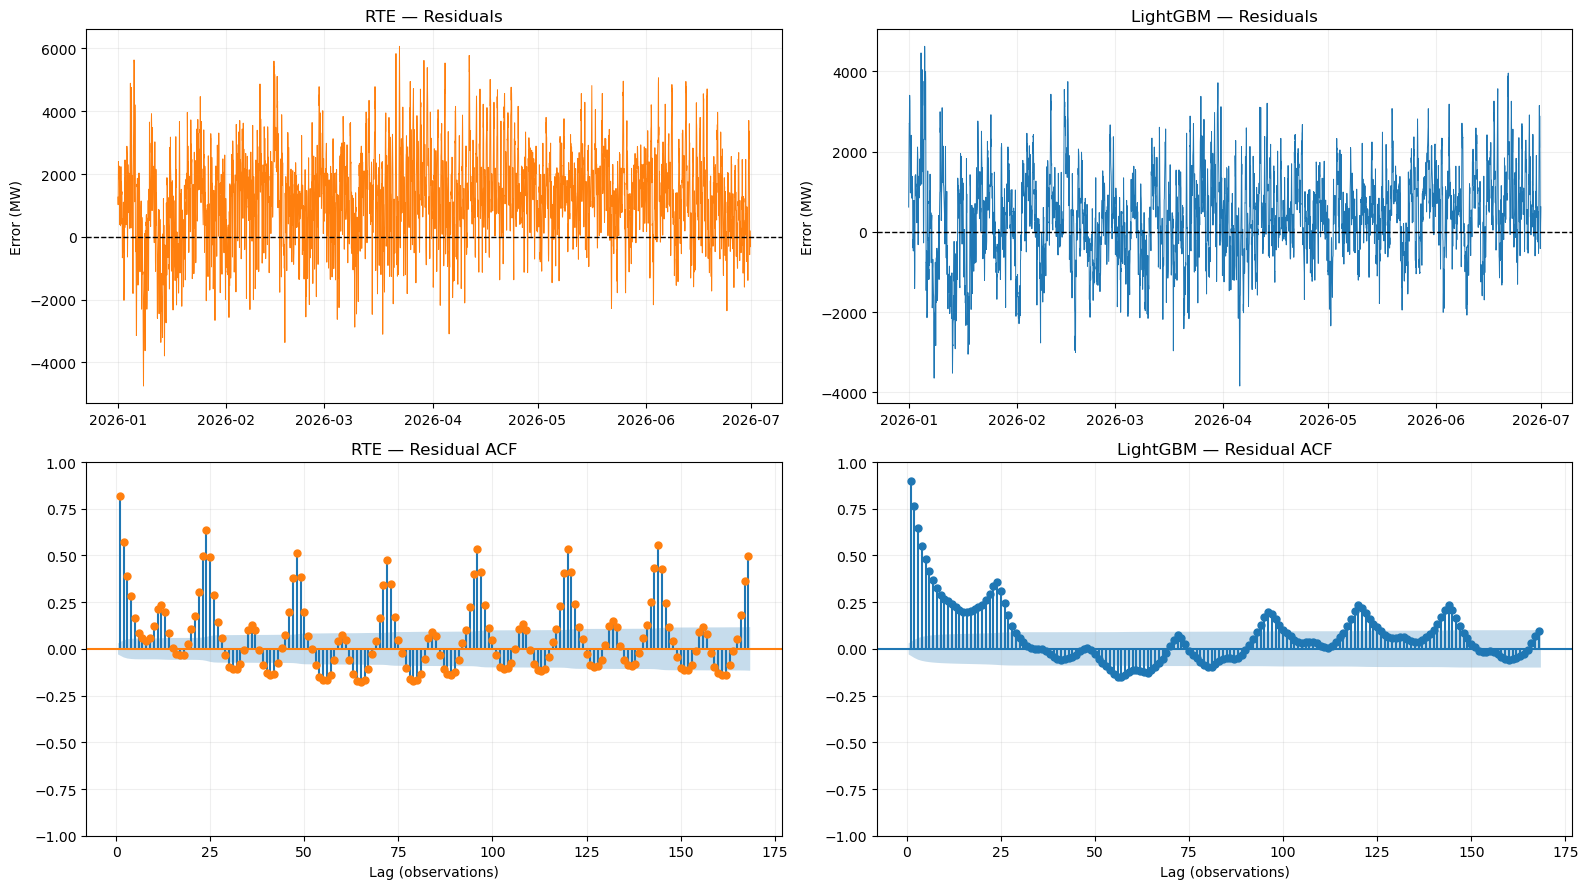

In [83]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# Residuals on common test timestamps
residuals = pd.DataFrame({
    "RTE": test_eval["actual"] - test_eval["RTE"],
    "LightGBM": test_eval["actual"] - test_eval["LightGBM"]
}).dropna()

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
colors = {"RTE": "tab:orange", "LightGBM": "tab:blue"}

for j, name in enumerate(["RTE", "LightGBM"]):
    axes[0, j].plot(residuals.index, residuals[name], color=colors[name], lw=0.7)
    axes[0, j].axhline(0, color="black", ls="--", lw=1)
    axes[0, j].set(title=f"{name} — Residuals", ylabel="Error (MW)")
    axes[0, j].grid(alpha=0.2)

    plot_acf(residuals[name], lags=168, ax=axes[1, j], zero=False, color=colors[name])
    axes[1, j].set(title=f"{name} — Residual ACF", xlabel="Lag (observations)")
    axes[1, j].grid(alpha=0.2)

plt.tight_layout()
plt.show()

LightGBM substantially reduces the magnitude of RTE forecasting errors, with residuals more closely centered around zero.

However, both models exhibit significant temporal dependence. RTE residuals display strong daily periodicity (lags 24, 48, 72…), while LightGBM residuals show particularly high short-term autocorrelation and persistent seasonal patterns.

Conclusion: LightGBM improves forecasting accuracy but does not eliminate residual autocorrelation. Its remaining errors contain temporal structure that the model has not fully captured, suggesting potential opportunities for further improvement.

#### **5.2.2 — Ljung–Box Test**

We apply the Ljung–Box test at lags 24, 48, and 168 to examine whether forecast residuals exhibit significant serial correlation.

- **H₀:** residuals are uncorrelated up to the specified lag.
- **H₁:** significant autocorrelation remains.

A p-value below 0.05 leads to rejection of the null hypothesis, indicating that the residuals cannot be considered white noise in the autocorrelation sense.

In [84]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_results = pd.concat({
    name: acorr_ljungbox(residuals[name], lags=[24, 48, 168], return_df=True)
    for name in residuals.columns
}, names=["Model", "Lag"])

lb_results["Conclusion"] = np.where(
    lb_results["lb_pvalue"] < 0.05,
    "Reject H0",
    "Do not reject H0"
)

display(lb_results.round(4))

lb_stat  lb_pvalue Conclusion
Model    Lag                                  
RTE      24    9705.4039        0.0  Reject H0
         48   13826.3812        0.0  Reject H0
         168  32945.1445        0.0  Reject H0
LightGBM 24   16538.3607        0.0  Reject H0
         48   17565.3707        0.0  Reject H0
         168  22628.4881        0.0  Reject H0

The Ljung–Box test rejects the null hypothesis of no autocorrelation for both RTE and LightGBM residuals at all tested lags (24, 48, and 168), with **p-values below 0.001**.

These results confirm the temporal dependencies observed in the ACF plots. Although LightGBM substantially improves forecasting accuracy, some predictable temporal structure remains in its residuals.

**Conclusion:** The correction model successfully reduces forecast errors, while residual autocorrelation highlights opportunities for further refinement, particularly in modeling short-term dependencies.

#### **5.2.3 — Comparing Residual Autocorrelation Structures**

Following the Ljung–Box tests, we directly compare the ACFs of RTE and LightGBM residuals to investigate how the correction model modifies the temporal dependencies inherited from the original forecasts.

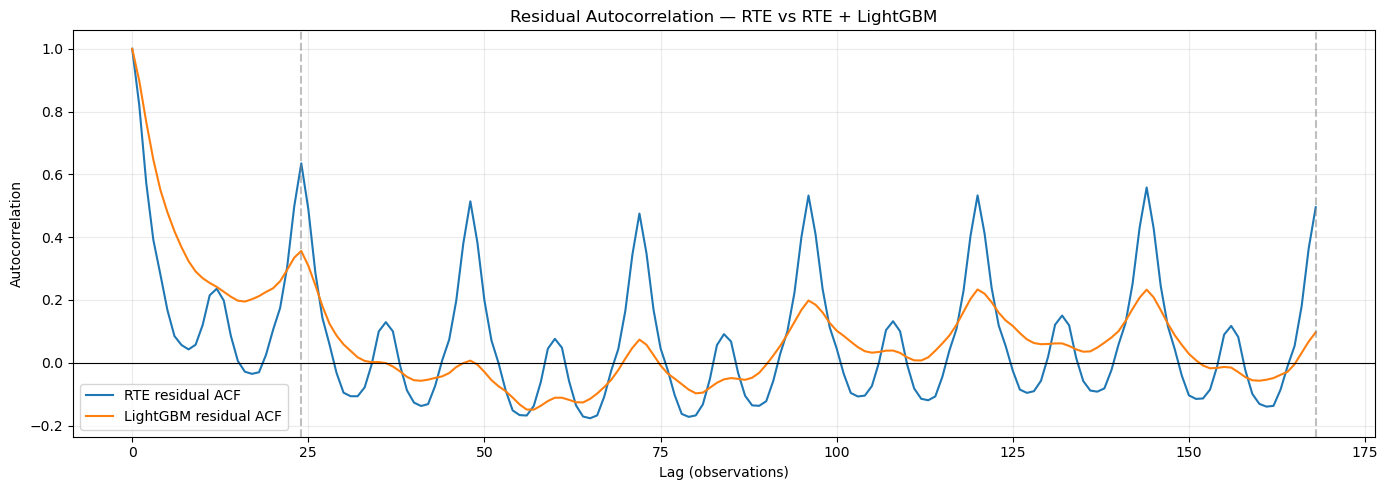

In [85]:
from statsmodels.tsa.stattools import acf
import matplotlib.pyplot as plt

# Compare residual autocorrelation on the same 2026 test observations
lags = 168
fig, ax = plt.subplots(figsize=(14, 5))

for name, color in [("RTE", "tab:blue"), ("LightGBM", "tab:orange")]:
    ax.plot(range(lags + 1), acf(residuals[name], nlags=lags, fft=True),
            color=color, label=f"{name} residual ACF")

for lag in [24, 168]:
    ax.axvline(lag, color="gray", linestyle="--", alpha=0.5)

ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Residual Autocorrelation — RTE vs RTE + LightGBM",
       xlabel="Lag (observations)", ylabel="Autocorrelation")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

RTE residuals exhibit pronounced daily periodicity, with strong autocorrelation peaks at approximately 24-hour intervals.

LightGBM substantially reduces these daily peaks, suggesting that the correction model captures part of RTE's systematic forecasting errors. However, stronger short-term autocorrelation remains in the corrected residuals.

Potential improvement: These remaining temporal dependencies suggest exploring an additional autoregressive or moving-average (ARMA) model applied to LightGBM residuals. Such a model could capture short-term error patterns not fully learned by LightGBM, potentially improving forecasting accuracy.

Any additional correction would need to use only residuals available before the forecast origin to avoid data leakage.

### **5.3 — Forecast Failure & Reliability Analysis**

We assess the reliability of RTE and LightGBM forecasts on the **2026 held-out test set** using two complementary failure criteria:

- **Interval failure:** actual electricity demand falls outside the 95% conformal prediction interval.
- **Point failure:** absolute percentage error (APE) exceeds a fixed threshold of 5%.

We compare when each model fails, how frequently these events occur, and whether LightGBM reduces large forecasting errors relative to RTE.

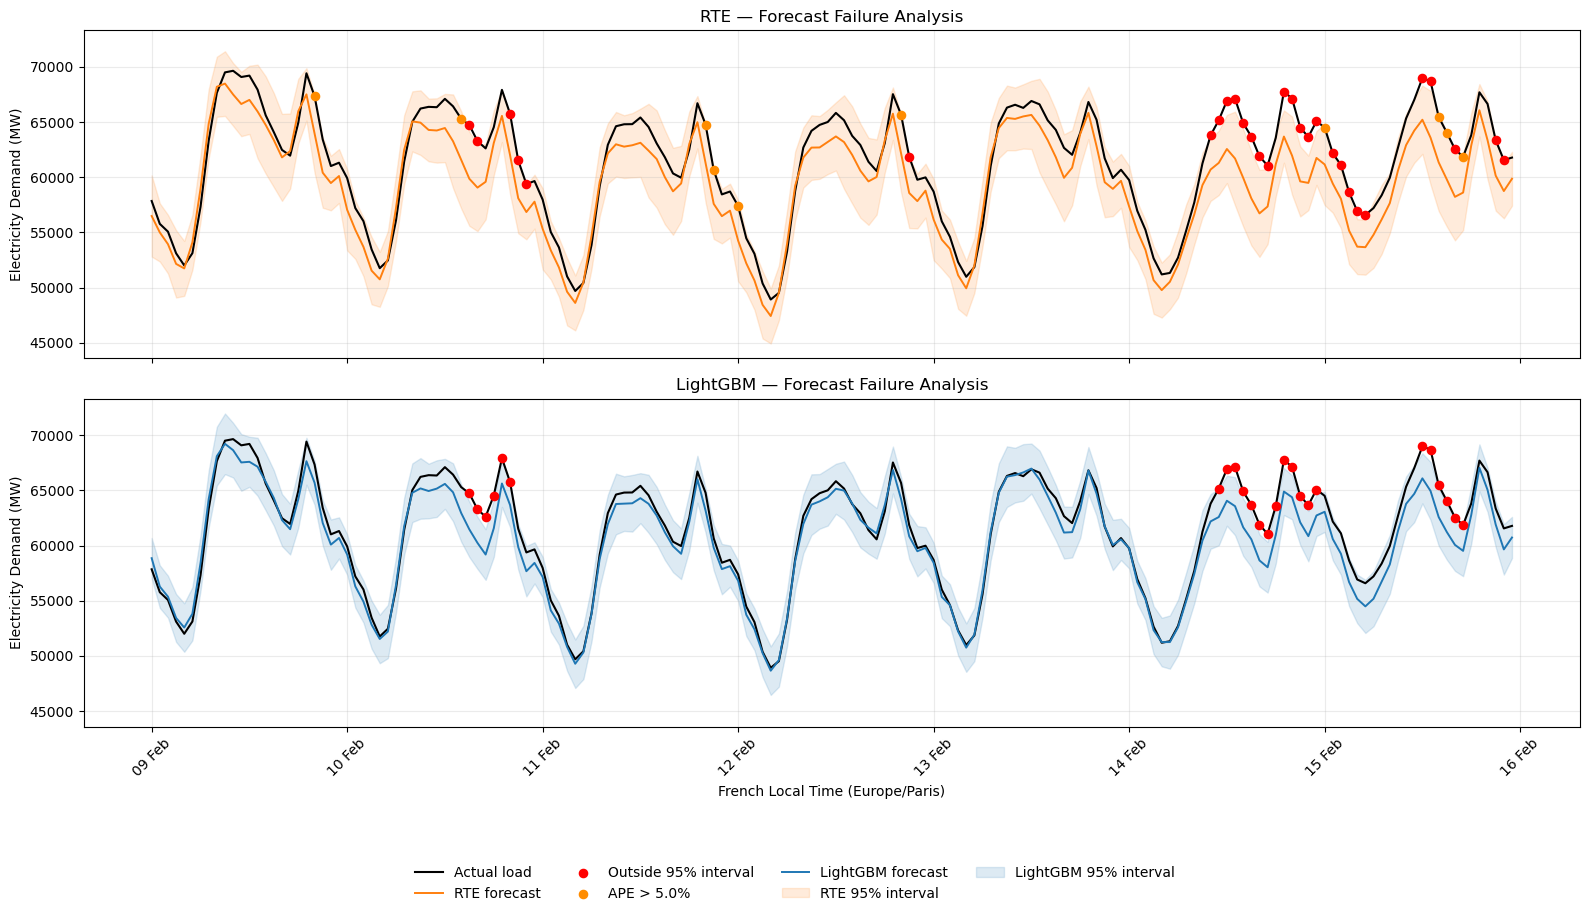

In [95]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

START, END = "2026-02-09", "2026-02-16"
APE_THRESHOLD = 5.0

# Compute failures for both models on the test set
failures = {}

for name in ["RTE", "LightGBM"]:
    d = test_eval[["actual", name, f"{name}_lower", f"{name}_upper"]].copy()
    d["APE (%)"] = 100 * (d["actual"] - d[name]).abs() / d["actual"].abs()
    d["interval_failure"] = (d["actual"] < d[f"{name}_lower"]) | (d["actual"] > d[f"{name}_upper"])
    d["point_failure"] = d["APE (%)"] > APE_THRESHOLD
    failures[name] = d

# Select French local visualization period
start, end = [pd.Timestamp(t, tz="Europe/Paris") for t in (START, END)]
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True, sharey=True)

for ax, (name, color) in zip(axes, [("RTE", "tab:orange"), ("LightGBM", "tab:blue")]):
    p = failures[name].copy()
    p.index = p.index.tz_convert("Europe/Paris")
    p = p[(p.index >= start) & (p.index < end)]

    ax.plot(p.index, p["actual"], "k-", lw=1.5, label="Actual load")
    ax.plot(p.index, p[name], color=color, lw=1.4, label=f"{name} forecast")
    ax.fill_between(
        p.index, p[f"{name}_lower"], p[f"{name}_upper"],
        color=color, alpha=0.15, label="95% prediction interval"
    )

    for mask, c, label in [
        (p["interval_failure"], "red", "Outside 95% interval"),
        (p["point_failure"] & ~p["interval_failure"], "darkorange", f"APE > {APE_THRESHOLD}%")
    ]:
        ax.scatter(p.index[mask], p.loc[mask, "actual"], color=c, s=35, zorder=5, label=label)

    ax.set(
        title=f"{name} — Forecast Failure Analysis",
        ylabel="Electricity Demand (MW)"
    )
    ax.grid(alpha=0.25)

axes[1].xaxis.set_major_locator(mdates.DayLocator(tz=start.tz))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=start.tz))
axes[1].set_xlabel("French Local Time (Europe/Paris)")

# Shared legend including both models
handles, labels = [], []

for ax in axes:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

# Remove duplicated labels while preserving model-specific entries
unique = dict(zip(labels, handles))

# Distinguish the two prediction intervals
unique["RTE 95% interval"] = axes[0].collections[0]
unique["LightGBM 95% interval"] = axes[1].collections[0]
unique.pop("95% prediction interval", None)

fig.legend(
    unique.values(), unique.keys(),
    loc="lower center", ncol=4,
    bbox_to_anchor=(0.5, -0.02),
    frameon=False
)

plt.xticks(rotation=45)
plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

The visual comparison reveals an interesting asymmetry in forecasting failures.

Most LightGBM interval failures appear to coincide with periods where RTE also struggles. However, **RTE exhibits additional failure periods that LightGBM successfully avoids**.

This suggests that the correction model effectively reduces many of RTE's forecasting errors, while some particularly challenging consumption patterns remain difficult for both models.

**Key insight:** LightGBM does not simply reproduce RTE's errors; it corrects a substantial portion of them, although certain difficult forecasting periods remain shared.

#### **5.3.2 — Long-Term Forecast Failure Analysis**

We extend the failure analysis to the **entire 2026 test period (January–June)** to assess the frequency and magnitude of large forecasting errors.

For both RTE and LightGBM, the Absolute Percentage Error (APE) is normalized by our predefined **5% failure threshold**:

$$
NormalizedError_t=\frac{APE_t}{5}
$$

Values above 1 indicate that the forecast error exceeds our tolerance threshold.

This comparison helps determine whether LightGBM consistently reduces forecasting errors over time rather than only during selected weeks.

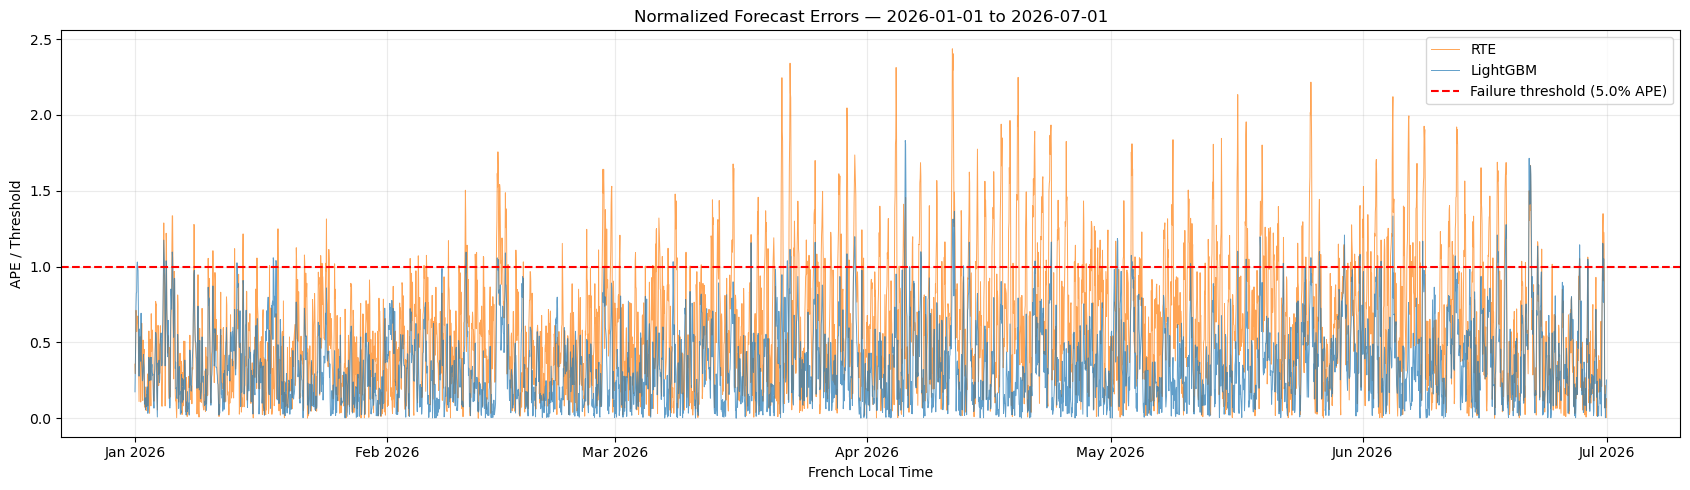

,Evaluated Hours,MAPE (%),Coverage 95% (%),Interval Failure Rate (%),Point Failure Rate — APE > 5% (%)
RTE,4343.0,2.99,93.51,6.49,16.33
LightGBM,4343.0,1.77,95.12,4.88,2.21


In [97]:
# Long-term failure analysis — Same period for plots and metrics
START, END = "2026-01-01", "2026-07-01"
start, end = [pd.Timestamp(d, tz="Europe/Paris") for d in (START, END)]

period_failures = {}
fig, ax = plt.subplots(figsize=(17, 5))

for name, color in [("RTE", "tab:orange"), ("LightGBM", "tab:blue")]:
    d = failures[name].copy()
    d = d[(d.index.tz_convert("Europe/Paris") >= start) &
          (d.index.tz_convert("Europe/Paris") < end)]
    period_failures[name] = d

    ax.plot(d.index.tz_convert("Europe/Paris"), d["APE (%)"] / APE_THRESHOLD,
            color=color, lw=0.7, alpha=0.7, label=name)

ax.axhline(1, color="red", ls="--", label=f"Failure threshold ({APE_THRESHOLD}% APE)")
ax.set(title=f"Normalized Forecast Errors — {START} to {END}",
       xlabel="French Local Time", ylabel="APE / Threshold")
ax.xaxis.set_major_locator(mdates.MonthLocator(tz="Europe/Paris"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y", tz="Europe/Paris"))
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Metrics calculated on exactly the displayed period
failure_rates = pd.DataFrame({
    name: {
        "Evaluated Hours": len(d),
        "MAPE (%)": d["APE (%)"].mean(),
        "Coverage 95% (%)": 100 * (1 - d["interval_failure"].mean()),
        "Interval Failure Rate (%)": 100 * d["interval_failure"].mean(),
        "Point Failure Rate — APE > 5% (%)": 100 * d["point_failure"].mean()
    }
    for name, d in period_failures.items()
}).T.round(2)

display(failure_rates)

The results confirm that **RTE + LightGBM consistently outperforms the original RTE forecast** over the entire six-month held-out test period (January–June 2026), covering **4,343 hourly observations**.

- **Forecast accuracy:** MAPE decreases from 2.99% to 1.77%, representing a **40.8% relative reduction in error**.
- **Prediction interval reliability:** empirical coverage improves from 93.51% to **95.12%**, closer to the nominal 95% target.
- **Large forecasting errors:** the proportion of predictions exceeding 5% APE drops dramatically from **16.33% to just 2.21%**.

**Conclusion:** These results reinforce our earlier validation findings and demonstrate that the improvements extend to previously unseen 2026 data. LightGBM not only improves average forecasting accuracy but also substantially reduces large prediction errors and provides better-calibrated uncertainty intervals.

While this supports **out-of-sample generalization over the evaluated six months**, performance beyond this period remains to be established.

### **5.4 — Final Statistical Comparison**

We summarize the forecasting accuracy and reliability of both models on the same **4,343 observations from the 2026 held-out test set**.

Absolute improvements are expressed in percentage points, while relative improvements are calculated with respect to the original RTE benchmark.

Positive improvement values indicate better performance for LightGBM, accounting for whether a metric should be minimized or maximized.

In [99]:
# Final comparison — RTE vs. LightGBM
summary = pd.DataFrame({
    name: {
        "Evaluated Hours": len(d),
        "MAPE (%)": d["APE (%)"].mean(),
        "Coverage 95% (%)": 100 * (1 - d["interval_failure"].mean()),
        "Avg Interval Width (MW)": (d[f"{name}_upper"] - d[f"{name}_lower"]).mean(),
        "Interval Failure Rate (%)": 100 * d["interval_failure"].mean(),
        "Point Failure Rate — APE > 5% (%)": 100 * d["point_failure"].mean()
    }
    for name, d in period_failures.items()
}).T

# Positive values indicate improvements over RTE
direction = pd.Series({
    "MAPE (%)": -1,
    "Coverage 95% (%)": 1,
    "Avg Interval Width (MW)": -1,
    "Interval Failure Rate (%)": -1,
    "Point Failure Rate — APE > 5% (%)": -1
})

final_comparison = summary.copy()

final_comparison.loc["Absolute Improvement"] = (
    (summary.loc["LightGBM"] - summary.loc["RTE"]) * direction
)

final_comparison.loc["Relative Improvement (%)"] = (
    (summary.loc["LightGBM"] - summary.loc["RTE"])
    / summary.loc["RTE"] * 100 * direction
)

final_comparison.loc[
    ["Absolute Improvement", "Relative Improvement (%)"], "Evaluated Hours"
] = np.nan

display(final_comparison.round(2))

,Evaluated Hours,MAPE (%),Coverage 95% (%),Avg Interval Width (MW),Interval Failure Rate (%),Point Failure Rate — APE > 5% (%)
RTE,4343.0,2.99,93.51,6232.96,6.49,16.33
LightGBM,4343.0,1.77,95.12,4624.74,4.88,2.21
Absolute Improvement,NaN,1.22,1.61,1608.22,1.61,14.11
Relative Improvement (%),NaN,40.75,1.72,25.80,24.82,86.46


### **5.5 — Final Conclusions**

On the **2026 held-out test set (4,343 hourly observations)**, the optimized RTE + LightGBM model outperforms the original RTE forecast across all evaluated metrics:

- **Forecast Accuracy (MAPE):** **40.75%** relative **reduction** in forecasting **error**, from 2.99% to 1.77%.
- **Prediction Interval Coverage:** improves by 1.61 percentage points, reaching **95.12%**, closer to the nominal 95% target.
- **Interval Failure Rate:** 24.82% relative reduction in observations falling outside the 95% prediction intervals.
- **Point Failure Rate (APE > 5%):** **86.46%** relative **reduction** in large **forecasting errors**, from 16.33% to just 2.21%.
- **Residual Diagnostics:** significant autocorrelation remains in both models, indicating opportunities for further improvement despite LightGBM's superior forecasting accuracy.


**Overall, RTE + LightGBM outperforms the original RTE forecast**, achieving a **40.75% reduction in MAPE** while producing **25.80% narrower prediction intervals** with improved empirical coverage (95.12% vs. 93.51%). Furthermore, it reduces the **interval failure rate by 24.82%** and the **point failure rate (APE > 5%) by 86.46%**, demonstrating substantial improvements in both forecasting accuracy and reliability on the held-out test set.

# **6. Deep Learning — Multi-Resolution Transformer**

We investigate a custom Multi-Resolution Time Series Transformer (MTST) developed in a previous project.

The architecture uses three parallel Transformer encoders operating at different temporal resolutions. Their learned representations are fused to produce the final forecast.

Unlike the original implementation, which relied on historical sequences, we adapt the MTST to our operational **day-ahead forecasting framework**.

Each day at 11:00 Europe/Paris, the model predicts the 24 hourly electricity demand residuals for D+1, using the same available features as our LightGBM model.

The predicted residuals are then added to the RTE day-ahead forecasts to reconstruct electricity demand.

## **6.1 — Data Preparation and Normalization**

We reuse the same RTE + Calendar dataset and chronological train/validation/test splits as LightGBM:

- **Training:** 2019–2024 (2,190 days).
- **Validation:** 2025 (365 days).
- **Testing:** January–June 2026 (181 days).

The input contains eight features, including RTE forecasts, lagged RTE forecast errors, weather-derived indicators and calendar variables.

Since neural networks are sensitive to feature scales, inputs and target residuals are standardized using `StandardScaler`, fitted exclusively on the training set.

## **6.2 — Daily Sequence Engineering**

Unlike LightGBM, which processes each hour independently, the MTST processes an entire forecast day simultaneously.

Each daily training sample contains:

- **Input:** `(24, 8)` — 24 hourly observations with eight features.
- **Target:** `(24,)` — 24 standardized RTE forecast residuals.
- **Validity mask:** `(24,)` — identifies valid hourly slots during daylight saving transitions.

Multiple daily sequences are combined into mini-batches using a PyTorch `DataLoader`.

This preprocessing preserves our operational 11:00 forecasting cutoff and the UTC-based timestamp convention.

## **6.3 — Multi-Resolution Architecture**

We retain the original MTST backbone and adapt its input and output interfaces.

Three parallel Transformer branches process the same daily input at different sampling resolutions:

| Branch | Sampling step | Tokens |
|---|---|---|
| High resolution | 1 hour | 24 |
| Medium resolution | 2 hours | 12 |
| Low resolution | 4 hours | 6 |

Each branch learns temporal dependencies through self-attention. The resulting representations are fused and passed through a regression head.

The model directly predicts all 24 hourly residuals, without recursive forecasting.

## **6.4 — Training and Initial Results**

The model is trained using Adam and a masked Mean Squared Error loss, ensuring that invalid daylight saving time slots do not contribute to optimization.

Training is performed on the Apple GPU through PyTorch MPS.

Our initial configuration produced the following results on the 2025 validation set:

| Metric | RTE | MTST |
|---|---:|---:|
| MAE (MW) | 1,396.65 | **902.45** |
| RMSE (MW) | 1,725.79 | **1,175.75** |
| MAPE (%) | 2.815 | **1.791** |
| R² | 0.974 | **0.988** |

The MTST reduces MAE by approximately **35.4%** compared with the original RTE forecast.

These initial results demonstrate that the Transformer can learn useful corrections to the RTE day-ahead forecast.

## **6.5 — Hyperparameter Optimization**

We use Optuna to optimize the MTST configuration, rather than performing an exhaustive grid search.

The search explores embedding dimensions, attention heads, Transformer layers, dropout, learning rate and batch size.

Fifteen trials are evaluated using a chronological validation subset of the training period, minimizing MAE in MW.

The best trial achieves:

**Validation MAE: 787.41 MW**

| Hyperparameter | Selected value |
|---|---:|
| Embedding dimension | 128 |
| Attention heads | 8 |
| Transformer layers | 2 |
| Dropout | 0.289 |
| Learning rate | 0.0001645 |
| Batch size | 16 |

The search required approximately **2.65 minutes**.

The selected architecture is subsequently retrained on the complete 2019–2024 training dataset.

## **6.6 — Prediction Intervals and Residual Diagnostics**

To quantify forecast uncertainty, we construct 95% conformal prediction intervals using absolute calibration errors from 2025.

Calibration is performed separately for each French local clock hour to account for intraday variations in forecasting uncertainty.

We evaluate:

- Empirical coverage and interval width.
- Interval failure rate.
- Point failure rate (APE greater than 5%).
- Residual autocorrelation and stationarity.

The ADF and KPSS tests on the initial validation residuals provide evidence consistent with stationarity, without requiring first-order differencing.

Ljung–Box diagnostics are used separately to assess remaining residual autocorrelation.

## **6.7 — Final Evaluation: January–June 2026**

The optimized Transformer is evaluated on the untouched 2026 test period, using the same forecasting horizon and evaluation metrics as RTE.

We compare MAE, RMSE, MAPE, R², prediction interval coverage, interval width and failure rates.

This final evaluation determines whether the MTST provides a robust improvement over the operational RTE forecast on unseen data.

**Final results and interpretation:** *To be completed after the optimized model finishes training and testing.*

In [42]:
import torch
from sklearn.preprocessing import StandardScaler

# GPU
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

# Dataset et features identiques à LightGBM
df = rte_datasets["rte_calendar"]
FEATURES = rte_feature_cols["rte_calendar"]
TARGET = "residual_target"

# Splits temporels identiques
fr_year = df.index.tz_convert("Europe/Paris").year

train_df = df[(fr_year >= 2019) & (fr_year <= 2024)].copy()
val_df   = df[fr_year == 2025].copy()
test_df  = df[fr_year == 2026].copy()

# Scalers entraînés uniquement sur le train
scaler_X = StandardScaler()
scaler_y = StandardScaler()

scaler_X.fit(train_df[FEATURES])
scaler_y.fit(train_df[[TARGET]])

# Transformation sans modifier les datasets originaux
transformer_datasets = {}

for name, split in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:
    scaled = split.copy()

    scaled[FEATURES] = scaler_X.transform(split[FEATURES])
    scaled[TARGET] = scaler_y.transform(split[[TARGET]]).ravel()

    transformer_datasets[name] = scaled

# Vérification
print("Device:", device)
print("Features:", FEATURES)

for name, data in transformer_datasets.items():
    print(f"{name}: {data.shape}")

Device: mps
Features: ['target_hour', 'target_day_of_week', 'target_month', 'rte_forecast_d1_mw_disp', 'rte_error_lag_48h', 'HDD_48h', 'CDD_48h', 'calendar_amplify_ewa']
train: (52607, 10)
val: (8760, 10)
test: (4343, 10)


In [50]:
import numpy as np
from torch.utils.data import Dataset, DataLoader

class TransformerDataset(Dataset):
    def __init__(self, df, features, target="residual_target"):
        self.samples = []

        local_index = df.index.tz_convert("Europe/Paris")
        local_dates = local_index.date

        for day in np.unique(local_dates):
            group = df.loc[local_dates == day]
            hours = group.index.tz_convert("Europe/Paris").hour

            X = np.zeros((24, len(features)), dtype=np.float32)
            y = np.zeros(24, dtype=np.float32)
            mask = np.zeros(24, dtype=np.float32)

            # Automne : conserver la deuxième occurrence de 02h
            duplicates = pd.Index(hours).duplicated(keep="last")

            for (_, row), hour, duplicate in zip(group.iterrows(), hours, duplicates):
                if duplicate:
                    continue

                values = row[features].to_numpy(dtype=np.float32)
                target_value = float(row[target])

                if np.isfinite(values).all() and np.isfinite(target_value):
                    X[hour] = values
                    y[hour] = target_value
                    mask[hour] = 1.0

            if mask.sum() > 0:
                self.samples.append((
                    torch.from_numpy(X),
                    torch.from_numpy(y),
                    torch.from_numpy(mask)
                ))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]


train_ds = TransformerDataset(transformer_datasets["train"], FEATURES)
val_ds = TransformerDataset(transformer_datasets["val"], FEATURES)
test_ds = TransformerDataset(transformer_datasets["test"], FEATURES)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=8, shuffle=False)

X, y, mask = next(iter(train_loader))

print("Train days:", len(train_ds))
print("Validation days:", len(val_ds))
print("Test days:", len(test_ds))
print("X:", X.shape)
print("y:", y.shape)
print("Mask:", mask.shape)

Train days: 2190
Validation days: 365
Test days: 181
X: torch.Size([8, 24, 8])
y: torch.Size([8, 24])
Mask: torch.Size([8, 24])


In [51]:

from MTST.Models.forecasting_model import MTSTDayAhead

transformer_model = MTSTDayAhead(input_dim=8).to(device)

print(type(transformer_model))
print(next(transformer_model.parameters()).device)

<class 'MTST.Models.forecasting_model.MTSTDayAhead'>
mps:0


In [52]:
import time

def sync():
    if device.type == "mps":
        torch.mps.synchronize()

def trace_start(name):
    def hook(module, inputs):
        sync()
        module._start_time = time.perf_counter()
        print(f"[START] {name}", flush=True)
    return hook

def trace_end(name):
    def hook(module, inputs, output):
        sync()
        elapsed = time.perf_counter() - module._start_time
        print(f"[END] {name}: {elapsed:.3f}s", flush=True)
    return hook

handles = []

for name, module in transformer_model.named_modules():
    if name in [
        "backbone.value_encoder",
        "backbone.transformer_high_res",
        "backbone.transformer_mid_res",
        "backbone.transformer_low_res",
        "backbone.fusion",
        "residual_head",
    ]:
        handles.append(module.register_forward_pre_hook(trace_start(name)))
        handles.append(module.register_forward_hook(trace_end(name)))

transformer_model.eval()
X = X.to(device)

with torch.no_grad():
    pred = transformer_model(X)

sync()
print("Forward terminé :", pred.shape)

for handle in handles:
    handle.remove()

[START] backbone.value_encoder
[END] backbone.value_encoder: 0.055s
[START] backbone.transformer_high_res
[END] backbone.transformer_high_res: 0.082s
[START] backbone.value_encoder
[END] backbone.value_encoder: 0.003s
[START] backbone.transformer_mid_res
[END] backbone.transformer_mid_res: 0.025s
[START] backbone.value_encoder
[END] backbone.value_encoder: 0.002s
[START] backbone.transformer_low_res
[END] backbone.transformer_low_res: 0.046s
[START] residual_head
[END] residual_head: 0.002s
Forward terminé : torch.Size([8, 24])


In [55]:
import time
import torch
from torch.utils.data import DataLoader
from MTST.Models.forecasting_model import MTSTDayAhead

# Configuration
EPOCHS = 30
BATCH_SIZE = 8
LR = 5e-4

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Nouveau modèle : entraînement depuis zéro
transformer_model = MTSTDayAhead(
    input_dim=len(FEATURES),
    high_res=1,
    mid_res=2,
    low_res=4
).to(device)

optimizer = torch.optim.Adam(
    transformer_model.parameters(),
    lr=LR,
    weight_decay=1e-5
)

history = []
start_total = time.perf_counter()

for epoch in range(EPOCHS):
    transformer_model.train()
    total_loss = 0.0
    total_valid = 0.0
    start_epoch = time.perf_counter()

    for X, y, mask in train_loader:
        X = X.to(device)
        y = y.to(device)
        mask = mask.to(device)

        optimizer.zero_grad()

        pred = transformer_model(X)

        # MSE masquée
        squared_error = ((pred - y) ** 2 * mask).sum()
        loss = squared_error / mask.sum().clamp(min=1)

        loss.backward()
        optimizer.step()

        total_loss += squared_error.detach().item()
        total_valid += mask.sum().item()

    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    epoch_loss = total_loss / total_valid
    elapsed = time.perf_counter() - start_epoch

    history.append(epoch_loss)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train MSE: {epoch_loss:.5f} | "
        f"Time: {elapsed:.2f}s",
        flush=True
    )

print(f"\nTotal training time: {(time.perf_counter()-start_total)/60:.2f} min")

Epoch 01/30 | Train MSE: 0.77400 | Time: 13.36s
Epoch 02/30 | Train MSE: 0.77601 | Time: 12.48s
Epoch 03/30 | Train MSE: 0.77568 | Time: 12.08s
Epoch 04/30 | Train MSE: 0.78196 | Time: 12.95s
Epoch 05/30 | Train MSE: 0.76215 | Time: 12.92s
Epoch 06/30 | Train MSE: 0.77511 | Time: 12.44s
Epoch 07/30 | Train MSE: 0.76784 | Time: 15.54s
Epoch 08/30 | Train MSE: 0.77622 | Time: 12.67s
Epoch 09/30 | Train MSE: 0.78288 | Time: 13.15s
Epoch 10/30 | Train MSE: 0.80815 | Time: 12.53s
Epoch 11/30 | Train MSE: 0.77678 | Time: 11.32s
Epoch 12/30 | Train MSE: 0.78787 | Time: 11.22s
Epoch 13/30 | Train MSE: 0.79456 | Time: 11.43s
Epoch 14/30 | Train MSE: 0.78917 | Time: 11.28s
Epoch 15/30 | Train MSE: 0.82282 | Time: 12.53s
Epoch 16/30 | Train MSE: 0.80471 | Time: 11.37s
Epoch 17/30 | Train MSE: 0.77264 | Time: 11.83s
Epoch 18/30 | Train MSE: 0.81977 | Time: 11.28s
Epoch 19/30 | Train MSE: 0.83438 | Time: 11.33s
Epoch 20/30 | Train MSE: 0.83542 | Time: 12.76s
Epoch 21/30 | Train MSE: 0.79528 | Time:

,MAE (MW),RMSE (MW),MAPE (%),R²
RTE,1396.647,1725.789,2.815,0.974
MTST,902.450,1175.748,1.791,0.988


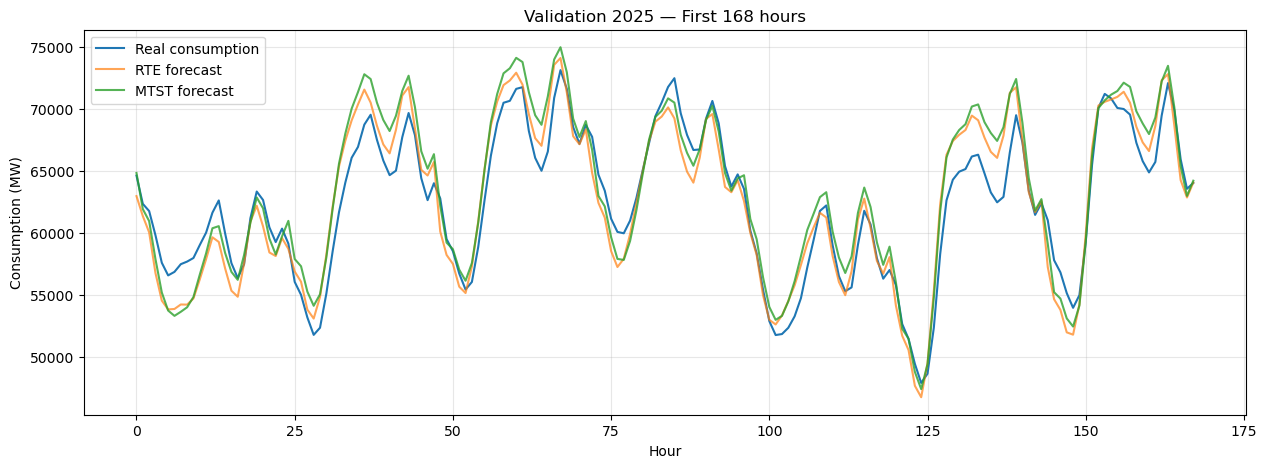

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Inférence sur la validation
transformer_model.eval()

pred_scaled = []
true_scaled = []
masks = []

with torch.inference_mode():
    for X, y, mask in val_loader:
        X = X.to(device)

        pred = transformer_model(X)

        pred_scaled.append(pred.cpu().numpy())
        true_scaled.append(y.numpy())
        masks.append(mask.numpy())

pred_scaled = np.concatenate(pred_scaled)
true_scaled = np.concatenate(true_scaled)
masks = np.concatenate(masks).astype(bool)

# 2. Inversion du scaling + exclusion des heures invalides
residual_pred = scaler_y.inverse_transform(
    pred_scaled.reshape(-1, 1)
).reshape(pred_scaled.shape)

residual_true = scaler_y.inverse_transform(
    true_scaled.reshape(-1, 1)
).reshape(true_scaled.shape)

residual_pred = residual_pred[masks]
residual_true = residual_true[masks]

# 3. Reconstruction des consommations en MW
# Même ordre chronologique que val_ds (shuffle=False)
val_real = val_df.copy()
local_dates = val_real.index.tz_convert("Europe/Paris").date
local_hours = val_real.index.tz_convert("Europe/Paris").hour

# Même convention DST que TransformerDataset
keep = ~pd.MultiIndex.from_arrays(
    [local_dates, local_hours]
).duplicated(keep="last")

val_real = val_real.loc[keep].copy()
val_real["local_date"] = val_real.index.tz_convert("Europe/Paris").date
val_real["local_hour"] = val_real.index.tz_convert("Europe/Paris").hour

val_real = val_real.sort_values(["local_date", "local_hour"])

# Vérification de l'alignement
assert len(val_real) == len(residual_pred), "Problème d'alignement DST"

rte_forecast = val_real["rte_forecast_d1_mw_disp"].to_numpy()
y_true = val_real["load_mw"].to_numpy()

y_pred = rte_forecast + residual_pred

# 4. Métriques
def metrics(y_true, y_pred):
    return {
        "MAE (MW)": mean_absolute_error(y_true, y_pred),
        "RMSE (MW)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": np.mean(
            np.abs((y_true - y_pred) / y_true)
        ) * 100,
        "R²": r2_score(y_true, y_pred)
    }

comparison = pd.DataFrame({
    "RTE": metrics(y_true, rte_forecast),
    "MTST": metrics(y_true, y_pred)
}).T

display(comparison.round(3))

# 5. Visualisation
plt.figure(figsize=(15, 5))

n = 168  # Première semaine

plt.plot(y_true[:n], label="Real consumption")
plt.plot(rte_forecast[:n], label="RTE forecast", alpha=0.7)
plt.plot(y_pred[:n], label="MTST forecast", alpha=0.8)

plt.title("Validation 2025 — First 168 hours")
plt.xlabel("Hour")
plt.ylabel("Consumption (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ALPHA = 0.05
APE_THRESHOLD = 5.0

# Reconstruire les prédictions indexées en UTC
mtst_val = pd.DataFrame({
    "actual": val_real["load_mw"].to_numpy(),
    "RTE": val_real["rte_forecast_d1_mw_disp"].to_numpy(),
    "MTST": np.asarray(y_pred)
}, index=val_real.index).sort_index()

assert mtst_val.index.is_unique
assert mtst_val.notna().all().all()

mtst_val["hour_fr"] = mtst_val.index.tz_convert("Europe/Paris").hour

# Split calibration / évaluation
local_time = mtst_val.index.tz_convert("Europe/Paris")

cal = mtst_val[local_time < pd.Timestamp(
    "2025-07-01", tz="Europe/Paris"
)].copy()

evaluation = mtst_val[local_time >= pd.Timestamp(
    "2025-07-01", tz="Europe/Paris"
)].copy()

# Quantile conforme, identique à la partie 5
def conformal_quantile(errors):
    e = np.sort(np.asarray(errors.dropna()))
    n = len(e)
    k = int(np.ceil((n + 1) * (1 - ALPHA)))
    return e[k - 1] if k <= n else np.inf

# Calibration indépendante par heure française
margins = {}

for name in ["RTE", "MTST"]:
    errors = (cal["actual"] - cal[name]).abs()

    margins[name] = errors.groupby(
        cal["hour_fr"]
    ).apply(conformal_quantile)

    margin = evaluation["hour_fr"].map(margins[name])

    evaluation[f"{name}_lower"] = evaluation[name] - margin
    evaluation[f"{name}_upper"] = evaluation[name] + margin

# Vérifications
assert np.isfinite(
    evaluation[["RTE_lower", "RTE_upper",
                "MTST_lower", "MTST_upper"]]
).all().all()

# Métriques
results = {}

for name in ["RTE", "MTST"]:
    actual = evaluation["actual"]
    pred = evaluation[name]

    ape = 100 * (actual - pred).abs() / actual.abs()
    interval_failure = (
        (actual < evaluation[f"{name}_lower"]) |
        (actual > evaluation[f"{name}_upper"])
    )

    results[name] = {
        "MAE (MW)": mean_absolute_error(actual, pred),
        "RMSE (MW)": np.sqrt(mean_squared_error(actual, pred)),
        "MAPE (%)": ape.mean(),
        "R²": r2_score(actual, pred),
        "Coverage 95% (%)": 100 * (1 - interval_failure.mean()),
        "Avg Interval Width (MW)": (
            evaluation[f"{name}_upper"] -
            evaluation[f"{name}_lower"]
        ).mean(),
        "Interval Failure Rate (%)": 100 * interval_failure.mean(),
        "Point Failure Rate — APE > 5% (%)": 100 * (ape > 5).mean()
    }

comparison = pd.DataFrame(results).T

display(comparison.round(3))

,MAE (MW),RMSE (MW),MAPE (%),R²,Coverage 95% (%),Avg Interval Width (MW),Interval Failure Rate (%),Point Failure Rate — APE > 5% (%)
RTE,1329.552,1671.729,2.731,0.969,95.947,6232.750,4.053,13.089
MTST,862.691,1124.783,1.769,0.986,96.966,4999.817,3.034,3.351


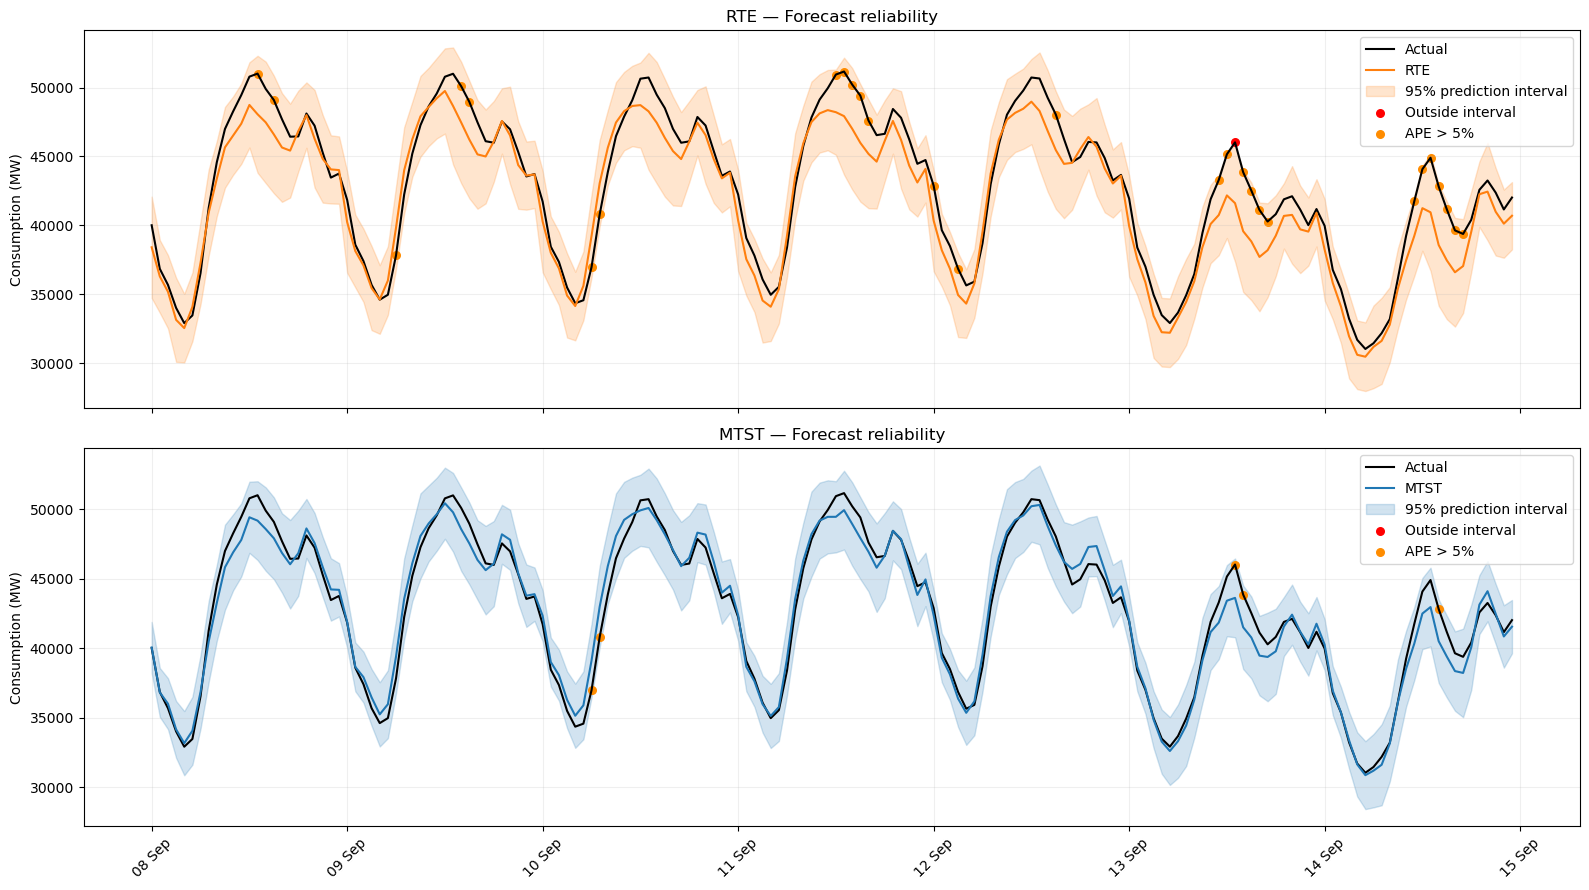

In [61]:
import matplotlib.dates as mdates

WEEK_START = "2025-09-08"

start = pd.Timestamp(WEEK_START, tz="Europe/Paris")
end = start + pd.DateOffset(days=7)

plot = evaluation.copy()
plot.index = plot.index.tz_convert("Europe/Paris")
plot = plot[(plot.index >= start) & (plot.index < end)]

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

for ax, (name, color) in zip(
    axes,
    [("RTE", "tab:orange"), ("MTST", "tab:blue")]
):
    outside = (
        (plot["actual"] < plot[f"{name}_lower"]) |
        (plot["actual"] > plot[f"{name}_upper"])
    )

    ape = 100 * (plot["actual"] - plot[name]).abs() / plot["actual"].abs()
    point_failure = (ape > APE_THRESHOLD) & ~outside

    ax.plot(plot.index, plot["actual"], "k-", label="Actual")
    ax.plot(plot.index, plot[name], color=color, label=name)

    ax.fill_between(
        plot.index,
        plot[f"{name}_lower"],
        plot[f"{name}_upper"],
        color=color,
        alpha=0.2,
        label="95% prediction interval"
    )

    ax.scatter(
        plot.index[outside],
        plot.loc[outside, "actual"],
        color="red", s=30,
        label="Outside interval"
    )

    ax.scatter(
        plot.index[point_failure],
        plot.loc[point_failure, "actual"],
        color="darkorange", s=30,
        label="APE > 5%"
    )

    ax.set_title(f"{name} — Forecast reliability")
    ax.set_ylabel("Consumption (MW)")
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b", tz=start.tz)
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

results = []

for model_name in ["RTE", "MTST"]:
    e = residuals[model_name].dropna()

    for series_name, series in [
        ("Original", e),
        ("Différence d=1", e.diff().dropna())
    ]:
        adf_p = adfuller(series, autolag="AIC")[1]
        kpss_p = kpss(series, regression="c", nlags="auto")[1]

        results.append({
            "Model": model_name,
            "Series": series_name,
            "ADF p-value": adf_p,
            "KPSS p-value": kpss_p
        })

display(pd.DataFrame(results).round(4))

/var/folders/j2/6n92hgzn6vv7rgs4fm_nk10w0000gn/T/ipykernel_29158/4237459953.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(series, regression="c", nlags="auto")[1]
/var/folders/j2/6n92hgzn6vv7rgs4fm_nk10w0000gn/T/ipykernel_29158/4237459953.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(series, regression="c", nlags="auto")[1]
/var/folders/j2/6n92hgzn6vv7rgs4fm_nk10w0000gn/T/ipykernel_29158/4237459953.py:14: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(series, regression="c", nlags="auto")[1]
/var/folders/j2/6n92hgzn6vv7rgs4fm_nk10w0000gn/T/ipykernel_29158/4237459953.py:

,Model,Series,ADF p-value,KPSS p-value
0,RTE,Original,0.0,0.1
1,RTE,Différence d=1,0.0,0.1
2,MTST,Original,0.0,0.1
3,MTST,Différence d=1,0.0,0.1


**Hyperparametrisation**

In [65]:
import optuna
import numpy as np
import torch
import time

from torch.utils.data import DataLoader, Subset
from MTST.Models.forecasting_model import MTSTDayAhead

N_TRIALS = 15
EPOCHS = 10
N_DAYS = 730

# Split chronologique interne au train
start_idx = len(train_ds) - N_DAYS
split_idx = start_idx + int(N_DAYS * 0.8)

tune_train = Subset(train_ds, range(start_idx, split_idx))
tune_val = Subset(train_ds, range(split_idx, len(train_ds)))

# Écart-type de la cible pour convertir la MAE en MW
target_std = float(scaler_y.scale_[0])

def objective(trial):

    params = {
        "embed_dim": trial.suggest_categorical("embed_dim", [32, 64, 128]),
        "heads": trial.suggest_categorical("heads", [4, 8, 16]),
        "n_layers": trial.suggest_int("n_layers", 1, 3),
        "dropout": trial.suggest_float("dropout", 0.1, 0.3),
        "lr": trial.suggest_float("lr", 1e-4, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [8, 16, 32])
    }

    model_trial = MTSTDayAhead(
        input_dim=len(FEATURES),
        embed_dim=params["embed_dim"],
        heads=params["heads"],
        n_layers=params["n_layers"],
        dropout=params["dropout"],
        high_res=1,
        mid_res=2,
        low_res=4
    ).to(device)

    train_loader_trial = DataLoader(
        tune_train,
        batch_size=params["batch_size"],
        shuffle=False
    )

    val_loader_trial = DataLoader(
        tune_val,
        batch_size=params["batch_size"],
        shuffle=False
    )

    optimizer = torch.optim.Adam(
        model_trial.parameters(),
        lr=params["lr"],
        weight_decay=1e-5
    )

    best_mae = float("inf")

    for epoch in range(EPOCHS):

        model_trial.train()

        for X, y, mask in train_loader_trial:
            X, y, mask = (
                X.to(device),
                y.to(device),
                mask.to(device)
            )

            optimizer.zero_grad()
            pred = model_trial(X)

            loss = (
                ((pred - y) ** 2 * mask).sum()
                / mask.sum().clamp(min=1)
            )

            loss.backward()
            optimizer.step()

        # Validation
        model_trial.eval()
        total_error = 0.0
        total_valid = 0.0

        with torch.inference_mode():
            for X, y, mask in val_loader_trial:
                X, y, mask = (
                    X.to(device),
                    y.to(device),
                    mask.to(device)
                )

                pred = model_trial(X)

                total_error += (
                    (pred - y).abs() * mask
                ).sum().item()

                total_valid += mask.sum().item()

        # MAE des résidus, convertie en MW
        mae_mw = (total_error / total_valid) * target_std

        best_mae = min(best_mae, mae_mw)

        trial.report(mae_mw, epoch)

        if trial.should_prune():
            raise optuna.TrialPruned()

    return best_mae


study = optuna.create_study(
    direction="minimize",
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=5,
        n_warmup_steps=3
    )
)

start = time.perf_counter()

study.optimize(objective, n_trials=N_TRIALS)

print("\nBest MAE:", round(study.best_value, 2), "MW")
print("Best parameters:", study.best_params)
print("Duration:", round((time.perf_counter() - start) / 60, 2), "min")

[I 2026-10-23 23:27:46,764] A new study created in memory with name: no-name-4dab1bbe-bf0a-4738-aa55-aeb5728c32bc
[I 2026-10-23 23:28:01,504] Trial 0 finished with value: 817.0374867463372 and parameters: {'embed_dim': 32, 'heads': 16, 'n_layers': 1, 'dropout': 0.1514178346134428, 'lr': 0.00020206416778316777, 'batch_size': 16}. Best is trial 0 with value: 817.0374867463372.
[I 2026-10-23 23:28:21,484] Trial 1 finished with value: 820.519463737868 and parameters: {'embed_dim': 128, 'heads': 4, 'n_layers': 2, 'dropout': 0.2181734230197633, 'lr': 0.0001844277627030276, 'batch_size': 16}. Best is trial 0 with value: 817.0374867463372.
[I 2026-10-23 23:28:45,130] Trial 2 finished with value: 833.5449937739791 and parameters: {'embed_dim': 32, 'heads': 4, 'n_layers': 3, 'dropout': 0.16820866538830256, 'lr': 0.0003550221316884587, 'batch_size': 16}. Best is trial 0 with value: 817.0374867463372.
[I 2026-10-23 23:29:02,369] Trial 3 finished with value: 787.4057832240543 and parameters: {'embe


Best MAE: 787.41 MW
Best parameters: {'embed_dim': 128, 'heads': 8, 'n_layers': 2, 'dropout': 0.28937300198872395, 'lr': 0.0001644783475193988, 'batch_size': 16}
Duration: 2.65 min


In [91]:
import optuna
import numpy as np
import torch
import time

from torch.utils.data import DataLoader, Subset
from MTST.Models.forecasting_model import MTSTDayAhead

# Configuration
N_TRIALS = 15
EPOCHS = 10
N_DAYS = 730

# Split chronologique interne au train
start_idx = len(train_ds) - N_DAYS
split_idx = start_idx + int(N_DAYS * 0.8)

tune_train = Subset(train_ds, range(start_idx, split_idx))
tune_val = Subset(train_ds, range(split_idx, len(train_ds)))

# Paramètres de normalisation
idx = FEATURES.index("rte_forecast_d1_mw_disp")

rte_mean = float(scaler_X.mean_[idx])
rte_std = float(scaler_X.scale_[idx])

target_mean = float(scaler_y.mean_[0])
target_std = float(scaler_y.scale_[0])


# MAPE sur la consommation reconstruite
def mape_loss(pred, y, X, mask):

    rte_mw = X[:, :, idx] * rte_std + rte_mean

    pred_load = rte_mw + pred * target_std + target_mean
    true_load = rte_mw + y * target_std + target_mean

    ape = (
        (pred_load - true_load).abs()
        / true_load.abs().clamp(min=1)
    )

    return (ape * mask).sum() / mask.sum().clamp(min=1)


def objective(trial):

    params = {
        "embed_dim": trial.suggest_categorical(
            "embed_dim", [32, 64, 128]
        ),
        "heads": trial.suggest_categorical(
            "heads", [4, 8, 16]
        ),
        "n_layers": trial.suggest_int(
            "n_layers", 1, 3
        ),
        "dropout": trial.suggest_float(
            "dropout", 0.1, 0.3
        ),
        "lr": trial.suggest_float(
            "lr", 1e-4, 1e-3, log=True
        ),
        "batch_size": trial.suggest_categorical(
            "batch_size", [8, 16, 32]
        )
    }

    model_trial = MTSTDayAhead(
        input_dim=len(FEATURES),
        embed_dim=params["embed_dim"],
        heads=params["heads"],
        n_layers=params["n_layers"],
        dropout=params["dropout"],
        high_res=1,
        mid_res=2,
        low_res=4
    ).to(device)

    train_loader_trial = DataLoader(
        tune_train,
        batch_size=params["batch_size"],
        shuffle=False
    )

    val_loader_trial = DataLoader(
        tune_val,
        batch_size=params["batch_size"],
        shuffle=False
    )

    optimizer = torch.optim.Adam(
        model_trial.parameters(),
        lr=params["lr"],
        weight_decay=1e-5
    )

    best_mape = float("inf")

    for epoch in range(EPOCHS):

        # Entraînement
        model_trial.train()

        for X, y, mask in train_loader_trial:
            X = X.to(device)
            y = y.to(device)
            mask = mask.to(device)

            optimizer.zero_grad()

            pred = model_trial(X)

            loss = mape_loss(pred, y, X, mask)

            loss.backward()
            optimizer.step()

        # Validation
        model_trial.eval()

        total_error = 0.0
        total_valid = 0.0

        with torch.inference_mode():
            for X, y, mask in val_loader_trial:
                X = X.to(device)
                y = y.to(device)
                mask = mask.to(device)

                pred = model_trial(X)

                batch_mape = mape_loss(pred, y, X, mask)

                valid_count = mask.sum().item()

                total_error += batch_mape.item() * valid_count
                total_valid += valid_count

        # MAPE en %
        mape = 100 * total_error / total_valid

        best_mape = min(best_mape, mape)

        trial.report(mape, epoch)

        if trial.should_prune():
            raise optuna.TrialPruned()

    return best_mape


# Recherche Optuna
study_mape = optuna.create_study(
    direction="minimize",
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=5,
        n_warmup_steps=3
    )
)

start = time.perf_counter()

study_mape.optimize(
    objective,
    n_trials=N_TRIALS
)

print("\nBest MAPE:", round(study_mape.best_value, 3), "%")
print("Best parameters:", study_mape.best_params)
print(
    "Duration:",
    round((time.perf_counter() - start) / 60, 2),
    "min"
)

[I 2026-10-24 01:05:38,873] A new study created in memory with name: no-name-5b731e9c-1367-475a-a3f2-29b8666885f8
[I 2026-10-24 01:07:40,646] Trial 0 finished with value: 1.5846374482937056 and parameters: {'embed_dim': 32, 'heads': 8, 'n_layers': 1, 'dropout': 0.10533247633399785, 'lr': 0.00033029370982848863, 'batch_size': 16}. Best is trial 0 with value: 1.5846374482937056.
[I 2026-10-24 01:08:02,264] Trial 1 finished with value: 1.5616598960063228 and parameters: {'embed_dim': 64, 'heads': 8, 'n_layers': 2, 'dropout': 0.15769646223637707, 'lr': 0.00042699108975524164, 'batch_size': 32}. Best is trial 1 with value: 1.5616598960063228.
[I 2026-10-24 01:08:37,541] Trial 2 finished with value: 1.576938620475057 and parameters: {'embed_dim': 64, 'heads': 8, 'n_layers': 2, 'dropout': 0.16425426083414174, 'lr': 0.0006321496184853058, 'batch_size': 16}. Best is trial 1 with value: 1.5616598960063228.
[I 2026-10-24 01:08:55,442] Trial 3 finished with value: 1.5727463599345455 and parameters


Best MAPE: 1.541 %
Best parameters: {'embed_dim': 128, 'heads': 16, 'n_layers': 1, 'dropout': 0.18492544174041475, 'lr': 0.000267637187171345, 'batch_size': 16}
Duration: 5.82 min


In [92]:
import time
import torch
import numpy as np
from torch.utils.data import DataLoader
from MTST.Models.forecasting_model import MTSTDayAhead

best = study_mape.best_params

EPOCHS = 50

torch.manual_seed(42)

transformer_model = MTSTDayAhead(
    input_dim=len(FEATURES),
    embed_dim=best["embed_dim"],
    heads=best["heads"],
    n_layers=best["n_layers"],
    dropout=best["dropout"],
    high_res=1,
    mid_res=2,
    low_res=4
).to(device)

optimizer = torch.optim.Adam(
    transformer_model.parameters(),
    lr=best["lr"],
    weight_decay=1e-5
)

train_loader = DataLoader(
    train_ds,
    batch_size=best["batch_size"],
    shuffle=False
)

train_losses = []
start = time.perf_counter()

for epoch in range(EPOCHS):
    transformer_model.train()

    total_error = 0.0
    total_valid = 0.0

    for X, y, mask in train_loader:
        X = X.to(device)
        y = y.to(device)
        mask = mask.to(device)

        optimizer.zero_grad()

        pred = transformer_model(X)

        # loss = (
        #     ((pred - y) ** 2 * mask).sum()
        #     / mask.sum().clamp(min=1)
        # )

        # Reconstruction des consommations en MW
        idx = FEATURES.index("rte_forecast_d1_mw_disp")

        rte_mw = X[:, :, idx] * scaler_X.scale_[idx] + scaler_X.mean_[idx]

        pred_residual = pred * scaler_y.scale_[0] + scaler_y.mean_[0]
        true_residual = y * scaler_y.scale_[0] + scaler_y.mean_[0]

        pred_load = rte_mw + pred_residual
        true_load = rte_mw + true_residual

        # Loss MAPE masquée
        loss = (
            (torch.abs(pred_load - true_load) / true_load.abs().clamp(min=1))
            * mask
        ).sum() / mask.sum().clamp(min=1)



        loss.backward()
        optimizer.step()

        total_error += (
            ((pred - y) ** 2 * mask).detach().sum().item()
        )
        total_valid += mask.sum().item()

    epoch_loss = total_error / total_valid
    train_losses.append(epoch_loss)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} "
        f"| MSE: {epoch_loss:.5f}",
        flush=True
    )

if device.type == "mps":
    torch.mps.synchronize()
elif device.type == "cuda":
    torch.cuda.synchronize()

print(f"\nTraining duration: {(time.perf_counter()-start)/60:.2f} min")

Epoch 01/50 | MSE: 0.80413
Epoch 02/50 | MSE: 0.77108
Epoch 03/50 | MSE: 0.77550
Epoch 04/50 | MSE: 0.77021
Epoch 05/50 | MSE: 0.77923
Epoch 06/50 | MSE: 0.77265
Epoch 07/50 | MSE: 0.77314
Epoch 08/50 | MSE: 0.76915
Epoch 09/50 | MSE: 0.75544
Epoch 10/50 | MSE: 0.75450
Epoch 11/50 | MSE: 0.74451
Epoch 12/50 | MSE: 0.73161
Epoch 13/50 | MSE: 0.74671
Epoch 14/50 | MSE: 0.73120
Epoch 15/50 | MSE: 0.73080
Epoch 16/50 | MSE: 0.73395
Epoch 17/50 | MSE: 0.73306
Epoch 18/50 | MSE: 0.72487
Epoch 19/50 | MSE: 0.72902
Epoch 20/50 | MSE: 0.72668
Epoch 21/50 | MSE: 0.72478
Epoch 22/50 | MSE: 0.72811
Epoch 23/50 | MSE: 0.72084
Epoch 24/50 | MSE: 0.72230
Epoch 25/50 | MSE: 0.72188
Epoch 26/50 | MSE: 0.71838
Epoch 27/50 | MSE: 0.71744
Epoch 28/50 | MSE: 0.71463
Epoch 29/50 | MSE: 0.71634
Epoch 30/50 | MSE: 0.71591
Epoch 31/50 | MSE: 0.71178
Epoch 32/50 | MSE: 0.71010
Epoch 33/50 | MSE: 0.71246
Epoch 34/50 | MSE: 0.71187
Epoch 35/50 | MSE: 0.71094
Epoch 36/50 | MSE: 0.70864
Epoch 37/50 | MSE: 0.70489
E

In [93]:
import pandas as pd

def predict_mtst(dataset, scaled_df, original_df):
    loader = DataLoader(
        dataset,
        batch_size=best["batch_size"],
        shuffle=False
    )

    transformer_model.eval()
    preds, masks = [], []

    with torch.inference_mode():
        for X, y, mask in loader:
            pred = transformer_model(X.to(device))
            preds.append(pred.cpu().numpy())
            masks.append(mask.numpy())

    preds = np.concatenate(preds)
    masks = np.concatenate(masks).astype(bool)

    # Reproduire exactement l'indexation du TransformerDataset
    local = scaled_df.index.tz_convert("Europe/Paris")
    dates = local.date
    timestamps = []

    for day in np.unique(dates):
        group = scaled_df.loc[dates == day]
        hours = group.index.tz_convert("Europe/Paris").hour
        duplicates = pd.Index(hours).duplicated(keep="last")

        slots = [None] * 24

        for (ts, row), hour, duplicate in zip(
            group.iterrows(), hours, duplicates
        ):
            if duplicate:
                continue

            values = row[FEATURES].to_numpy(dtype=np.float32)
            target = float(row[TARGET])

            if np.isfinite(values).all() and np.isfinite(target):
                slots[hour] = ts

        if any(ts is not None for ts in slots):
            timestamps.extend(slots)

    assert len(timestamps) == masks.size

    valid_timestamps = pd.DatetimeIndex([
        ts for ts, valid in zip(timestamps, masks.ravel())
        if valid
    ])

    assert valid_timestamps.is_unique
    assert len(valid_timestamps) == masks.sum()

    residual_pred = scaler_y.inverse_transform(
        preds.reshape(-1, 1)
    ).ravel()[masks.ravel()]

    result = original_df.loc[valid_timestamps, [
        "load_mw", "rte_forecast_d1_mw_disp"
    ]].copy()

    result["MTST"] = (
        result["rte_forecast_d1_mw_disp"].to_numpy()
        + residual_pred
    )

    return result.rename(columns={
        "load_mw": "actual",
        "rte_forecast_d1_mw_disp": "RTE"
    }).sort_index()


# Calibration 2025
cal = predict_mtst(
    val_ds, transformer_datasets["val"], val_df
)

# Évaluation 2026
evaluation = predict_mtst(
    test_ds, transformer_datasets["test"], test_df
)

start = pd.Timestamp("2026-01-01", tz="Europe/Paris")
end = pd.Timestamp("2026-07-01", tz="Europe/Paris")

local = evaluation.index.tz_convert("Europe/Paris")
evaluation = evaluation[(local >= start) & (local < end)].copy()

print("Calibration:", len(cal), "hours")
print("Test:", len(evaluation), "hours")

Calibration: 8759 hours
Test: 4343 hours


In [94]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ALPHA = 0.05
APE_THRESHOLD = 5.0

cal["hour_fr"] = cal.index.tz_convert("Europe/Paris").hour
evaluation["hour_fr"] = evaluation.index.tz_convert("Europe/Paris").hour

def conformal_quantile(errors):
    e = np.sort(np.asarray(errors.dropna()))
    n = len(e)
    k = int(np.ceil((n + 1) * (1 - ALPHA)))
    return e[k - 1] if k <= n else np.inf

results = {}
failures = {}

for name in ["RTE", "MTST"]:
    errors_cal = (cal["actual"] - cal[name]).abs()

    margins = errors_cal.groupby(
        cal["hour_fr"]
    ).apply(conformal_quantile)

    margin = evaluation["hour_fr"].map(margins)

    lower = evaluation[name] - margin
    upper = evaluation[name] + margin

    actual = evaluation["actual"]
    pred = evaluation[name]

    ape = 100 * (actual - pred).abs() / actual.abs()

    interval_failure = (actual < lower) | (actual > upper)
    point_failure = ape > APE_THRESHOLD

    failures[name] = pd.DataFrame({
        "APE (%)": ape,
        "interval_failure": interval_failure,
        "point_failure": point_failure
    }, index=evaluation.index)

    evaluation[f"{name}_lower"] = lower
    evaluation[f"{name}_upper"] = upper

    results[name] = {
        "MAE (MW)": mean_absolute_error(actual, pred),
        "RMSE (MW)": np.sqrt(mean_squared_error(actual, pred)),
        "MAPE (%)": ape.mean(),
        "R²": r2_score(actual, pred),
        "Coverage 95% (%)": 100 * (1 - interval_failure.mean()),
        "Avg Interval Width (MW)": (upper - lower).mean(),
        "Interval Failure Rate (%)": 100 * interval_failure.mean(),
        "Point Failure Rate — APE > 5% (%)": 100 * point_failure.mean()
    }

comparison = pd.DataFrame(results).T
display(comparison.round(3))

,MAE (MW),RMSE (MW),MAPE (%),R²,Coverage 95% (%),Avg Interval Width (MW),Interval Failure Rate (%),Point Failure Rate — APE > 5% (%)
RTE,1550.252,1888.761,2.990,0.968,93.921,6099.812,6.079,16.325
MTST,906.282,1162.574,1.735,0.988,94.543,4481.702,5.457,2.924


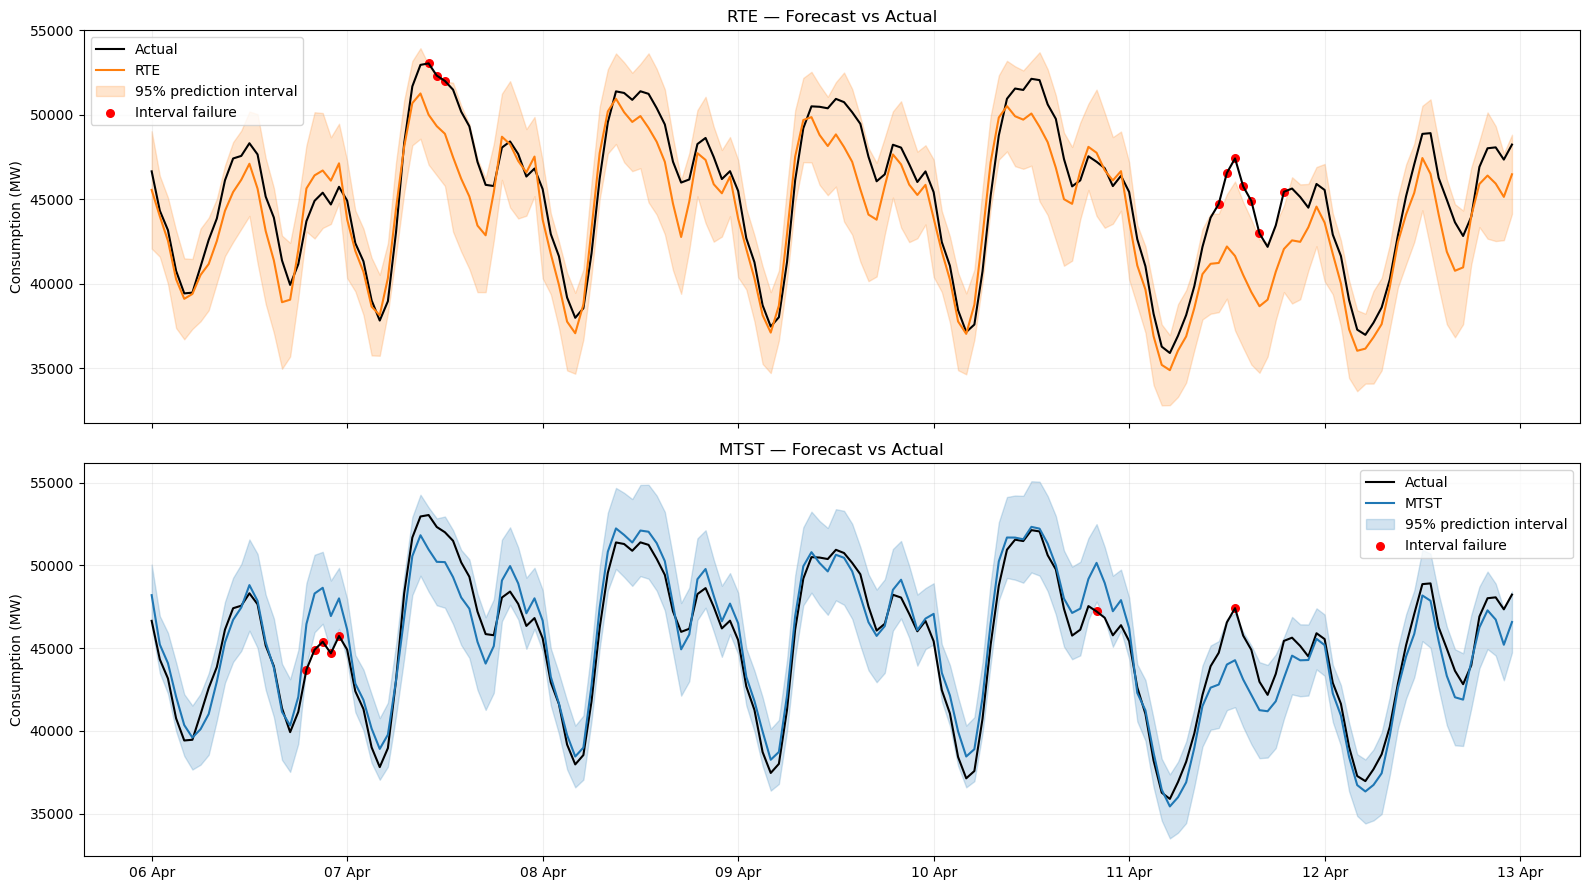

In [74]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Une semaine représentative
start = pd.Timestamp("2026-04-06", tz="Europe/Paris")
end = start + pd.DateOffset(days=7)

plot = evaluation.copy()
plot.index = plot.index.tz_convert("Europe/Paris")
plot = plot[(plot.index >= start) & (plot.index < end)]

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

for ax, (name, color) in zip(
    axes,
    [("RTE", "tab:orange"), ("MTST", "tab:blue")]
):
    ax.plot(plot.index, plot["actual"], "k", label="Actual")
    ax.plot(plot.index, plot[name], color=color, label=name)

    ax.fill_between(
        plot.index,
        plot[f"{name}_lower"],
        plot[f"{name}_upper"],
        color=color,
        alpha=0.2,
        label="95% prediction interval"
    )

    outside = (
        (plot["actual"] < plot[f"{name}_lower"]) |
        (plot["actual"] > plot[f"{name}_upper"])
    )

    ax.scatter(
        plot.index[outside],
        plot.loc[outside, "actual"],
        color="red",
        s=30,
        label="Interval failure"
    )

    ax.set_title(f"{name} — Forecast vs Actual")
    ax.set_ylabel("Consumption (MW)")
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b", tz=start.tz)
)

plt.tight_layout()
plt.show()

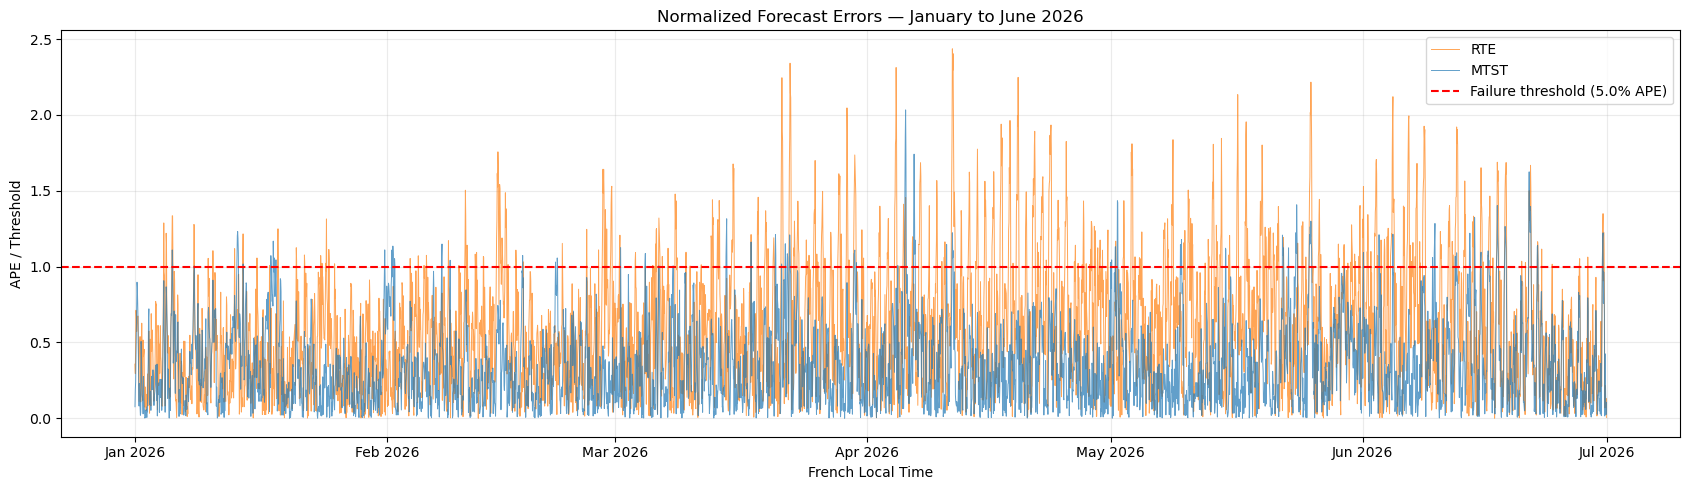

In [70]:
fig, ax = plt.subplots(figsize=(17, 5))

for name, color in [("RTE", "tab:orange"), ("MTST", "tab:blue")]:
    d = failures[name]

    ax.plot(
        d.index.tz_convert("Europe/Paris"),
        d["APE (%)"] / APE_THRESHOLD,
        color=color,
        lw=0.7,
        alpha=0.7,
        label=name
    )

ax.axhline(
    1, color="red", ls="--",
    label=f"Failure threshold ({APE_THRESHOLD}% APE)"
)

ax.set(
    title="Normalized Forecast Errors — January to June 2026",
    xlabel="French Local Time",
    ylabel="APE / Threshold"
)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(tz="Europe/Paris")
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y", tz="Europe/Paris")
)

ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()